## Imports

In [ ]:
import geopandas as gpd

#in_map_dir = '/projects/b1045/inmap/inmap_runs_final'
#gdf = gpd.read_file(f'{in_map_dir}/ladco_1km_final.shp')
counties = gpd.read_file('shapefiles/counties/tl_2024_us_county.shp')

##
## Get ChicagoLand counties shapefile (lake excluded)
##

import pandas as pd
import geopandas as gpd

chicago_counties = ['Lake', 'McHenry', 'Cook', 'Kane', 'DuPage', 'Will', 'Kendall']

il_counties = counties.loc[(counties['STATEFP'] == '17') &
			 (counties['NAME'].isin(chicago_counties))]

# # Lake County, Indiana
# lake_in = counties.loc[
#     (counties['STATEFP'] == '18') &
#     (counties['NAME'] == 'Lake')
# ]

# combine
chicago_counties_gdf = gpd.GeoDataFrame(
    pd.concat([il_counties], ignore_index=True),
    crs=counties.crs
)
import cartopy.feature as cfeature
import shapely.geometry as sg

# --- 1️⃣ Natural Earth lakes feature ---
resol = '10m'  # can also be '50m' or '110m'
lakes_feat = cfeature.NaturalEarthFeature(
    'physical', 'lakes', scale=resol,
    edgecolor='black', facecolor=cfeature.COLORS['water']
)

# --- 2️⃣ Convert lakes to GeoDataFrame ---
lakes_gdf = gpd.GeoDataFrame(
    geometry=[geom for geom in lakes_feat.geometries()],
    crs=chicago_counties_gdf.crs
)

# --- 3️⃣ Clip the counties to remove the lake ---
chicago_counties_land = gpd.overlay(
    chicago_counties_gdf,
    lakes_gdf,
    how='difference'
)




In [ ]:
in_map_dir = '/projects/b1045/inmap/inmap_runs_final'
counties = gpd.read_file('shapefiles/counties/tl_2024_us_county.shp')

def prep_chicago_gdf(inmap_gdf, chicago_counties_gdf):
	chicago_counties_gdf.to_crs(inmap_gdf.crs)

	# union into one boundary
	chicago_boundary = chicago_counties_gdf.geometry.unary_union

	# clip gdf to boundary (cuts edges)
	inmap_gdf_chicago = gpd.clip(inmap_gdf, chicago_boundary)

	return inmap_gdf_chicago

resolutions = ['1', '1_3', '4']
emissions_inventories = ['ladco', 'five', 'nemo', 'uvm']

# nested dict: gdfs[res][emis_inv] = GeoDataFrame
gdfs_dict = {}

for res in resolutions:
    gdfs_dict[res] = {}

    for emis_inv in emissions_inventories:
        if emis_inv == "five" and res == "1_3":
            path = f'{in_map_dir}/{emis_inv}_{res}_km_final.shp'
        else:
            path = f'{in_map_dir}/{emis_inv}_{res}km_final.shp'

        print(path)
        gdf = gpd.read_file(path)
        gdf_chicago = prep_chicago_gdf(gdf, chicago_counties_land)

        gdfs_dict[res][emis_inv] = gdf_chicago


In [ ]:
## Emissions imports
counties = gpd.read_file('shapefiles/counties/tl_2024_us_county.shp')

def prep_chicago_gdf(inmap_gdf, chicago_counties_gdf):
	chicago_counties_gdf.to_crs(inmap_gdf.crs)

	# union into one boundary
	chicago_boundary = chicago_counties_gdf.geometry.unary_union

	# clip gdf to boundary (cuts edges)
	inmap_gdf_chicago = gpd.clip(inmap_gdf, chicago_boundary)

	return inmap_gdf_chicago
emissions_dir = '/projects/b1045/vlang/2025_ESandT_EmissionIntercomparisonPaper'

resolutions = ['1', '1_3', '4']
resolution_suffixes = {'1':'1km_cons_annual', 
					   '1_3':'1_33km_cons_annual_peryear',
					   '4':'4km_cons'}
emissions_inventories = ['ladco', 'five', 'nemo', 'uvm']

# nested dict: gdfs[res][emis_inv] = GeoDataFrame
emissions_gdfs_dict = {}

for res in resolutions:
    emissions_gdfs_dict[res] = {}

    for emis_inv in emissions_inventories:
        path = f'{emissions_dir}/{emis_inv}_{resolution_suffixes[res]}.shp'

        print(path)
        gdf = gpd.read_file(path)
        gdf_chicago = prep_chicago_gdf(gdf, chicago_counties_land)

        emissions_gdfs_dict[res][emis_inv] = gdf_chicago

In [ ]:
import pickle

output_dir = "shapefiles/chicago_land_gridded"

# Save inmap grids
with open(f"{output_dir}/inmap_gdfs_dict.pkl", "wb") as f:
    pickle.dump(gdfs_dict, f)

# Save emissions grids
with open(f"{output_dir}/emissions_gdfs_dict.pkl", "wb") as f:
    pickle.dump(emissions_gdfs_dict, f)

print("Dictionaries saved.")

In [ ]:
import pickle

with open("shapefiles/chicago_land_gridded/inmap_gdfs_dict.pkl", "rb") as f:
    gdfs_dict = pickle.load(f)

# with open("processed_gdfs/emissions_gdfs_dict.pkl", "rb") as f:
#     emissions_gdfs_dict = pickle.load(f)

print("Dictionaries loaded.")


In [ ]:
from pympler import asizeof

#print(asizeof.asizeof(emissions_gdfs_dict))

print(asizeof.asizeof(gdfs_dict))

## Double check new emissions with secondaries

In [ ]:
import geopandas as gpd
import pandas as pd

dir = "/projects/b1045/vlang/2025_ESandT_EmissionIntercomparisonPaper/AllVariableShapefiles/"
# files_names = [#'nemo_1km_grid_all_variables.shp',
# 		 'ladco_1km_allvars_annual.shp',
# 		 #'five_regridded_to_1km_all_variables.shp'
# 		 ]

# # dict_gdfs = {}

# # for file in files_names:
# # 	inv = file.split('_')[0]
# # 	gdf = gpd.read_file(f"{dir}/{file}")
# # 	dict_gdfs[inv] = gdf

inv = 'ladco'
ladco = gpd.read_file(f"{dir}/ladco_1km_allvars_annual.shp")

In [ ]:
# 1. Change the LADCO dataset CRS to match the county shapefile
ladco_matched = ladco.to_crs(chicago_counties_land.crs)

# 2. Flatten the county polygons into a single combined boundary
chicago_boundary = chicago_counties_land.geometry.unary_union

# 3. Clip the modified LADCO grid using the boundary to isolate the domain
ladco_chicago = gpd.clip(ladco_matched, chicago_boundary)

# 4. Print the final grid count to confirm reduction
print(f"Original grid cells: {len(ladco)}")
print(f"Clipped Chicago grid cells: {len(ladco_chicago)}")

In [ ]:
ladco_chicago.to_file('ladco_chicago_secondary.shp')

In [ ]:
import geopandas as gpd
ladco_chicago = gpd.read_file("ladco_chicago_secondary.shp")

In [ ]:
import geopandas as gpd

def process_ladco_for_inmap(gdf):
    """
    Processes a LADCO GeoDataFrame by summing chemical species 
    into standard InMAP pollutant columns.
    """
    # 1. Create a copy to protect original data
    processed_gdf = gdf.copy()
    
    # 2. Sum VOC species (excluding CO, CO2, and CH4)
    voc_species = [
        'ACET', 'ACROLEIN', 'ALD2', 'ALD2_PRIMA', 'ALDX', 'BENZ', 'BUTADIENE1', 
        'ETH', 'ETHA', 'ETHY', 'ETOH', 'FORM', 'FORM_PRIMA', 'IOLE', 'ISOP', 
        'KET', 'MEOH', 'NAPH', 'OLE', 'PRPA', 'TERP', 'TOL', 'UNK', 'UNR', 
        'PAR', 'SOAALK'
    ]
    # Filter to only use columns that actually exist in your data
    existing_voc = [col for col in voc_species if col in processed_gdf.columns]
    processed_gdf['VOC'] = processed_gdf[existing_voc].sum(axis=1)
    
    # 3. Sum NOx species
    processed_gdf['NOx'] = processed_gdf['NO'] + processed_gdf['NO2']
    
    # 4. Sum fine particulate matter (PM2.5) species 
    # (Note: PMC is coarse mass, so it is excluded)
    pm25_species = [
        'PEC', 'POC', 'PSO4', 'PNO3', 'PNH4', 'PFE', 'PCL', 'PNA', 'PTI', 
        'PAL', 'PCA', 'PH2O', 'PK', 'PMG', 'PMN', 'PMOTHR', 'PNCOM', 'PSI'

		
    ]
    existing_pm25 = [col for col in pm25_species if col in processed_gdf.columns]
    processed_gdf['PM25'] = processed_gdf[existing_pm25].sum(axis=1)
    
    # 5. Select only the columns required by InMAP
    inmap_cols = ['row', 'col', 'geometry', 'VOC', 'NOx', 'PM25', 'NH3', 'SO2']
    inmap_gdf = processed_gdf[inmap_cols]
    
    return inmap_gdf

# --- How to run it in your script ---
# Assuming your original data is called 'ladco_gdf':
# ready_for_inmap = process_ladco_for_inmap(ladco_gdf)
# ready_for_inmap.to_file("inmap_emissions.geojson", driver="GeoJSON")
ladco_mod = process_ladco_for_inmap(ladco_chicago)

In [ ]:
def plot_spatial( gdf, chicago_counties_land, column_name, cmap="viridis" ):
    """ Plot a spatial field from a GeoDataFrame. """
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    pollutant_label = column_name
    unit = "tons/year"
    label = pollutant_label + " " + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97, 
        central_latitude=40, 
        standard_parallels=(33, 45)
    )

    # ---- define range limits ----
    data_min = gdf[column_name].min()
    data_max = 40

    # ---- figure ----
    fig, ax = plt.subplots(
        figsize=(6, 6), 
        subplot_kw={"projection": target_proj}, 
        constrained_layout=True, 
        dpi=200
    )
    
    # UPDATED: Added vmin and vmax here so the map data matches the colorbar scaling
    gdf.plot(
        column=column_name,
        ax=ax,
        transform=target_proj,
        cmap=cmap,
        vmin=data_min,
        vmax=data_max,
        edgecolor="none",
        linewidth=0,
        antialiased=False,
        rasterized=True,
        legend=False
    )

    chicago_counties_land.boundary.plot(
        ax=ax, 
        transform=target_proj, 
        color="black", 
        linewidth=0.6
    )
    ax.set_title(pollutant_label, fontsize=16)
    ax.set_axis_off()

    # ---- colorbar ----
    # UPDATED: Realigned colorbar map normalized values
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(
            norm=plt.Normalize(vmin=data_min, vmax=data_max), 
            cmap=cmap
        ),
        ax=ax, 
        orientation="vertical", 
        fraction=0.035, 
        pad=0.02
    )
    cbar.set_label(label, fontsize=14)
    cbar.ax.tick_params(labelsize=12)
    
    plt.show()


plot_spatial(ladco_chicago, chicago_counties_land = chicago_counties_land, column_name ='NOX', cmap = 'viridis')

In [ ]:
ladco_chicago['PM25'].sum()

## Easy dict imports

In [1]:
import geopandas as gpd
import pandas as pd

#in_map_dir = '/projects/b1045/inmap/inmap_runs_final'
#gdf = gpd.read_file(f'{in_map_dir}/ladco_1km_final.shp')
counties = gpd.read_file('shapefiles/counties/tl_2024_us_county.shp')

##
## Get ChicagoLand counties shapefile (lake excluded)
##


chicago_counties = ['Lake', 'McHenry', 'Cook', 'Kane', 'DuPage', 'Will', 'Kendall']

il_counties = counties.loc[(counties['STATEFP'] == '17') &
			 (counties['NAME'].isin(chicago_counties))]

# # Lake County, Indiana
# lake_in = counties.loc[
#     (counties['STATEFP'] == '18') &
#     (counties['NAME'] == 'Lake')
# ]

# combine
chicago_counties_gdf = gpd.GeoDataFrame(
    pd.concat([il_counties], ignore_index=True),
    crs=counties.crs
)
import cartopy.feature as cfeature
import shapely.geometry as sg

# --- 1️⃣ Natural Earth lakes feature ---
resol = '10m'  # can also be '50m' or '110m'
lakes_feat = cfeature.NaturalEarthFeature(
    'physical', 'lakes', scale=resol,
    edgecolor='black', facecolor=cfeature.COLORS['water']
)

# --- 2️⃣ Convert lakes to GeoDataFrame ---
lakes_gdf = gpd.GeoDataFrame(
    geometry=[geom for geom in lakes_feat.geometries()],
    crs=chicago_counties_gdf.crs
)

# --- 3️⃣ Clip the counties to remove the lake ---
chicago_counties_land = gpd.overlay(
    chicago_counties_gdf,
    lakes_gdf,
    how='difference'
)
census_tracts_chicago_race = pd.read_pickle('shapefiles/census_tract/census_tracts_chicago_race.pkl')




In [2]:
import pickle

with open("shapefiles/chicago_land_gridded/emissions_gdfs_dict.pkl", "rb") as f:
    emissions_gdfs_dict = pickle.load(f)

with open("shapefiles/rerun/inmap_gdfs_dict.pkl", "rb") as f:
    gdfs_dict = pickle.load(f)
     
with open(f"shapefiles/rerun/conc_gdfs_dict.pkl", "rb") as f:
    conc_census_gdfs_dict = pickle.load(f)

with open(f"shapefiles/census_tract/emissions_gdfs_dict.pkl", "rb") as f:
    emis_census_gdfs_dict = pickle.load(f)

with open(f"shapefiles/rerun/mortalities_dfs.pkl", "rb") as f:
    attributable_mortality_dict = pickle.load(f)

with open("shapefiles/secondary_pm/secondary_pm_concentrations.pkl", "rb") as f:
    secondary_conc = pickle.load(f)

with open("shapefiles/secondary_pm/tract_concentrations.pkl", "rb") as f:
    secondary_tract = pickle.load(f)

print("Dictionaries loaded.")

Dictionaries loaded.


In [3]:
for outer_dict in [
    emissions_gdfs_dict,
    gdfs_dict,
    conc_census_gdfs_dict,
    emis_census_gdfs_dict,
    attributable_mortality_dict
]:
    for key, val in outer_dict.items():
        if isinstance(val, dict) and 'ladco' in val:
            val['ladco-nu'] = val.pop('ladco')

In [4]:
resolutions = ['1', '1_3', '4']
emissions_inventories = ['ladco-nu', 'five', 'nemo', 'uvm']

# Concentrations Plots

## Grid

### Inmap grid shapefiles

In [ ]:
inmap_grid = gpd.read_file('shapefiles/InMAP Grid/InMAP_grid.shp')

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Lambert Conformal projection
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45),
)

fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"projection": target_proj},
    constrained_layout=True,
    dpi= 600
)

# Plot grid outlines only
inmap_grid.boundary.plot(
    ax=ax,
    transform=target_proj,
    color="black",
    linewidth=0.4
)

ax.set_title("InMAP Grid Outlines", fontsize=18)
ax.set_axis_off()

plt.show()

In [ ]:
chicago_counties_proj = chicago_counties_land.to_crs(inmap_grid.crs)

In [ ]:
# assuming chicago_counties_land is your counties GeoDataFrame
chicago_grid = gpd.clip(inmap_grid, chicago_counties_proj)


In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Lambert Conformal projection
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)
fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"projection": target_proj},
    constrained_layout=True,
	dpi = 300
)

# Grid outlines
chicago_grid.boundary.plot(
    ax=ax,
    transform=target_proj,
    color="black",
    linewidth=0.4
)

# County boundaries for context
chicago_counties_proj.boundary.plot(
    ax=ax,
    transform=target_proj,
    color="red",
    linewidth=0.8
)

ax.set_title("InMAP Grid Over Chicago Counties", fontsize=16)
ax.set_axis_off()

plt.show()


In [ ]:
# Spatial join to keep cells that touch any county
chicago_grid_touching = inmap_grid[inmap_grid.intersects(chicago_counties_proj.unary_union)]

# Cell area in m² and km²
chicago_grid_touching["area_m2"] = chicago_grid_touching.geometry.area
chicago_grid_touching["area_km2"] = chicago_grid_touching["area_m2"] / 1e6
chicago_grid_touching["resolution_km"] = chicago_grid_touching["area_km2"] ** 0.5


grid_counts = chicago_grid_touching.groupby("resolution_km").size().reset_index(name="cell_count")
grid_counts


### Inmap shapefile outputs are uniform resolution

In [ ]:
import geopandas as gpd

cols = ["NOx", "TotalPM25"]

gdf_round = gdf.copy()
gdf_round["NOx"] = gdf_round["NOx"].round(5)
gdf_round["TotalPM25"] = gdf_round["TotalPM25"].round(5)

gdf_merged = gdf_round.dissolve(by=["NOx", "TotalPM25"], as_index=False)


In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)

fig, ax = plt.subplots(
    figsize=(6, 6),
    subplot_kw={"projection": target_proj},
    constrained_layout=True
)

# merged grid outlines
gdf_merged.boundary.plot(
    ax=ax,
    transform=target_proj,
    color="black",
    linewidth=0.5
)

# county boundaries
chicago_counties_land.boundary.plot(
    ax=ax,
    transform=target_proj,
    color="white",
    linewidth=0.6
)

ax.set_title("Merged gridcells with identical pollution", fontsize=18)
ax.set_axis_off()

plt.show()


In [ ]:
def plot_grid_outlines(
    gdf,
    chicago_counties_land,
    title="Grid cell outlines",
    linecolor="black",
    linewidth=0.4,
):
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    fig, ax = plt.subplots(
        figsize=(6, 6),
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    # grid outlines only
    gdf.boundary.plot(
        ax=ax,
        transform=target_proj,
        color=linecolor,
        linewidth=linewidth
    )

    # county boundaries for context
    chicago_counties_land.boundary.plot(
        ax=ax,
        transform=target_proj,
        color="white",
        linewidth=0.6
    )

    ax.set_title(title, fontsize=18)
    ax.set_axis_off()

    plt.show()

plot_grid_outlines(
    gdf,
    chicago_counties_land,
    title="grid"
)


## Compare Resolution for Each

In [ ]:
def plot_spatial_comparison(gdfs, 
                            chicago_counties_land,
                            emissions_inventory = 'LADCO',
                            column_name = "TotalPM25",
                            res_labels = ['1 km', '1.3 km', '4 km']):
    
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + unit

    if column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + ' ' + unit

    
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )


    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(14, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    vmin = min(gdf[column_name].min() for gdf in gdfs)
    vmax = max(gdf[column_name].max() for gdf in gdfs)

    for ax, gdf, res_label in zip(axes, gdfs, res_labels):

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="viridis",
            edgecolor="none",
            vmin = vmin,
            vmax = vmax,
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        # county boundaries
        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="white",
            linewidth=0.6
        )

        ax.set_title(res_label, fontsize=18)
        ax.set_axis_off()
        

    # shared colorbar
    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    fig.suptitle(f"{emissions_inventory} {pollutant}", fontsize=18)

    plt.show()


In [ ]:

resolutions = ['1', '1_3', '4']
emissions_inventories = ['ladco', 'five', 'nemo', 'uvm']

for emis_inv in emissions_inventories:
	gdfs = []

	for res in resolutions:
		gdfs.append(gdfs_dict[res][emis_inv])

	for pollutant in ['TotalPM25']:

		plot_spatial_comparison(gdfs, 
							chicago_counties_land, 
							emissions_inventory = emis_inv.upper(),
							column_name=pollutant)



## Compare Res for each Emissions inventory

In [ ]:
from matplotlib.colors import SymLogNorm

def plot_diff_by_resolution_log(diff_gdfs, chicago_counties_land, column_name, res_labels, linthresh=0.1):
    """
    Same as plot_diff_by_resolution but uses a symmetric log color scale (SymLogNorm)
    
    Parameters
    ----------
    linthresh : float
        Range around zero that remains linear.
    """
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import numpy as np

    # ---- labels ----
    if column_name == "TotalPM25":
        pollutant_label = "PM$_{2.5}$"
        unit = "($\\mu$g/m$^{3}$)"
    elif column_name == "NOx":
        pollutant_label = "NO$_{x}$"
        unit = "($\\mu$g/m$^{3}$)"
    else:
        pollutant_label = column_name
        unit = ""

    label = pollutant_label + " diff " + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- symmetric color limits across all resolutions ----
    max_abs = max(np.abs(gdf[column_name]).max() for gdf in diff_gdfs)
    norm = SymLogNorm(linthresh=linthresh, linscale=1.0, vmin=-max_abs, vmax=max_abs)

    # ---- create figure ----
    n_res = len(diff_gdfs)
    fig, axes = plt.subplots(
        nrows=1,
        ncols=n_res,
        figsize=(5*n_res, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    if n_res == 1:
        axes = [axes]

    for ax, gdf, res_label in zip(axes, diff_gdfs, res_labels):
        gdf.plot(
            column=column_name,
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="RdBu",
            norm=norm,
            edgecolor="none",
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            color="black",
            linewidth=0.6
        )

        ax.set_title(res_label, fontsize=16)
        ax.set_axis_off()

    # shared colorbar
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap="RdBu"),
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    fig.suptitle(f"{pollutant_label} difference from mean (SymLog)", fontsize=18)
    plt.show()


In [ ]:
import geopandas as gpd
from functools import reduce

def intersect_grids(gdfs):
    """
    Take a list of GeoDataFrames and return a new GeoDataFrame
    that contains the intersection of all geometries.
    """
    gdf_intersect = gdfs[0]
    for gdf in gdfs[1:]:
        gdf_intersect = gpd.overlay(gdf_intersect, gdf, how="intersection")
    return gdf_intersect


def compute_spatial_mean(intersect_gdf, column_names):
    """
    Compute the mean of each pollutant across overlapping geometries.
    `intersect_gdf` must have columns from each original grid, e.g., TotalPM25_1, TotalPM25_2, etc.
    """
    # Take the mean across the columns
    intersect_gdf["spatial_mean"] = intersect_gdf[column_names].mean(axis=1)
    return intersect_gdf

def diff_from_spatial_mean(original_gdf, mean_gdf, column_name):
    """
    Compute difference from spatial mean for each polygon in original_gdf.
    original_gdf: GeoDataFrame of a resolution
    mean_gdf: GeoDataFrame with intersected polygons and spatial_mean column
    """
    # overlay original with mean polygons
    overlay_gdf = gpd.overlay(original_gdf, mean_gdf[["geometry", "spatial_mean"]], how="intersection")

    # difference from mean
    overlay_gdf[column_name] = overlay_gdf[column_name] - overlay_gdf["spatial_mean"]

    return overlay_gdf


def prep_diff_gdfs_spatial_mean(gdfs, column_name):
    """
    Compute difference from the spatial mean across resolutions.
    
    Parameters
    ----------
    gdfs : list of GeoDataFrames
        Each element corresponds to one resolution for the same inventory & pollutant.
    column_name : str
        Name of the column to compute difference from mean.
    
    Returns
    -------
    diff_gdfs : list of GeoDataFrames
        Each input gdf replaced by difference-from-spatial-mean column.
    """
    # Step 1: intersect all grids
    from functools import reduce
    intersect_gdf = reduce(lambda x, y: gpd.overlay(x, y, how="intersection"), gdfs)
    
    # Step 2: compute spatial mean
    # Create a list of columns from each resolution
    mean_columns = []
    for i, gdf in enumerate(gdfs):
        col_name = f"{column_name}_{i}"
        intersect_gdf[col_name] = intersect_gdf[column_name + f"_{i}" if column_name + f"_{i}" in intersect_gdf.columns else column_name]
        mean_columns.append(col_name)
    intersect_gdf["spatial_mean"] = intersect_gdf[mean_columns].mean(axis=1)
    
    # Step 3: compute difference for each resolution
    diff_gdfs = []
    for i, gdf in enumerate(gdfs):
        # overlay original with intersected polygons to assign spatial_mean
        overlay_gdf = gpd.overlay(gdf, intersect_gdf[["geometry", "spatial_mean"]], how="intersection")
        overlay_gdf[column_name] = overlay_gdf[column_name] - overlay_gdf["spatial_mean"]
        diff_gdfs.append(overlay_gdf)
    
    return diff_gdfs


def plot_diff_by_resolution(diff_gdfs, chicago_counties_land, column_name, res_labels, emis_inv, vmax = 1):
    """
    Plot difference-from-mean for a single pollutant and single emissions inventory
    across multiple resolutions in one figure.
    
    Parameters
    ----------
    diff_gdfs : list of GeoDataFrames
        Each element corresponds to one resolution.
    chicago_counties_land : GeoDataFrame
        County boundaries for context.
    column_name : str
        Pollutant name, e.g., 'TotalPM25' or 'NOx'.
    res_labels : list of str
        Labels for each resolution, e.g., ['1 km', '1.3 km', '4 km'].
    """
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import numpy as np

    # ---- labels ----
    if column_name == "TotalPM25":
        pollutant_label = "PM$_{2.5}$"
        unit = "($\\mu$g/m$^{3}$)"
    elif column_name == "NOx":
        pollutant_label = "NO$_{x}$"
        unit = "($\\mu$g/m$^{3}$)"
    else:
        pollutant_label = column_name
        unit = ""

    label = pollutant_label + " diff " + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- symmetric color limits across all resolutions ----
    vmin = -vmax

    # ---- create figure ----
    n_res = len(diff_gdfs)
    fig, axes = plt.subplots(
        nrows=1,
        ncols=n_res,
        figsize=(5*n_res, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    # if only one subplot, make axes iterable
    if n_res == 1:
        axes = [axes]

    for ax, gdf, res_label in zip(axes, diff_gdfs, res_labels):
        gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,  # correct for lat/lon data
            cmap="RdBu",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        # county boundaries
        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.6
        )

        ax.set_title(res_label, fontsize=16)
        ax.set_axis_off()

    # shared colorbar
    cbar = fig.colorbar(
        ax.collections[0] if n_res == 1 else axes[0].collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    fig.suptitle(f"{emis_inv} {pollutant_label} difference from mean", fontsize=18)
    plt.show()


In [ ]:

# ---- collect ALL diff_gdfs first ----
all_diff = []

for inventory in emissions_inventories:
    gdfs_res = [
        gdfs_dict[res][inventory][[pollutant, "geometry"]].copy()
        for res in resolutions
    ]

    diff_gdfs = prep_diff_gdfs_spatial_mean(gdfs_res, column_name=pollutant)
    all_diff.append(diff_gdfs)


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

pollutant = "TotalPM25"

# ---- projection ----
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)

# ---- consistent color scale ----
vmax = 0.3
vmin = -vmax

# ---- figure ----
n_rows = len(emissions_inventories)
n_cols = len(resolutions)

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(5*n_cols, 4*n_rows),
    subplot_kw={"projection": target_proj},
    constrained_layout=True,
    dpi = 300
)

# ensure 2D axes
if n_rows == 1:
    axes = np.array([axes])

# ---- labels ----
res_labels = ["1.3 km" if r == "1_3" else f"{r} km" for r in resolutions]

# ---- plotting ----
for i, (inventory, diff_gdfs) in enumerate(zip(emissions_inventories, all_diff)):
    for j, (gdf, res_label) in enumerate(zip(diff_gdfs, res_labels)):

        ax = axes[i, j]

        gdf.plot(
            column=pollutant,
            ax=ax,
            transform=target_proj,
            cmap="RdBu_r",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            rasterized=True,
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.6
        )

        # ---- titles ----
        if i == 0:
            ax.set_title(res_label, fontsize=18)

        if j == 0:
            ax.text(
                -0.05, 0.5,
                inventory.upper(),
                transform=ax.transAxes,
                rotation=90,
                va='center',
                ha='right',
                fontsize=18
            )

        ax.set_axis_off()

# ---- shared colorbar ----
cbar = fig.colorbar(
    axes[0, 0].collections[0],
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.02,
    extend='both'
)

cbar.set_label("PM$_{2.5}$ diff ($\\mu$g/m$^{3}$)", fontsize=18)
cbar.ax.tick_params(labelsize=18)

# ---- title ----
#fig.suptitle("PM$_{2.5}$ Difference from Spatial Mean", fontsize=18)

plt.show()

## Compare Emissions Inventories for each res

In [ ]:
def prep_chicago_gdf(inmap_gdf, chicago_counties_gdf):
	chicago_counties_gdf.to_crs(inmap_gdf.crs)

	# union into one boundary
	chicago_boundary = chicago_counties_gdf.geometry.unary_union

	# clip gdf to boundary (cuts edges)
	inmap_gdf_chicago = gpd.clip(inmap_gdf, chicago_boundary)

	return inmap_gdf_chicago

In [ ]:
def plot_emissions_comparison(gdfs, 
                            chicago_counties_land,
                            res = '1 km',
                            column_name = "TotalPM25",
                            emissions_labels = emissions_inventories):
    
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + unit

    if column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + ' ' + unit

    
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )


    fig, axes = plt.subplots(
        nrows=1,
        ncols=4,
        figsize=(14, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi = 300
    )

    vmin = min(gdf[column_name].min() for gdf in gdfs)
    vmax = max(gdf[column_name].max() for gdf in gdfs)

    for ax, gdf, emis_label in zip(axes, gdfs, emissions_labels):

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="viridis",
            edgecolor="none",
            vmin = vmin,
            vmax = vmax,
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        # county boundaries
        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="white",
            linewidth=0.6
        )

        ax.set_title(emis_label.upper(), fontsize=18)
        ax.set_axis_off()
        

    # shared colorbar
    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    fig.suptitle(f"{res} {pollutant}", fontsize=18)

    plt.show()

def prep_diff_gdfs(gdfs, column_name):
    import pandas as pd
    import geopandas as gpd

    # concatenate
    gdf_all = pd.concat(gdfs, ignore_index=True)

    # take mean across inventories (grouped by geometry)
    gdf_mean = (
        gdf_all
        .groupby(gdf_all.geometry)
        .mean(numeric_only=True)
        .reset_index()
    )

    # turn back into GeoDataFrame
    gdf_mean = gpd.GeoDataFrame(gdf_mean, geometry='geometry', crs=gdfs[0].crs)

    # ensure CRS consistency
    for i in range(len(gdfs)):
        if gdfs[i].crs != gdf_mean.crs:
            gdfs[i] = gdfs[i].to_crs(gdf_mean.crs)

    # set geometry as index for alignment
    gdf_mean_idx = gdf_mean.set_index("geometry")

    gdfs_idx = [
        gdf.set_index("geometry")
        for gdf in gdfs
    ]

    diff_gdfs = []

    for gdf in gdfs_idx:
        diff = gdf.copy()
        diff[column_name] = diff[column_name] - gdf_mean_idx[column_name]
        diff = diff.reset_index()
        diff_gdfs.append(
            gpd.GeoDataFrame(diff, geometry="geometry", crs=gdf_mean.crs)
        )
    return diff_gdfs

def plot_emissions_diff_from_mean(diff_gdfs,
                                  chicago_counties_land,
                                  res='1 km',
                                  column_name="TotalPM25",
                                  emissions_labels=emissions_inventories):

    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/m$^{3}$)'

    label = pollutant + ' diff ' + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- symmetric color limits ----
    max_abs = max(
        np.abs(gdf[column_name]).max()
        for gdf in diff_gdfs
    )
    vmin, vmax = -max_abs, max_abs

    fig, axes = plt.subplots(
        nrows=1,
        ncols=4,
        figsize=(14, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    for ax, gdf, emis_label in zip(axes, diff_gdfs, emissions_labels):

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=ccrs.PlateCarree(),  # ✅ correct
            cmap="RdBu",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            color="black",
            linewidth=0.6
        )

        ax.set_title(emis_label.upper(), fontsize=18)
        ax.set_axis_off()

    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    fig.suptitle(f"{res} {pollutant} difference from mean", fontsize=18)

    plt.show()


In [ ]:
def plot_diff_grid_all_resolutions(
    all_data,
    resolutions,
    emissions_inventories,
    chicago_counties_land,
    column_name="TotalPM25"
):
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = ''

    label = pollutant + ' diff ' + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- global color scale ----
    max_abs = max(
        np.abs(gdf[column_name]).max()
        for row in all_data
        for gdf in row
    )
    vmin, vmax = -0.45, 0.45

    # ---- figure ----
    n_rows = len(resolutions)
    n_cols = len(emissions_inventories)

    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(4*n_cols, 5*n_rows),
        dpi=300,
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    # ensure 2D indexing
    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes[:, np.newaxis]

    # ---- resolution labels ----
    res_labels = []
    for res in resolutions:
        if res == "1_3":
            res_labels.append("1.3 km")
        else:
            res_labels.append(f"{res} km")

    # ---- plotting ----
    for i, (res, row) in enumerate(zip(res_labels, all_data)):
        for j, (emis, gdf) in enumerate(zip(emissions_inventories, row)):

            ax = axes[i, j]

            gdf.plot(
                column=column_name,
                ax=ax,
                transform=target_proj,
                cmap="RdBu_r",
                vmin=vmin,
                vmax=vmax,
                edgecolor="none",
                linewidth=0,
                rasterized=True
            )

            chicago_counties_land.boundary.plot(
                ax=ax,
                transform=target_proj,
                color="black",
                linewidth=0.6
            )

            # ---- column titles (top row) ----
            if i == 0:
                ax.set_title(emis.upper(), fontsize=18)

            # ---- row labels (left column) ----
            if j == 0:
                ax.text(
                    -0.08, 0.5,
                    res,
                    transform=ax.transAxes,
                    rotation=90,
                    va='center',
                    ha='right',
                    fontsize=18
                )

            ax.set_axis_off()

    # ---- shared colorbar ----
    mappable = axes[0, 0].collections[0]

    cbar = fig.colorbar(
        mappable,
        ax=axes,
        orientation="vertical",
        fraction=0.03,
        pad=0.02,
        extend = 'both'
    )

    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    # ---- title ----
    fig.suptitle(f"{pollutant} Difference from Mean", fontsize=18)

    plt.show()

In [ ]:
column_name = "TotalPM25"
emissions_inventories = ['ladco-nu', 'five', 'nemo', 'uvm']

# ---- compute all diff_gdfs first ----
all_data_diff_data = []  # shape: [res][inventory]
resolutions = ['1', '1_3', '4']
for res in resolutions:
    gdfs = [gdfs_dict[res][emis] for emis in emissions_inventories]
    diff_gdfs = prep_diff_gdfs(gdfs, column_name=column_name)
    all_data_diff_data.append(diff_gdfs)


    # # optional comparisons
    # plot_emissions_comparison(gdfs, chicago_counties_land, res=res_label, column_name='TotalPM25')
    # plot_emissions_comparison(gdfs, chicago_counties_land, res=res_label, column_name='NOx')


In [ ]:
plot_diff_grid_all_resolutions(
    all_data_diff_data,
    resolutions,
    emissions_inventories,
    chicago_counties_land,
    column_name="TotalPM25"
)

## Figure 1 Plot 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def white_magma_r():
    base = plt.cm.magma_r

    n = 256
    colors = base(np.linspace(0, 1, n))

    # create a smooth fade-in from white to first magma color
    white = np.array([1, 1, 1, 1])
    ramp_n = 40  # controls how quickly white fades into magma

    ramp = np.linspace(0, 1, ramp_n)
    for i, t in enumerate(ramp):
        colors[i] = (1 - t) * white + t * colors[ramp_n]

    return LinearSegmentedColormap.from_list(
        "white_magma_r",
        colors
    )

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def white_viridis_r():
    base = plt.cm.viridis_r  # or plt.cm.viridis if you prefer forward

    n = 256
    colors = base(np.linspace(0, 1, n))

    # smooth fade from white into viridis
    white = np.array([1, 1, 1, 1])
    ramp_n = 30  # controls fade length

    ramp = np.linspace(0, 1, ramp_n)
    for i, t in enumerate(ramp):
        colors[i] = (1 - t) * white + t * colors[ramp_n]

    return LinearSegmentedColormap.from_list(
        "white_viridis_r",
        colors
    )

In [ ]:
def white_inferno_r():
    base = plt.cm.inferno_r

    n = 256
    colors = base(np.linspace(0, 1, n))

    # smooth fade from white into inferno
    white = np.array([1, 1, 1, 1])
    ramp_n = 60  # controls how long the white transition is

    ramp = np.linspace(0, 1, ramp_n)
    for i, t in enumerate(ramp):
        colors[i] = (1 - t) * white + t * colors[ramp_n]

    return LinearSegmentedColormap.from_list(
        "white_inferno",
        colors
    )

In [ ]:


def plot_emissions_mean_from_dict(gdfs_dict,
                                 chicago_counties_land,
                                 res='1 km',
                                 column_name="TotalPM25",
                                 emissions_labels=emissions_inventories):

    import pandas as pd
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/m$^{3}$)'

    label = pollutant + ' ' + unit

    # ---- grab gdfs from dict ----
    gdfs = [gdfs_dict[res][emis] for emis in emissions_labels]

    # ---- compute mean ----
    gdf_all = pd.concat(gdfs, ignore_index=True)

    gdf_mean = (
        gdf_all
        .groupby(gdf_all.geometry)
        .mean(numeric_only=True)
        .reset_index()
    )

    gdf_mean = gpd.GeoDataFrame(
        gdf_mean,
        geometry='geometry',
        crs=gdfs[0].crs
    )

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    fig, ax = plt.subplots(
        figsize=(6, 6),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    cmap = white_magma_r()

    # ---- plot ----
    im = gdf_mean.plot(
        column=column_name,
        ax=ax,
        transform=target_proj,
        cmap=cmap,
        edgecolor="none",
        linewidth=0,
        antialiased=False,
        rasterized=True,
        legend=False,
        vmin = 0,
        vmax = 11
    )

    chicago_counties_land.boundary.plot(
        ax=ax,
        transform=target_proj,
        color="white",
        linewidth=0.6
    )

   # ax.set_title("MEAN", fontsize=18)
    ax.set_axis_off()

    # ---- colorbar ----
    cbar = fig.colorbar(
        im.collections[0],
        ax=ax,
        orientation="vertical",
        fraction=0.04,
        extend="max",   # <-- triangle at top
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    #fig.suptitle(f"{res} Bean {pollutant}", fontsize=18)
    plt.text(
        0, 0.95,
        "B",
        transform=ax.transAxes,
        ha='center',
        va='top',
        fontsize=18
    )
    plt.show()

In [ ]:
# plot_emissions_mean_from_dict(gdfs_dict,
#                                  chicago_counties_land,
#                                  res='1',
#                                  column_name="TotalPM25",
#                                  emissions_labels=emissions_inventories)

In [ ]:
def plot_diff_grid_2x2(
    all_data,  # list of 4 gdfs for one resolution
    emissions_inventories,
    chicago_counties_land,
    res="1 km",
    column_name="TotalPM25"
):
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = ''

    label = pollutant + ' diff ' + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- color scale ----
    
    max_abs = max(np.abs(gdf[column_name]).max() for gdf in all_data)




    vmin, vmax = -2, 2

    # ---- figure (2x2) ----
    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(10, 10),
        dpi=300,
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    axes = np.array(axes)

    # ---- plotting ----
    label_starts = ['A', "B", "C", "D"]
    for i in range(2):
        for j in range(2):

            idx = i * 2 + j
            ax = axes[i, j]

            gdf = all_data[idx]
            emis = emissions_inventories[idx]

            im = gdf.plot(
                column=column_name,
                ax=ax,
                transform=target_proj,
                cmap="RdBu_r",
                vmin=vmin,
                vmax=vmax,
                edgecolor="none",
                linewidth=0,
                rasterized=True
            )

            chicago_counties_land.boundary.plot(
                ax=ax,
                transform=target_proj,
                color="black",
                linewidth=0.6
            )

            ax.set_title(label_starts[idx] + ' ' + emis.upper(), fontsize=18)
            ax.set_axis_off()

    # ---- shared colorbar ----
    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02,
        extend = 'both'
    )

    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    # ---- title ----
    plt.show()

In [ ]:
# plot_diff_grid_2x2(
#     all_data_diff_data[0],  # list of 4 gdfs for one resolution
#     emissions_inventories,
#     chicago_counties_land,
#     res="1 km",
#     column_name="TotalPM25"
# )

In [ ]:
def plot_combined_diff_and_mean(
    all_data,
    gdfs_dict,
    chicago_counties_land,
    emissions_inventories,
    res="1 km",
    column_name="TotalPM25"
):
    import pandas as pd
    import geopandas as gpd
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_x$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = ''

    diff_label = pollutant + ' diff ' + unit
    mean_label = pollutant + ' ' + unit

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- compute mean ----
    gdfs = [gdfs_dict[res][emis] for emis in emissions_inventories]
    gdf_all = pd.concat(gdfs, ignore_index=True)

    gdf_mean = (
        gdf_all.groupby(gdf_all.geometry)
        .mean(numeric_only=True)
        .reset_index()
    )

    gdf_mean = gpd.GeoDataFrame(
        gdf_mean,
        geometry="geometry",
        crs=gdfs[0].crs
    )

    # ---- figure layout: LEFT mean, RIGHT 2x2 diffs ----
    fig = plt.figure(figsize=(13, 8), dpi=300, constrained_layout=True)
    gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1.5])

    # ======================
    # LEFT PANEL: Mean (B)
    # ======================
    ax_mean = fig.add_subplot(gs[0], projection=target_proj)

    im_mean = gdf_mean.plot(
        column=column_name,
        ax=ax_mean,
        transform=target_proj,
        cmap=white_magma_r(),
        edgecolor="none",
        linewidth=0,
        rasterized=True,
        legend=False,
        vmin=0,
        vmax=11
    )

    chicago_counties_land.boundary.plot(
        ax=ax_mean,
        transform=target_proj,
        color="white",
        linewidth=0.6
    )

    ax_mean.set_axis_off()
    ax_mean.text(
        0.04, 1.01, "B",
        transform=ax_mean.transAxes,
        ha="left",
        va="top",
        fontsize=18,
    )

    cbar1 = fig.colorbar(
        im_mean.collections[0],
        ax=ax_mean,
        orientation="vertical",
        fraction=0.05,
        shrink = 1.2,
        pad=0.02,
        extend="max"
    )
    cbar1.set_label(mean_label, fontsize=18)
    cbar1.ax.tick_params(labelsize=18)

    # ======================
    # RIGHT PANEL: 2x2 diffs (C1-C4)
    # ======================
    right_gs = gs[1].subgridspec(2, 2)
    axes_diff = np.empty((2, 2), dtype=object)

    vmin_diff, vmax_diff = -2.5, 2.5
    labels = ["C1", "C2", "C3", "C4"]

    for i in range(2):
        for j in range(2):
            idx = i * 2 + j
            ax = fig.add_subplot(right_gs[i, j], projection=target_proj)
            axes_diff[i, j] = ax

            gdf = all_data[idx]
            emis = emissions_inventories[idx]

            im_diff = gdf.plot(
                column=column_name,
                ax=ax,
                transform=target_proj,
                cmap="RdBu_r",
                vmin=vmin_diff,
                vmax=vmax_diff,
                edgecolor="none",
                linewidth=0,
                rasterized=True
            )

            chicago_counties_land.boundary.plot(
                ax=ax,
                transform=target_proj,
                color="black",
                linewidth=0.6
            )

            ax.set_title(
                f"{labels[idx]} {emis.upper()}",
                fontsize=18
            )
            emis = emissions_inventories[idx]
            stats = stats_dict[emis]

            ax.text(
                0.05, 0.05,
                f"Max: {stats['max']:.2f}\n"
                f"Mean: {stats['mean']:.2f}\n"
                f"IQR: {stats['iqr']:.2f}",
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=10,
                bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
            )
            ax.set_axis_off()

    cbar2 = fig.colorbar(
        im_diff.collections[0],
        ax=axes_diff.ravel().tolist(),
        orientation="vertical",
        fraction=0.048,
        shrink = 1.1,
        pad=0.02,
        extend="both"
    )
    cbar2.set_label(diff_label, fontsize=18)
    cbar2.ax.tick_params(labelsize=18)

    plt.show()

In [ ]:
def compute_stats(gdf, col):
    vals = gdf[col].dropna()
    return {
        "max": vals.max(),
        "mean": vals.mean(),
        "iqr": vals.quantile(0.75) - vals.quantile(0.25)
    }

stats_dict = {}
column_name = "TotalPM25"
for emis in emissions_inventories:
    gdf = gdfs_dict['1'][emis]
    stats_dict[emis] = compute_stats(gdf, column_name)

In [ ]:
stats_dict

In [ ]:
# plot_combined_diff_and_mean(
#     all_data=all_data_diff_data[0],
#     gdfs_dict=gdfs_dict,
#     chicago_counties_land=chicago_counties_land,
#     emissions_inventories=emissions_inventories,
#     res="1",
#     column_name="TotalPM25"
# )

In [ ]:
def plot_inventory_mean_and_diff(
    all_data,
    gdfs_dict,
    chicago_counties_land,
    emissions_inventories,
    stats_dict,
    res="1",
    column_name="TotalPM25"
):
    import pandas as pd
    import geopandas as gpd
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # -------------------
    # labels
    # -------------------
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_x$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = ''

    mean_label = pollutant + ' ' + unit
    diff_label = pollutant + ' diff ' + unit

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # -------------------
    # ensemble mean
    # -------------------
    gdfs = [gdfs_dict[res][emis] for emis in emissions_inventories]

    gdf_all = pd.concat(gdfs, ignore_index=True)

    gdf_mean = (
        gdf_all.groupby(gdf_all.geometry)
        .mean(numeric_only=True)
        .reset_index()
    )

    gdf_mean = gpd.GeoDataFrame(
        gdf_mean,
        geometry="geometry",
        crs=gdfs[0].crs
    )

    # -------------------
    # figure layout
    # -------------------
    fig = plt.figure(
        figsize=(12, 13),
        dpi=300,
        constrained_layout=True
    )

    gs = fig.add_gridspec(2, 2)

    # =========================
    # TOP LEFT: blank
    # =========================
    ax_blank = fig.add_subplot(gs[0, 0])
    ax_blank.axis("off")

    # =========================
    # TOP RIGHT: inventories (B)
    # =========================
    top_right = gs[0, 1].subgridspec(2, 2)

    inventory_axes = []

    vmin_mean = 0
    vmax_mean = 2

    for idx in range(4):

        i = idx // 2
        j = idx % 2

        ax = fig.add_subplot(
            top_right[i, j],
            projection=target_proj
        )

        inventory_axes.append(ax)

        emis = emissions_inventories[idx]
        gdf = gdfs_dict[res][emis]

        im_mean = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap=white_magma_r(),
            edgecolor="none",
            linewidth=0,
            rasterized=True,
            legend=False,
            vmin=vmin_mean,
            vmax=vmax_mean
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="white",
            linewidth=0.5
        )

        stats = stats_dict[emis]

        ax.set_title(
            emis.upper(),
            fontsize=14,
            pad=-10
        )

        ax.text(
            -0.03, -0.02,
           # f"Max: {stats['max']:.2f}\n"
           # f"Min: {stats['min']:.2f}\n"
            f"µ: {stats['mean']:.2f}\n"
            f"IQR: {stats['iqr']:.2f}\n"
            f"Max ∆: {stats['range']:.2f}",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=12
        )

        ax.set_axis_off()

    inventory_axes[0].text(
        -0.12, 1,
        "B",
        transform=inventory_axes[0].transAxes,
        fontsize=18,
        ha="left",
        va="top"
    )

    cbar1 = fig.colorbar(
        im_mean.collections[0],
        ax=inventory_axes,
        orientation="vertical",
        fraction=0.054,
        shrink=1.2,
        pad=0.015,
        extend="max"
    )

    cbar1.set_label(mean_label, fontsize=16)
    cbar1.ax.tick_params(labelsize=14)

    # =========================
    # BOTTOM LEFT: ensemble mean (C)
    # =========================
    ax_ens = fig.add_subplot(
        gs[1, 0],
        projection=target_proj
    )

    im_ens = gdf_mean.plot(
        column=column_name,
        ax=ax_ens,
        transform=target_proj,
        cmap=white_magma_r(),
        edgecolor="none",
        linewidth=0,
        rasterized=True,
        legend=False,
        vmin=vmin_mean,
        vmax=vmax_mean
    )

    chicago_counties_land.boundary.plot(
        ax=ax_ens,
        transform=target_proj,
        color="white",
        linewidth=0.6
    )


    ax_ens.text(
        -0.08, 0.975,
        "C",
        transform=ax_ens.transAxes,
        ha="left",
        va="top",
        fontsize=18
    )

    ax_ens.set_axis_off()

    # same colorbar for ensemble mean
    cbar_mean2 = fig.colorbar(
        im_ens.collections[0],
        ax=ax_ens,
        orientation="vertical",
        fraction=0.045,
        pad=0.01,
        extend="max"
    )

    cbar_mean2.set_label(mean_label, fontsize=16)
    cbar_mean2.ax.tick_params(labelsize=14)

    # =========================
    # BOTTOM RIGHT: differences (D)
    # =========================
    bottom_right = gs[1, 1].subgridspec(2, 2)

    diff_axes = []

    vmin_diff = -0.4
    vmax_diff = 0.4

    for idx in range(4):

        i = idx // 2
        j = idx % 2

        ax = fig.add_subplot(
            bottom_right[i, j],
            projection=target_proj
        )

        diff_axes.append(ax)

        gdf = all_data[idx]
        emis = emissions_inventories[idx]

        im_diff = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="RdBu_r",
            vmin=vmin_diff,
            vmax=vmax_diff,
            edgecolor="none",
            linewidth=0,
            rasterized=True
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.5
        )

        ax.set_title(
            emis.upper(),
            fontsize=14,
            pad=-3
        )

        ax.set_axis_off()

    diff_axes[0].text(
        -0.12, 1,
        "D",
        transform=diff_axes[0].transAxes,
        fontsize=18,
        ha="left",
        va="top"
    )

    cbar2 = fig.colorbar(
        im_diff.collections[0],
        ax=diff_axes,
        orientation="vertical",
        fraction=0.054,
        shrink = 1.2,
        pad=0.02,
        extend="both"
    )

    cbar2.set_label(diff_label, fontsize=16)
    cbar2.ax.tick_params(labelsize=14)
    #plt.savefig('fig1.png', dpi=300)
    plt.show()


# -------------------
# stats
# -------------------
def compute_stats(gdf, col):

    vals = gdf[col].dropna()

    return {
        #"max": vals.max(),
        #"min": vals.min(),
        "range": vals.max() - vals.min(),
        "mean": vals.mean(),
        "iqr": vals.quantile(0.75) - vals.quantile(0.25)
    }


stats_dict = {}

for emis in emissions_inventories:
    gdf = gdfs_dict['1'][emis]
    stats_dict[emis] = compute_stats(
        gdf,
        "TotalPM25"
    )


# -------------------
# run
# -------------------
plot_inventory_mean_and_diff(
    all_data=all_data_diff_data[0],
    gdfs_dict=gdfs_dict,
    chicago_counties_land=chicago_counties_land,
    emissions_inventories=emissions_inventories,
    stats_dict=stats_dict,

    res="1",
    column_name="TotalPM25"
)

In [ ]:
stats_dict = {}

for emis in emissions_inventories:
    gdf = gdfs_dict['1_3'][emis]
    stats_dict[emis] = compute_stats(
        gdf,
        "TotalPM25"
    )

def plot_inventory_mean_mean_diff_row(
    all_data,
    gdfs_dict,
    chicago_counties_land,
    emissions_inventories,
    stats_dict,
    res="1",
    column_name="TotalPM25"
):
    import pandas as pd
    import geopandas as gpd
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # -------------------
    # labels
    # -------------------
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_x$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = ''

    mean_label = pollutant + ' ' + unit
    diff_label = pollutant + ' diff ' + unit

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # -------------------
    # ensemble mean
    # -------------------
    gdfs = [gdfs_dict[res][emis] for emis in emissions_inventories]

    gdf_all = pd.concat(gdfs, ignore_index=True)

    gdf_mean = (
        gdf_all.groupby(gdf_all.geometry)
        .mean(numeric_only=True)
        .reset_index()
    )

    gdf_mean = gpd.GeoDataFrame(
        gdf_mean,
        geometry="geometry",
        crs=gdfs[0].crs
    )

    # -------------------
    # figure layout (1 x 3)
    # -------------------
    fig = plt.figure(
        figsize=(18, 6),
        dpi=300,
        constrained_layout=False
    )

    gs = fig.add_gridspec(1, 3)
    gs = fig.add_gridspec(
        1, 3,
        wspace=0.08   # tighten A–B–C spacing
    )
    # =========================================================
    # A = inventories (was B)
    # =========================================================
    gs_A = gs[0, 0].subgridspec(
        2, 2,
        wspace=-0.1,
        hspace=0.25
    )

    inventory_axes = []

    vmin_mean = 0
    vmax_mean = 2

    for idx in range(4):

        i = idx // 2
        j = idx % 2

        ax = fig.add_subplot(gs_A[i, j], projection=target_proj)
        inventory_axes.append(ax)

        emis = emissions_inventories[idx]
        gdf = gdfs_dict[res][emis]

        im_mean = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap=white_magma_r(),
            edgecolor="none",
            linewidth=0,
            rasterized=True,
            legend=False,
            vmin=vmin_mean,
            vmax=vmax_mean
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="white",
            linewidth=0.5
        )

        stats = stats_dict[emis]

        ax.set_title(
            emis.upper(),
            fontsize=14,
            pad=-10
        )

        ax.text(
            -0.15, -0.1,
            f"µ: {stats['mean']:.2f}\n"
            f"IQR: {stats['iqr']:.2f}\n"
            f"Max ∆: {stats['range']:.2f}",
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=12
        )

        ax.set_axis_off()

    inventory_axes[0].text(
        -0.12, 1,
        "A",
        transform=inventory_axes[0].transAxes,
        fontsize=18,
        ha="left",
        va="top"
    )

    cbar1 = fig.colorbar(
        im_mean.collections[0],
        ax=inventory_axes,
        orientation="vertical",
        fraction=0.054,
        shrink=1.2,
        pad=0.015,
        extend="max"
    )

    cbar1.set_label(mean_label, fontsize=16)
    cbar1.ax.tick_params(labelsize=14)

    # =========================================================
    # B = ensemble mean (was C)
    # =========================================================
    ax_B = fig.add_subplot(gs[0, 1], projection=target_proj)

    im_ens = gdf_mean.plot(
        column=column_name,
        ax=ax_B,
        transform=target_proj,
        cmap=white_magma_r(),
        edgecolor="none",
        linewidth=0,
        rasterized=True,
        legend=False,
        vmin=vmin_mean,
        vmax=vmax_mean
    )

    chicago_counties_land.boundary.plot(
        ax=ax_B,
        transform=target_proj,
        color="white",
        linewidth=0.6
    )

    ax_B.set_title(
        "Ensemble Mean",
        fontsize=14,
        pad=-10
    )

    ax_B.text(
        -0.08, 1,
        "B",
        transform=ax_B.transAxes,
        ha="left",
        va="top",
        fontsize=18
    )

    ax_B.set_axis_off()

    cbar_mean = fig.colorbar(
        im_ens.collections[0],
        ax=ax_B,
        orientation="vertical",
        fraction=0.054,
        shrink = 1.2,
        pad=0.01,
        extend="max"
    )

    cbar_mean.set_label(mean_label, fontsize=16)
    cbar_mean.ax.tick_params(labelsize=14)

    # =========================================================
    # C = diffs (was D)
    # =========================================================
    gs_C = gs[0, 2].subgridspec(       2, 2,
        wspace=-0.1,
        hspace=0.25)

    diff_axes = []

    vmin_diff = -0.4
    vmax_diff = 0.4

    for idx in range(4):

        i = idx // 2
        j = idx % 2

        ax = fig.add_subplot(gs_C[i, j], projection=target_proj)
        diff_axes.append(ax)

        gdf = all_data[idx]
        emis = emissions_inventories[idx]

        im_diff = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="RdBu_r",
            vmin=vmin_diff,
            vmax=vmax_diff,
            edgecolor="none",
            linewidth=0,
            rasterized=True
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.5
        )

        ax.set_title(
            emis.upper(),
            fontsize=14,
            pad=-3
        )

        ax.set_axis_off()

    diff_axes[0].text(
        -0.12, 1,
        "C",
        transform=diff_axes[0].transAxes,
        fontsize=18,
        ha="left",
        va="top"
    )

    cbar2 = fig.colorbar(
        im_diff.collections[0],
        ax=diff_axes,
        orientation="vertical",
        fraction=0.054,
        shrink=1.2,
        pad=0.02,
        extend="both"
    )

    cbar2.set_label(diff_label, fontsize=16)
    cbar2.ax.tick_params(labelsize=14)

    plt.show()


plot_inventory_mean_mean_diff_row(
    all_data = all_data_diff_data[1],
    gdfs_dict = gdfs_dict,
    chicago_counties_land = chicago_counties_land,
    emissions_inventories = emissions_inventories,
    stats_dict = stats_dict,
    res="1_3",
    column_name="TotalPM25"
)

In [ ]:
stats_dict = {}

for emis in emissions_inventories:
    gdf = gdfs_dict['4'][emis]
    stats_dict[emis] = compute_stats(
        gdf,
        "TotalPM25"
    )

plot_inventory_mean_mean_diff_row(
    all_data=all_data_diff_data[2],
    gdfs_dict=gdfs_dict,
    chicago_counties_land=chicago_counties_land,
    emissions_inventories=emissions_inventories,
    stats_dict=stats_dict,
    res="4",
    column_name="TotalPM25"
)

## Summary stats

In [ ]:
import pandas as pd
import numpy as np

def summarize_series(s):
    return {
        "mean": s.mean(),
        "median": s.median(),
        "std": s.std(),
        #"min": s.min(),
        "max": s.max(),
        #"q25": s.quantile(0.25),
        #"q75": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        #"n": s.notna().sum(),
    }

records = []

for res, inv_dict in gdfs_dict.items():
    for emis_inv, gdf in inv_dict.items():
        for species in ["TotalPM25"]:
            stats = summarize_series(gdf[species])

            records.append({
                "resolution": "1.3 km" if res == "1_3" else f"{res} km",
                "inventory": emis_inv,
                "species": species,
                **stats
            })

summary_df = pd.DataFrame(records)


In [ ]:
summary_df.round(2)

## Scatterplots

In [ ]:
def get_data(gdfs_dict, res, column_name):
    emis =emissions_inventories.copy()
    # stack PM2.5 values using 1 km geometry as the reference
    base_geom = gdfs_dict[res][emis[0]].geometry

    data = {}
    for e in emis:
        gdf = gdfs_dict[res][e]
        gdf = gdf.loc[gdf.geometry.isin(base_geom)]
        data[e] = gdf[column_name].to_numpy()
    return data


def scatter_plot_figure(data, column_name="TotalPM25", res_label="1"):

    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import pearsonr

    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + unit

    if column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + ' ' + unit


    import matplotlib.pyplot as plt
    import numpy as np
    from scipy.stats import pearsonr
    from matplotlib.ticker import MaxNLocator

    # 6 Unique pairs, no overlaps, organized for 3-2-1 layout
    pairs = [
        ("ladco-nu", "five"), ("uvm", "five"), ("nemo", "five"),  # Row 1 (y = five)
        ("ladco-nu", "nemo"), ("uvm", "nemo"),                   # Row 2 (y = nemo)
        ("ladco-nu", "uvm")                                      # Row 3 (y = uvm)
    ]

    fig, axes = plt.subplots(3, 3, figsize=(12, 12), constrained_layout=True)

    # Map pairs to subplot locations
    row_map = [0, 1, 2, 3, 4, 6]

    for i, (xname, yname) in enumerate(pairs):
        ax = axes.flat[row_map[i]]

        x = data[xname]
        y = data[yname]

        n_ref = 11_229          # number of gridcells in 1 km domain
        alpha_ref = 0.013
        s_ref = 30

        n = data['ladco-nu'].shape[0]

        scale = n_ref / n

        alpha = alpha_ref * scale
        s = s_ref * scale**0.3

        ax.scatter(x, y, s=s, color='purple', alpha=alpha)

        # Shared integer limits
        lim_min = np.floor(np.nanmin([x.min(), y.min()]))
        lim_max = np.ceil(np.nanmax([x.max(), y.max()]))
        lims = [lim_min, lim_max]

        # 1:1 line
        ax.plot(lims, lims, "--", color='black', linewidth=1, alpha=0.5)

        ax.set_xlim(lims)
        ax.set_ylim(lims)

        # Force identical integer ticks on both axes
        locator = MaxNLocator(integer=True, nbins=5)
        ax.xaxis.set_major_locator(locator)
        ax.yaxis.set_major_locator(locator)

        # Stats: Pearson r and slope
        r, _ = pearsonr(x, y)
        slope, intercept = np.polyfit(x, y, 1)

        ax.text(
            0.05, 0.94,
            f"r = {r:.2f}\nslope = {slope:.2f}",
            transform=ax.transAxes,
            fontsize=16,
            va='top'
        )

        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(xname.upper(), fontsize=16)
        ax.set_ylabel(yname.upper(), fontsize=16)
        ax.tick_params(labelsize=16)

    # Remove empty subplots
    for j in [5, 7, 8]:
        fig.delaxes(axes.flat[j])

    fig.suptitle(f"{res_label} domain {label}", fontsize=20)
    plt.show()



In [ ]:
for res in resolutions:
    if res == '1_3':
        res_label = '1.3 km'
    else:
        res_label = f'{res} km'

    for pollutant in ['TotalPM25']:
        data = get_data(gdfs_dict, res = res, column_name = pollutant)
        scatter_plot_figure(data, 
                column_name = pollutant, 
                res_label = res_label)

## Box and whisker plot

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

def plot_concentration_boxes(gdfs_dict, column_name,
                             resolutions=('1', '1_3', '4'),
                             models=('ladco', 'five', 'nemo', 'uvm')):

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 5), sharey=True, constrained_layout=True
    )

    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + unit

    if column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + ' ' + unit


    for ax, res in zip(axes, resolutions):
        data = []
        labels = []

        for model in models:
            if model in gdfs_dict[res]:
                vals = gdfs_dict[res][model][column_name].values
                vals = vals[np.isfinite(vals)]
                data.append(vals)
                labels.append(model.upper())

        bp = ax.boxplot(
            data,
            showfliers=False,
            widths=0.6,
            patch_artist=True,
            boxprops=dict(facecolor='white', edgecolor='black'),
            medianprops=dict(color='red', linewidth=2),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black')
        )

        # Add mean as blue dot
        means = [np.mean(d) for d in data]
        ax.scatter(
            range(1, len(means) + 1),
            means,
            color='blue',
            s=50,
            zorder=3
        )

        ax.set_title(f"{res.replace('_', '.')} km", fontsize=18)
        ax.set_xticks(range(1, len(labels) + 1))
        ax.set_xticklabels(labels, fontsize=18)
        ax.tick_params(axis='y', labelsize=18)
        ax.grid(axis='y', alpha=0.3)

    axes[0].set_ylabel(f"{label}", fontsize=18)

    # Legend (only on 3rd axis)
    legend_elements = [
        Line2D([0], [0], color='red', lw=3, label='Median'),
        Line2D([0], [0], marker='o', color='blue',
               linestyle='None', markersize=12, label='Mean')
    ]

    axes[2].legend(
        handles=legend_elements,
        loc='upper right',
        fontsize=18,
        frameon=False
    )

    fig.suptitle(
        f"Distribution of {pollutant} by Emissions Model and Resolution",
        fontsize=18
    )

    plt.show()


In [ ]:
plot_concentration_boxes(
    gdfs_dict,
    column_name="TotalPM25"
)


In [ ]:
plot_concentration_boxes(
    gdfs_dict,
    column_name="NOx"
)


## census tract concentration plot

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib import colors
import matplotlib as mpl

def plot_concentration_inventories(
    conc_dict,
    resolution='1',
    concentration_column='PM25_conc_tract',
    vmin=None,
    vmax=None,
    fontsize=20,
    cmap_name='viridis'
):
    """
    Plot census-tract concentrations for multiple inventories in a single row.

    Parameters
    ----------
    conc_dict : dict
        Nested dictionary of GeoDataFrames:
        conc_dict[resolution][inventory]

    resolution : str
        Resolution key

    concentration_column : str
        Column containing tract-level concentrations

    vmin, vmax : float or None
        Color scale limits. If None, computed from data.

    fontsize : int
        Font size

    cmap_name : str
        Matplotlib colormap
    """

    inventories = list(conc_dict[resolution].keys())
    n_cols = len(inventories)

    # Projection
    # target_proj = ccrs.LambertConformal(
    #     central_longitude=-97,
    #     central_latitude=40,
    #     standard_parallels=(33, 45)
    # )

    target_proj = ccrs.PlateCarree()
    
    data_crs = ccrs.PlateCarree()

    # Collect global min/max if not provided
    if vmin is None or vmax is None:
        all_vals = []
        for inv in inventories:
            gdf = conc_dict[resolution][inv]
            all_vals.extend(gdf[concentration_column].values)

        if vmin is None:
            vmin = min(all_vals)
        if vmax is None:
            vmax = max(all_vals)

    cmap = plt.get_cmap(cmap_name)
    norm = colors.Normalize(vmin=vmin, vmax=vmax)

    # Figure
    fig, axes = plt.subplots(
        1,
        n_cols,
        figsize=(4*n_cols, 6),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    if n_cols == 1:
        axes = [axes]

    # Plot each inventory
    for ax, inventory in zip(axes, inventories):

        gdf = conc_dict[resolution][inventory].copy()

        gdf.plot(
            column=concentration_column,
            ax=ax,
            transform=data_crs,
            cmap=cmap,
            linewidth=0,
            edgecolor=None,
            norm=norm
        )

        # Perimeter outline
        perimeter = gdf.unary_union.boundary
        ax.add_geometries(
            [perimeter],
            crs=data_crs,
            facecolor='none',
            edgecolor='black',
            antialiased=False,
            linewidth=1.0
        )

        ax.set_title(inventory.upper(), fontsize=fontsize)
        ax.set_axis_off()

    # Shared colorbar
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation='vertical',
        fraction=0.04,
        pad=0.02
    )

    # Label logic
    if "NO" in concentration_column:
        cbar.set_label('NO$_x$ Concentration (µg m$^{-3}$)', fontsize=fontsize)
    else:
        cbar.set_label('PM$_{2.5}$ Concentration (µg m$^{-3}$)', fontsize=fontsize)

    cbar.ax.tick_params(labelsize=fontsize)

    # Resolution label
    if resolution == "1_3":
        resolution_label = "1.3"
    else:
        resolution_label = resolution

    fig.suptitle(f'{resolution_label} km Resolution', fontsize=fontsize)

    plt.show()
    return fig, axes

In [ ]:
plot_concentration_inventories(
    conc_dict=conc_census_gdfs_dict,
    resolution="1",
    concentration_column="TotalPM25_tract",
    vmin=0,
    vmax=5
)

In [ ]:
plot_concentration_inventories(
    conc_dict=conc_census_gdfs_dict,
    resolution="1",
    concentration_column="NOx_tract",
    vmin=0,
    vmax=100,
    cmap_name="viridis"
)

# Emissions Plots

## Gridded Plots

In [ ]:
emissions_inventories = ['nemo', 'five', 'ladco', 'uvm']

def plot_emissions_comparison(gdfs, 
                            chicago_counties_land,
                            res = '1 km',
                            column_name = "TotalPM25",
                            emissions_labels = emissions_inventories):
    
    if column_name == 'PM25':
        pollutant = 'PM$_{2.5}$'
        unit = '(ton/year/km$^{2}$)'
        label = pollutant + unit

    if column_name == "NOX":
        pollutant = 'NO$_{x}$'
        unit = '(ton/year/km$^{2}$)'
        label = pollutant + ' ' + unit

    
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )


    fig, axes = plt.subplots(
        nrows=1,
        ncols=4,
        figsize=(14, 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi = 300
    )

    vmin = 0
    vmax = max(gdf[column_name].quantile(0.995) for gdf in gdfs)

    for ax, gdf, emis_label in zip(axes, gdfs, emissions_labels):

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="viridis",
            edgecolor="none",
            vmin = vmin,
            vmax = vmax,
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        # county boundaries
        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="white",
            linewidth=0.6
        )

        ax.set_title(emis_label.upper(), fontsize=18)
        ax.set_axis_off()
        

    # shared colorbar
    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    fig.suptitle(f"{res} {pollutant}", fontsize=18)

    plt.show()

resolutions = ['1', '1_3', '4']
for res in resolutions:
    if res == '1_3':
        res_label = '1.3 km'
    else:
        res_label = f'{res} km'

    # preserve inventory order
    gdfs = [emissions_gdfs_dict[res][emis_inv] for emis_inv in emissions_inventories]

    # optional comparisons
    plot_emissions_comparison(gdfs, chicago_counties_land, res=res_label, column_name='PM25', emissions_labels = emissions_inventories)
    plot_emissions_comparison(gdfs, chicago_counties_land, res=res_label, column_name='NOX', emissions_labels = emissions_inventories)


## Plot Census Tract Emissions

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib import colors
import matplotlib as mpl

def plot_mortality_inventories(attrib_dict, resolution='1', mortality_column='PM_Attributable_Mortality_Rate',
                               vmin=0, vmax=50, fontsize=20, cmap_name='inferno'):
    """
    Plot PM2.5 attributable mortality rate for multiple inventories in a single row of subplots.

    Parameters
    ----------
    attrib_dict : dict
        Nested dictionary of GeoDataFrames: attrib_dict[resolution][inventory]
    resolution : str
        Resolution key to select within the dictionary
    mortality_column : str
        Column name containing mortality rates
    vmin, vmax : float
        Color scale limits
    fontsize : int
        Font size for titles, colorbar labels, and ticks
    cmap_name : str
        Name of matplotlib colormap
    """
    inventories = list(attrib_dict[resolution].keys())
    n_cols = len(inventories)

    # Projection for plotting
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )
    data_crs = ccrs.PlateCarree()

    # Figure setup
    fig, axes = plt.subplots(
        1,
        n_cols,
        figsize=(4*n_cols, 6),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    if n_cols == 1:
        axes = [axes]

    # Colormap
    cmap = plt.get_cmap(cmap_name)
    norm = colors.Normalize(vmin=vmin, vmax=vmax)

    # Plot each inventory
    for ax, inventory in zip(axes, inventories):
        mort_gdf = attrib_dict[resolution][inventory].copy()

        mort_gdf.plot(
            column=mortality_column,
            ax=ax,
            transform=data_crs,
            cmap=cmap,
            linewidth=0,
            edgecolor=None,
            norm=norm
        )

        # Perimeter outline
        perimeter = mort_gdf.unary_union.boundary
        ax.add_geometries(
            [perimeter],
            crs=data_crs,
            facecolor='none',
            edgecolor='black',
            linewidth=1.0
        )

        ax.set_title(inventory.upper(), fontsize=fontsize)
        ax.set_axis_off()

    # Single colorbar
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation='vertical',
        fraction=0.04,
        pad=0.02
    )

    if "NO" in mortality_column:
        cbar.set_label('NO$_x$ Emissions Flux (ton/year/km$^2$)', fontsize=fontsize)
    else:
        cbar.set_label('PM$_2.5$ Emissions Flux (ton/year/km$^2$)', fontsize=fontsize)
    cbar.ax.tick_params(labelsize=fontsize)

    if resolution == "1_3": resolution_label = "1.3"
    else: resolution_label = resolution

    fig.suptitle(f'{resolution_label} km Resolution', fontsize=fontsize)

    plt.show()
    return fig, axes

In [ ]:
# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='1',
    mortality_column='NOX_flux_tract',
    vmin=0,
    vmax=40,
    fontsize=20,
    cmap_name='viridis'
)

fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='1_3',
    mortality_column='NOX_flux_tract',
    vmin=0,
    vmax=40,
    fontsize=20,
    cmap_name='viridis'
)

fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='4',
    mortality_column='NOX_flux_tract',
    vmin=0,
    vmax=30,
    fontsize=20,
    cmap_name='viridis'
)

In [ ]:
# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='1',
    mortality_column='PM25_flux_tract',
    vmin=0,
    vmax=2,
    fontsize=20,
    cmap_name='viridis'
)

fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='1_3',
    mortality_column='PM25_flux_tract',
    vmin=0,
    vmax=2,
    fontsize=20,
    cmap_name='viridis'
)

fig, axes = plot_mortality_inventories(
    attrib_dict=emis_census_gdfs_dict,
    resolution='4',
    mortality_column='PM25_flux_tract',
    vmin=0,
    vmax=1.5,
    fontsize=20,
    cmap_name='viridis'
)

## Emissions concentrations correlation

In [ ]:
import numpy as np

conc = gdfs_dict['1']['ladco-nu']
emis = emissions_gdfs_dict['1']['ladco-nu']

import geopandas as gpd

conc_m = conc.to_crs(3857)
emis_m = emis.to_crs(3857)

conc_cent = conc_m.copy()
emis_cent = emis_m.copy()

conc_cent["geometry"] = conc_cent.centroid
emis_cent["geometry"] = emis_cent.centroid

merged = gpd.sjoin_nearest(
    conc_cent,
    emis_cent,
    how="inner",
    max_distance=1000,
    distance_col="match_dist",
    lsuffix="_conc",
    rsuffix="_emis"
)

print("Merged rows:", len(merged))
print("Max centroid distance (m):", merged["match_dist"].max())


In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

conc = gdfs_dict['4']['ladco-nu']
emis = emissions_gdfs_dict['4']['ladco-nu']

# Lambert Conformal projection
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)

fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw={"projection": target_proj},
    constrained_layout=True,
    dpi=300
)
# Plot emissions grid (red)
emis.plot(
	#column = "PM25",
    ax=ax,
    transform=target_proj,
    edgecolor="red",
	facecolor="white",

    linewidth=0.4,
    label="Emissions"
)

#Plot concentration grid (blue)
conc.plot(
    ax=ax,
    transform=target_proj,
	facecolor="none",
    edgecolor="blue",
    linewidth=0.4,
    label="Concentration"
)



ax.set_title("Grid Overlay: Concentration (blue) vs Emissions (red)", fontsize=16)
ax.set_axis_off()

# Optional legend
ax.legend(loc="lower left")

plt.show()


In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ---------------------------
# --- FUNCTION: AREA-WEIGHTED MERGE ---
# ---------------------------
def compute_area_weighted_conc(conc_gdf, emis_gdf, conc_col, emis_col, emis_to_ton_scale=365*24):
    """
    Compute area-weighted concentration of a pollutant at the emission polygons.
    
    Parameters:
        conc_gdf : GeoDataFrame
            Concentration grid with polygon geometries.
        emis_gdf : GeoDataFrame
            Emission grid with polygon geometries.
        conc_col : str
            Column name of pollutant in concentration GeoDataFrame.
        emis_col : str
            Column name of pollutant in emissions GeoDataFrame.
        emis_to_ton_scale : float
            Scaling factor to convert emissions (default g/s → ton/year).
    
    Returns:
        emis_merged : GeoDataFrame
            Emission polygons with area-weighted concentration column and scaled emissions.
    """
    # Reset indices
    conc_gdf = conc_gdf.reset_index(drop=False).rename(columns={"index": "conc_id"})
    emis_gdf = emis_gdf.reset_index(drop=False).rename(columns={"index": "emis_id"})

    # Project to metric CRS for accurate area calculation
    conc_m = conc_gdf.to_crs(3857)
    emis_m = emis_gdf.to_crs(3857)

    # Overlay intersection
    overlay = gpd.overlay(conc_m, emis_m, how="intersection")
    overlay["intersect_area"] = overlay.geometry.area
    overlay["frac_of_emis"] = overlay["intersect_area"] / overlay.groupby("emis_id")["intersect_area"].transform("sum")
    overlay["weighted_conc"] = overlay[conc_col] * overlay["frac_of_emis"]

    # Sum weighted concentration per emission polygon
    area_weighted_conc = overlay.groupby("emis_id")["weighted_conc"].sum().reset_index()

    # Merge back to emission polygons
    emis_merged = emis_m.merge(area_weighted_conc, on="emis_id", how="left")
    emis_merged = emis_merged.rename(columns={"weighted_conc": "area_weighted_conc"})
    emis_merged["emis_scaled"] = emis_merged[emis_col] * emis_to_ton_scale

    return emis_merged

# ---------------------------
# --- FUNCTION: SCATTER PLOT MATRIX ---
# ---------------------------
def scatter_plot_matrix(
    gdfs_dict, emissions_gdfs_dict, resolutions, emis_inventories,
    conc_col, emis_col, pollutant_label, unit_label_conc, unit_label_emis,
    emis_to_ton_scale=365*24, n_ref=11229, alpha_ref=0.02, s_ref=30, fontsize=22
):
    """
    Scatterplot matrix of area-weighted concentrations vs emissions.
    Rows = resolutions, Columns = emission inventories.
    Displays r ± 95% CI for each scatter.
    """
    n_rows = len(resolutions)
    n_cols = len(emis_inventories)

    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(5*n_cols, 5*n_rows),
        dpi=300,
        constrained_layout=False
    )

    # Adjust spacing for normal layout
    plt.subplots_adjust(hspace=0.25, wspace=0.2)

    # Ensure axes 2D
    if n_rows == 1:
        axes = np.expand_dims(axes, 0)
    if n_cols == 1:
        axes = np.expand_dims(axes, 1)
    
    # Swap loop order: first emis, then res
    for j, emis_name in enumerate(emis_inventories):
        xlims, ylims = None, None  # initialize limits per emission inventory

        for i, res in enumerate(resolutions):
            ax = axes[i, j]

            # Handle special scaling for 1_3 resolution
            scale_factor = emis_to_ton_scale
            if res == "1_3":
                scale_factor = 1/1.33/1.33

            # Compute area-weighted concentrations
            emis_merged = compute_area_weighted_conc(
                gdfs_dict[res][emis_name],
                emissions_gdfs_dict[res][emis_name],
                conc_col,
                emis_col,
                emis_to_ton_scale=scale_factor
            )

            x = emis_merged["emis_scaled"]
            y = emis_merged["area_weighted_conc"]

            # Compute axis limits only for the first resolution per inventory
            if xlims is None and ylims is None:
                xlims = (-x.quantile(0.995)/25, x.quantile(0.995)*1.25)
                ylims = (-y.quantile(0.995)/25, y.quantile(0.995)*1.25)

            # Pearson r ± 95% CI
            r, _ = pearsonr(x, y)
            n_points = len(x)
            r = np.clip(r, -0.999999, 0.999999)
            z = np.arctanh(r)
            se = 1 / np.sqrt(n_points - 3)
            r_ci_lower = np.tanh(z - 1.96*se)
            r_ci_upper = np.tanh(z + 1.96*se)

            # Marker scaling
            scale = n_ref / n_points
            alpha = alpha_ref * scale
            s = s_ref * scale**0.3

            # Scatter
            ax.scatter(x, y, s=s, color='purple', alpha=alpha)

            # Stats text
            ax.text(
                0.05, 0.94,
                f"r = {r:.2f} [{r_ci_lower:.2f}, {r_ci_upper:.2f}]",
                transform=ax.transAxes,
                fontsize=fontsize,
                va='top'
            )

            # Row labels on the left (resolution)
            if j == 0:
                res_label = "1.3 km" if res == "1_3" else f"{res} km"
                ax.set_ylabel(res_label, fontsize=fontsize, labelpad=40, rotation='vertical', va='center')

            # Column labels on the top (emission inventory)
            if i == 0:
                ax.set_title(emis_name.upper(), fontsize=fontsize)

            # Apply same axis limits per emission inventory
            ax.set_xlim(xlims)
            ax.set_ylim(ylims)

            ax.tick_params(labelsize=fontsize)

            # Optional: print means for debug
            print(res, emis_name, x.mean(), y.mean())

    # Add global axis labels
    fig.text(0.5, 0.05, f"{pollutant_label} Emissions ({unit_label_emis})", ha='center', fontsize=fontsize)
    fig.text(0.04, 0.5, f"{pollutant_label} Concentrations ({unit_label_conc})", va='center', rotation='vertical', fontsize=fontsize)

    plt.show()



scatter_plot_matrix(
    gdfs_dict,
    emissions_gdfs_dict,
    resolutions=['1', '1_3', '4'],
    emis_inventories=emissions_inventories,
    conc_col="TotalPM25",
    emis_col="PM25",
    pollutant_label="PM$_{2.5}$",
	unit_label_conc = "$\mu$g/m$^3$",
    unit_label_emis = "tons/year/km$^{2}$",
    emis_to_ton_scale=365*24
)


In [ ]:

scatter_plot_matrix(
    gdfs_dict,
    emissions_gdfs_dict,
    resolutions=['1', '1_3', '4'],
    emis_inventories=["ladco", "five", "nemo", "uvm"],
    conc_col="NOx",
    emis_col="NOX",
    pollutant_label="NO$_{x}$",
	unit_label_conc = "$\mu$g/m$^3$",
    unit_label_emis = "tons/year/km$^{2}$",
    emis_to_ton_scale=365*24,
	
)

## concentrations - emissions plot

In [ ]:
import matplotlib.colors as colors

def spatial_difference_matrix(
    gdfs_dict, emissions_gdfs_dict, resolutions, emis_inventories,
    conc_col, emis_col, pollutant_label,
    res_labels=None, cmap="RdBu_r", emis_to_ton_scale=365*24,
    figsize_per_panel=(5,5), fontsize=24, vmin_thresh = 0.9993
):
    """
    Multi-panel spatial difference figure: (Normalized Conc - Normalized Emis)
    Rows = resolutions, Columns = emission inventories.
    
    Parameters:
        gdfs_dict : dict
            Concentration GeoDataFrames per resolution & emission inventory
        emissions_gdfs_dict : dict
            Emission GeoDataFrames per resolution & emission inventory
        resolutions : list
            Resolutions to plot, e.g., ['1','12','36']
        emis_inventories : list
            Emission inventory names, e.g., ['ladco','five','nemo','uvm']
        conc_col : str
            Concentration column
        emis_col : str
            Emission column
        pollutant_label : str
            e.g., "PM$_{2.5}$"
        res_labels : list or None
            Row labels (optional), default = resolutions + " km"
        cmap : str
            Colormap for differences
        emis_to_ton_scale : float
            Scale factor for emission values (default g/s → ton/year)
        figsize_per_panel : tuple
            Width, height per panel
        fontsize : int
            Font size for titles and labels
    """
    n_rows = len(resolutions)
    n_cols = len(emis_inventories)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_per_panel[0]*n_cols, figsize_per_panel[1]*n_rows),
        dpi=300,
        constrained_layout=False
    )
    plt.subplots_adjust(hspace=0.3, wspace=0.25)

    # Ensure axes is 2D
    if n_rows == 1:
        axes = np.expand_dims(axes, 0)
    if n_cols == 1:
        axes = np.expand_dims(axes, 1)

    # Precompute differences for all panels to find global vmax for consistent color scaling
    all_diffs = []
    for res in resolutions:
        for emis_name in emis_inventories:
            merged = compute_area_weighted_conc(
                gdfs_dict[res][emis_name],
                emissions_gdfs_dict[res][emis_name],
                conc_col, emis_col,
                emis_to_ton_scale
            )
            # z-score normalization
            merged["emis_norm"] = (merged["emis_scaled"] - merged["emis_scaled"].mean()) / merged["emis_scaled"].std()
            merged["conc_norm"] = (merged["area_weighted_conc"] - merged["area_weighted_conc"].mean()) / merged["area_weighted_conc"].std()
            merged["diff_norm"] = merged["conc_norm"] - merged["emis_norm"]
            all_diffs.append(merged["diff_norm"])

    # Determine symmetric color scale
    quantiles = [d.abs().quantile(vmin_thresh) for d in all_diffs]
    # Symmetric color limits
    vmax = 4
    vmin = -4

    # Loop through panels
    for i, res in enumerate(resolutions):
        for j, emis_name in enumerate(emis_inventories):
            ax = axes[i,j]

            # Compute area-weighted conc and diff
            merged = compute_area_weighted_conc(
                gdfs_dict[res][emis_name],
                emissions_gdfs_dict[res][emis_name],
                conc_col, emis_col,
                emis_to_ton_scale
            )
            merged["emis_norm"] = (merged["emis_scaled"] - merged["emis_scaled"].mean()) / merged["emis_scaled"].std()
            merged["conc_norm"] = (merged["area_weighted_conc"] - merged["area_weighted_conc"].mean()) / merged["area_weighted_conc"].std()
            merged["diff_norm"] = merged["conc_norm"] - merged["emis_norm"]

            merged.plot(
                column="diff_norm",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                ax=ax,
                legend=False
            )

            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.spines['left'].set_visible(False)

            # Column titles (emis inventory)
            if i == 0:
                ax.set_title(emis_name.upper(), fontsize=fontsize)

            # Row labels (resolution)
            if j == 0:
                row_label = res_labels[i] if res_labels else f"{res} km"
                ax.set_ylabel(row_label, fontsize=fontsize, rotation=90, labelpad=50, va='center')

    # Global colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=colors.Normalize(vmin=vmin, vmax=vmax))
    sm._A = []
    cbar = fig.colorbar(sm, ax=axes, orientation="vertical", fraction=0.03, pad=0.02, extend = 'both')
    cbar.ax.tick_params(labelsize=fontsize)
    cbar.set_label(f"{pollutant_label} Norm Conc - Norm Emis (StDevs)", fontsize=fontsize)

    plt.show()


In [ ]:
spatial_difference_matrix(
    gdfs_dict,
    emissions_gdfs_dict,
    resolutions=['1'],
    emis_inventories=['ladco-nu','five','nemo','uvm'],
    conc_col="TotalPM25",
    emis_col="PM25",
    pollutant_label="PM$_{2.5}$",
    res_labels=["1 km"]
)


In [ ]:
spatial_difference_matrix(
    gdfs_dict,
    emissions_gdfs_dict,
    resolutions=['1', '1_3', '4'],
    emis_inventories=['ladco-nu','five','nemo','uvm'],
    conc_col="TotalPM25",
    emis_col="PM25",
    pollutant_label="PM$_{2.5}$",
    res_labels=["1 km", '1.3 km', "4 km"],
    vmin_thresh=0.999
)


In [ ]:
# spatial_difference_matrix(
#     gdfs_dict,
#     emissions_gdfs_dict,
#     resolutions=['1', '1_3', '4'],
#     emis_inventories=['ladco','five','nemo','uvm'],
#     conc_col="NOx",
#     emis_col="NOX",
#     pollutant_label="NO$_{x}$",
#     res_labels=["1 km", '1.3 km', "4 km"],
#     vmin_thresh = 0.998
# )


In [ ]:
# Project to metric CRS so area is in m²
gdf_m = gdfs_dict['1']['ladco'].to_crs(3857)

# Compute areas in km²
gdf_m['area_km2'] = round(gdf_m.geometry.area / 1e6, 3)

In [ ]:
most_common_area = gdf_m['area_km2'].mode()[0]
most_common_area

# Census Tract Stuff

## Confirming my merging is right

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from shapely.geometry import box
import matplotlib.colors as mcolors

# ---- Load NEMO 1km concentration grid and census tract data ----
nemo_1km = gdfs_dict['1']['nemo'].copy() 
nemo_tract = conc_census_gdfs_dict['1']['nemo'].copy()

# ---- Expanded Chicago central area bounding box ----
# chicago_central_bounds = {
#     'minx': -88.100,  # further west
#     'maxx': -87.500,  # slightly further east
#     'miny': 41.850,   # further south
#     'maxy': 42.100    # further north
# }

chicago_central_bounds = { 'minx': -87.80, # west 
						  'maxx': -87.530, # east 
						  'miny': 41.700, # south 
						  'maxy': 42.00 # north 
						  }


# Create Shapely polygon for expanded area
chicago_central_polygon = box(
    chicago_central_bounds['minx'],
    chicago_central_bounds['miny'],
    chicago_central_bounds['maxx'],
    chicago_central_bounds['maxy']
)

# ---- Select NEMO 1km grid cells in expanded area ----
nemo_central = nemo_1km[nemo_1km.intersects(chicago_central_polygon)].copy()
print(f"Selected {len(nemo_central)} NEMO 1km grid cells in central Chicago.")

# ---- Column to plot ----
pollutant_col = 'TotalPM25'  # replace with exact column name if different

# ---- Lambert Conformal projection (your usual target) ----
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)
data_crs = ccrs.PlateCarree()

# ---- Set up figure and map ----
fig, ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': data_crs})

# Colormap normalization
vmin = nemo_central[pollutant_col].min()
vmax = nemo_central[pollutant_col].max()
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

# Plot the grid cells colored by TotalPM2.5
nemo_central.plot(
    column=pollutant_col,
    ax=ax,
    cmap='viridis',
    norm=norm,
    linewidth=0,
    transform=data_crs,  # tell Cartopy the data CRS
    edgecolor="none",
    vmin = vmin,
    vmax = vmax,
    antialiased=False,
    rasterized=True,
)

# Add colorbar
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Total PM2.5 (µg/m³)', fontsize=12)

ax.set_title("NEMO 1km Total PM2.5 Concentration in Central Chicago")
ax.set_axis_off()

plt.show()

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

# ---- Use the already processed NEMO census tract concentrations ----
tracts_central = nemo_tract.copy()  # already has TotalPM25 at tract level

# ---- Optionally, restrict to central Chicago bounds ----
from shapely.geometry import box


tracts_central = tracts_central[tracts_central.intersects(chicago_central_polygon)].copy()
print(f"Selected {len(tracts_central)} NEMO census tracts in central Chicago.")

# ---- Column to plot ----
pollutant_col = 'TotalPM25_tract'  # already computed in nemo_tract

# ---- Lambert Conformal projection ----
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)
data_crs = ccrs.PlateCarree()

# ---- Plot ----
fig, ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': data_crs})

vmin = tracts_central[pollutant_col].min()
vmax = tracts_central[pollutant_col].max()
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

tracts_central.plot(
    column=pollutant_col,
    ax=ax,
    cmap='viridis',
    norm=norm,
    edgecolor='none',  # no tract boundaries
    linewidth=0,
    transform=data_crs,
    antialiased=False,
    rasterized=True,
	
)

# Colorbar
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Total PM2.5 (µg/m³)', fontsize=12)

ax.set_title("NEMO 1km → Census Tract PM2.5 in Central Chicago")
ax.set_axis_off()

plt.show()

In [ ]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

# ---- Select central Chicago tracts ----

tracts = nemo_tract[nemo_tract.intersects(chicago_central_polygon)][['GEOID', 'geometry']].copy()
tracts = tracts.to_crs(nemo_1km.crs)
print(f"Selected {len(tracts)} central tracts.")

nemo_1km['grid_geom'] = nemo_1km.geometry.copy()

# ---- Spatial join with NEMO 1km grid cells ----
joined_gdf = gpd.sjoin(tracts, nemo_1km, how='inner', predicate='intersects')


print(f"Joined {len(joined_gdf)} grid cells with central tracts.")

# ---- Group by tract GEOID ----
grouped_tracts = joined_gdf.groupby('GEOID')

geo = []
geoid = []
aggregated_values = []

for group in grouped_tracts.groups:
    tmp = grouped_tracts.get_group(group)

    geo.append(tmp.iloc[0]['geometry'])  # tract geometry
    geoid.append(tmp.iloc[0]['GEOID'])


    # Area of overlap between grid cell and tract
    #overlap_area = tmp['grid_geom'].apply(lambda g: g.intersection(tmp.iloc[0]['geometry']).area)

    # Weighted average over numeric columns only
    # weighted_values = {col: np.sum(tmp[col].astype(float) * overlap_area) / np.sum(overlap_area)
    #                    for col in ['NOx', 'TotalPM25']}

    area = tmp.geometry.intersection(tmp.geometry).area
    weighted_values = {col: (np.sum((1 / area) * tmp[col]) / np.sum(1 / area)) for col in ['NOx', 'TotalPM25']}

    aggregated_values.append(weighted_values)

# ---- Convert to GeoDataFrame ----
tracts_weighted = gpd.GeoDataFrame(aggregated_values)
tracts_weighted['GEOID'] = geoid
tracts_weighted['geometry'] = geo
tracts_weighted.crs = nemo_tract.crs

print("Central tracts processed with area-weighted PM2.5.")

In [ ]:
tracts.crs

In [ ]:
nemo_1km.crs

In [ ]:

# ---- Plot (Lambert Conformal) ----
target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)
data_crs = ccrs.PlateCarree()

pollutant_col = 'TotalPM25'  # column in grid

fig, ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': data_crs})

vmin = tracts_weighted[pollutant_col].min()
vmax = tracts_weighted[pollutant_col].max()
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

tracts_weighted.plot(
    column=pollutant_col,
    ax=ax,
    cmap='viridis',
    norm=norm,
    edgecolor='none',  # no tract boundaries
    linewidth=0,
    transform=data_crs,
    antialiased=False,
    rasterized=True,
	
)

sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Total PM2.5 (µg/m³) - area weighted', fontsize=12)

ax.set_title("Central Chicago Census Tracts (Area-weighted PM2.5) - NEMO 1km")
ax.set_axis_off()

plt.show()

In [ ]:
tracts_weighted

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ---- Compute difference ----
tracts_diff = tracts_central[['GEOID', 'geometry', 'TotalPM25_tract']].merge(
    tracts_weighted[['GEOID', 'TotalPM25']],
    left_on='GEOID', right_on='GEOID'
)
tracts_diff['diff'] = tracts_diff['TotalPM25_tract'] - tracts_diff['TotalPM25']

# ---- Plot ----
fig, ax = plt.subplots(figsize=(10,10))

# Diverging colormap centered at 0
vmax = max(abs(tracts_diff['diff'].min()), tracts_diff['diff'].max())
norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

tracts_diff.plot(
    column='diff',
    ax=ax,
    cmap='bwr',
    norm=norm,
    edgecolor='black',
    linewidth=0.3
)

ax.set_title("Spatial Difference: Area-Weighted - Mean PM2.5 (µg/m³)", fontsize=14)
ax.set_axis_off()

# Colorbar
sm = plt.cm.ScalarMappable(cmap='bwr', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Difference (µg/m³)", fontsize=12)

plt.tight_layout()
plt.show()

## Absolute Disparity Plots

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Function to compute population-weighted means
# -------------------------
def compute_pw_means(df, groups=None):
    if groups is None:
        groups = ['White', 'Black', 'Asian', 'Hispanic', 'Other', 'Total']
    
    results = []
    for group in groups:
        pop = df[group]
        results.append({
            'Group': group,
            'PM25_emis': (df['PM25_flux_tract'] * pop).sum() / pop.sum(),
            'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum(),
            #'NOX_emis': (df['NOX_flux_tract'] * pop).sum() / pop.sum(),
            #'NOX_conc': (df['NOx_tract'] * pop).sum() / pop.sum(),
            'PM25_amr': (df['PM_Attributable_Mortality_Rate'] * pop).sum() / pop.sum(),
            #'NOX_amr': (df['NOx_Attributable_Mortality_Rate'] * pop).sum() / pop.sum(),
        })
    return pd.DataFrame(results)

# -------------------------
# Function to plot emissions vs concentration
# -------------------------
def plot_emis_vs_conc(results_df, title="LADCO 1 km", colors=None, scale_mean=1.5):
    if colors is None:
        colors = {
            'White': '#32448A',
            'Black': '#9d94ff',
            'Hispanic': '#ff6961',
            'Asian': '#ffb480',
            'Other': '#77dd77'
        }

    groups = results_df['Group'].tolist()
    x = np.arange(len(groups))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=300)

    # ---------- PM2.5 ----------
    ax1 = axes[0]
    ax1b = ax1.twinx()

    for i, group in enumerate(groups):
        ax1.bar(x[i]-width/2, results_df.loc[i,'PM25_emis'], width,
                color=colors[group], edgecolor='black', linewidth=1.5)
        ax1b.bar(x[i]+width/2, results_df.loc[i,'PM25_conc'], width,
                 facecolor=colors[group], edgecolor='black', linewidth=1.5, hatch='///')

    ax1.set_ylabel("Emissions Flux (ton/year/km$^{2}$)", fontsize=24)
    ax1b.set_ylabel("Concentration ($\mu$g/m$^{3}$)", fontsize=24)
    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.set_xticks(x)
    ax1.set_xticklabels(groups, rotation=0, fontsize=24)

    # Scale by mean
    ax1.set_ylim(0, scale_mean * results_df['PM25_emis'].mean())
    ax1b.set_ylim(0, scale_mean * results_df['PM25_conc'].mean())
    ax1.tick_params(axis='y', labelsize=24)
    ax1b.tick_params(axis='y', labelsize=24)

    # ---------- NOx ----------
    ax2 = axes[1]
    ax2b = ax2.twinx()

    for i, group in enumerate(groups):
        ax2.bar(x[i]-width/2, results_df.loc[i,'NOX_emis'], width,
                color=colors[group], edgecolor='black', linewidth=1.5)
        ax2b.bar(x[i]+width/2, results_df.loc[i,'NOX_conc'], width,
                 facecolor=colors[group], edgecolor='black', linewidth=1.5, hatch='///')

    ax2.set_ylabel("Emissions Flux (ton/year/km$^{2}$)", fontsize=24)
    ax2b.set_ylabel("Concentration ($\mu$g/m$^{3}$)", fontsize=24)
    ax2.set_title("NO$_{x}$", fontsize=24)
    ax2.set_xticks(x)
    ax2.set_xticklabels(groups, rotation=0, fontsize=24)

    ax2.set_ylim(0, scale_mean * results_df['NOX_emis'].mean())
    ax2b.set_ylim(0, scale_mean * results_df['NOX_conc'].mean())
    ax2.tick_params(axis='y', labelsize=24)
    ax2b.tick_params(axis='y', labelsize=24)

    fig.suptitle(title, fontsize=24, x=0.5, y=0.93)
    plt.tight_layout()

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='white', edgecolor='black', label='Emissions Flux', linewidth=1.5),
        Patch(facecolor='white', edgecolor='black', label='Concentration', hatch='///', linewidth=1.5)
    ]

    fig.legend(
        handles=legend_elements,
        loc='lower center',       # bottom center
        bbox_to_anchor=(0.5, -0.08),  # slightly below the axes
        ncol=2,
        fontsize=24
    )
    plt.show()

# -------------------------
# Example usage
# -------------------------
census_tracts_chicago_race = pd.read_pickle('shapefiles/census_tract/census_tracts_chicago_race.pkl')


In [ ]:
from matplotlib.ticker import MaxNLocator


def plot_emis_vs_conc(results_df, title="LADCO 1 km", colors=None, scale_mean=1.5):
    if colors is None:
        colors = {
            'White': '#32448A',
            'Black': '#9d94ff',
            'Hispanic': '#ff6961',
            'Asian': '#ffb480',
            'Other': '#77dd77'
        }

    # ---- Convert mortality to per 100,000 ----
    results_df = results_df.copy()
    results_df['PM25_amr'] = results_df['PM25_amr'] * 100000
    results_df['NOX_amr'] = results_df['NOX_amr'] * 100000

    groups = results_df['Group'].tolist()
    x = np.arange(len(groups))
    width = 0.25   # narrower since 3 bars now

    fig, axes = plt.subplots(1, 2, figsize=(22, 8), dpi=300)

    # ==========================
    # PM2.5 PANEL
    # ==========================
    ax1 = axes[0]
    ax1b = ax1.twinx()              # concentration axis
    ax1c = ax1.twinx()              # mortality axis

    ax1c.spines["right"].set_position(("outward", 100))  # push third axis outward

    for i, group in enumerate(groups):
        # Emissions
        ax1.bar(x[i]-width, results_df.loc[i,'PM25_emis'], width,
                color=colors[group], edgecolor='black', linewidth=1.5)

        # Concentration
        ax1b.bar(x[i], results_df.loc[i,'PM25_conc'], width,
                 facecolor=colors[group], edgecolor='black',
                 linewidth=1.5, hatch='///')

        # Mortality
        ax1c.bar(x[i]+width, results_df.loc[i,'PM25_amr'], width,
                 facecolor=colors[group], edgecolor='black',
                 linewidth=1.5, hatch='xx')

    ax1.set_ylabel("Emissions Flux (ton/year/km$^{2}$)", fontsize=22)
    ax1b.set_ylabel("Concentration ($\mu$g/m$^{3}$)", fontsize=22)
    ax1c.set_ylabel("Attributable Mortality Rate (per 100,000)", fontsize=22)

    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.set_xticks(x)
    ax1.set_xticklabels(groups, fontsize=22)

    # ---- Normalize axes by mean ----
    ax1.set_ylim(0, scale_mean * results_df['PM25_emis'].mean())
    ax1b.set_ylim(0, scale_mean * results_df['PM25_conc'].mean())
    ax1c.set_ylim(0, scale_mean * results_df['PM25_amr'].mean())

    ax1.tick_params(axis='y', labelsize=20)
    ax1b.tick_params(axis='y', labelsize=20)
    ax1c.tick_params(axis='y', labelsize=20)

    ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax1b.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax1c.yaxis.set_major_locator(MaxNLocator(integer=True))


    # ==========================
    # NOx PANEL
    # ==========================
    ax2 = axes[1]
    ax2b = ax2.twinx()
    ax2c = ax2.twinx()
    ax2c.spines["right"].set_position(("outward", 80))

    for i, group in enumerate(groups):
        ax2.bar(x[i]-width, results_df.loc[i,'NOX_emis'], width,
                color=colors[group], edgecolor='black', linewidth=1.5)

        ax2b.bar(x[i], results_df.loc[i,'NOX_conc'], width,
                 facecolor=colors[group], edgecolor='black',
                 linewidth=1.5, hatch='///')

        ax2c.bar(x[i]+width, results_df.loc[i,'NOX_amr'], width,
                 facecolor=colors[group], edgecolor='black',
                 linewidth=1.5, hatch='xx')

    ax2.set_ylabel("Emissions Flux (ton/year/km$^{2}$)", fontsize=22)
    ax2b.set_ylabel("Concentration ($\mu$g/m$^{3}$)", fontsize=22)
    ax2c.set_ylabel("Attributable Mortality Rate (per 100,000)", fontsize=22)

    ax2.set_title("NO$_x$", fontsize=24)
    ax2.set_xticks(x)
    ax2.set_xticklabels(groups, fontsize=22)

    ax2.set_ylim(0, scale_mean * results_df['NOX_emis'].mean())
    ax2b.set_ylim(0, scale_mean * results_df['NOX_conc'].mean())
    ax2c.set_ylim(0, scale_mean * results_df['NOX_amr'].mean())

    ax2.tick_params(axis='y', labelsize=20)
    ax2b.tick_params(axis='y', labelsize=20)
    ax2c.tick_params(axis='y', labelsize=20)

    ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax2b.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax2c.yaxis.set_major_locator(MaxNLocator(integer=True))

    # ---- Legend ----
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='white', edgecolor='black', label='Emissions Flux', linewidth=1.5),
        Patch(facecolor='white', edgecolor='black', label='Concentration', hatch='///', linewidth=1.5),
        Patch(facecolor='white', edgecolor='black', label='Mortality Rate', hatch='xx', linewidth=1.5)
    ]

    fig.legend(
        handles=legend_elements,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.08),
        ncol=3,
        fontsize=22
    )

    fig.suptitle(title, fontsize=26, y=0.94)
    plt.tight_layout()
    fig.subplots_adjust(wspace=0.45)

    plt.show()

def do_plot(res = '1', emis_inv = 'ladco', scale_mean = 1.5):
    conc_census_gdf = conc_census_gdfs_dict[res][emis_inv]
    emis_census_gdf = emis_census_gdfs_dict[res][emis_inv]
    mort_census_gdf = attributable_mortality_dict[res][emis_inv]


    # Merge data
    df = (
        census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']]
        .merge(emis_census_gdf[['GEOID', 'PM25_flux_tract', 'NOX_flux_tract']], on='GEOID')
        .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract', 'NOx_tract']], on='GEOID')
        .merge(mort_census_gdf[['GEOID', 'NOx_Attributable_Mortality_Rate', 'PM_Attributable_Mortality_Rate']], on='GEOID')
    )
    df['Hispanic'] = df['Hispanic or Latino']
    df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']

    # Compute and plot
    results_df = compute_pw_means(df)

    if res == '1_3': res_label = 1.3
    else: res_label = res

    plot_emis_vs_conc(results_df, title=f"{emis_inv.upper()} {res_label} km", scale_mean = scale_mean)

def prep_pm25_results_grid(resolutions, emissions_inventories):
    import numpy as np

    all_results = []

    for res in resolutions:
        row = []
        for emis in emissions_inventories:
            conc = conc_census_gdfs_dict[res][emis]
            emis_gdf = emis_census_gdfs_dict[res][emis]
            mort = attributable_mortality_dict[res][emis]

            df = (
                census_tracts_chicago_race[['GEOID','White','Black','Asian','Hispanic or Latino','Total']]
                .merge(emis_gdf[['GEOID','PM25_flux_tract']], on='GEOID')
                .merge(conc[['GEOID','TotalPM25_tract']], on='GEOID')
                .merge(mort[['GEOID','PM_Attributable_Mortality_Rate']], on='GEOID')
            )

            df['Hispanic'] = df['Hispanic or Latino']
            df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']
            results_df = compute_pw_means(df)

            # convert mortality to per 100k
            results_df = results_df.copy()
            results_df['PM25_amr'] *= 100000

            row.append(results_df)

        all_results.append(row)

    # ---- GLOBAL means ----
    all_emis, all_conc, all_amr = [], [], []

    for row in all_results:
        for df in row:
            all_emis.extend(df['PM25_emis'])
            all_conc.extend(df['PM25_conc'])
            all_amr.extend(df['PM25_amr'])


    # ---- normalize ----
    for row in all_results:
        for df in row:
            df['PM25_emis']
            df['PM25_conc']
            df['PM25_amr']  

    return all_results

In [ ]:
all_pw_results = prep_pm25_results_grid(['1', '1_3', '4'], ['ladco-nu','five','nemo','uvm'])

import pandas as pd

rows = []

for i, res in enumerate(['1', '1_3', '4']):
    for j, inv in enumerate(['ladco-nu','five','nemo','uvm']):
        df = all_pw_results[i][j]
        
        total_row = df[df['Group'] == 'Total']

        rows.append({
            'resolution': res,
            'inventory': inv,
            'PM25_conc': total_row['PM25_conc'].values[0]
        })

pd.DataFrame(rows)


In [ ]:
all_pw_results[0]

In [ ]:
import pandas as pd

rows = []

for i, res in enumerate(['1', '1_3', '4']):
    for j, inv in enumerate(['ladco','five','nemo','uvm']):
        df = all_pw_results[i][j]

        total_row = df[df['Group'] == 'Hispanic']['PM25_conc'].values[0] - df[df['Group'] == 'White']['PM25_conc'].values[0]

        rows.append({
            'resolution': res,
            'inventory': inv,
            'PM25_conc': total_row
        })

black_white_diff = pd.DataFrame(rows)

for inv in ['ladco','five','nemo','uvm']:
    sub  = black_white_diff[black_white_diff['inventory'] == inv]
    print(inv, round(sub.loc[sub['resolution'] == '1']['PM25_conc'].values[0], 2))
    print(inv, sub.loc[sub['resolution'] == '1']['PM25_conc'].values[0]  - sub.loc[sub['resolution'] == '4']['PM25_conc'].values[0])


In [ ]:
def plot_pm25_grid(all_results, resolutions, emissions_inventories, scale_mean=1.5):
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch

    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Total' : '#ffffff',
       # 'Other': '#77dd77'
    }

    n_rows = len(resolutions)
    n_cols = len(emissions_inventories)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(7*n_cols, 6*n_rows),
        dpi=200,
        constrained_layout=True
    )

    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes[:, np.newaxis]

    width = 0.25
    res_labels = ["1.3 km" if r == "1_3" else f"{r} km" for r in resolutions]

    # ---- global scaling ----
    all_emis, all_conc, all_amr = [], [], []
    for row in all_results:
        for df in row:
            all_emis.extend(df['PM25_emis'])
            all_conc.extend(df['PM25_conc'])
            all_amr.extend(df['PM25_amr'])

    mean_emis = np.mean(all_emis)
    mean_conc = np.mean(all_conc)
    mean_amr  = np.mean(all_amr)

    # ---- plotting ----
    for i, (res_label, row) in enumerate(zip(res_labels, all_results)):
        for j, (emis, df) in enumerate(zip(emissions_inventories, row)):

            ax = axes[i, j]
            axb = ax.twinx()      # concentration
            axc = ax.twinx()      # mortality (axis visible only for rightmost)
            if j == n_cols - 1:
                axc.spines["right"].set_position(("outward", 80))
            else:
                # hide axis for non-rightmost
                axc.spines["right"].set_visible(False)
                axc.set_yticks([])

            groups = ['White', 'Black', 'Asian', 'Hispanic', 'Total']
            x = np.arange(len(groups) )

            for k, group in enumerate(groups):
                if group == "Other": 
                    continue
                else:
                    # Emissions bars
                    ax.bar(x[k]-width, df.loc[k,'PM25_emis'], width,
                        color=colors[group], edgecolor='black', linewidth=1.5)
                    # Concentration bars
                    axb.bar(x[k], df.loc[k,'PM25_conc'], width,
                            facecolor=colors[group], edgecolor='black',
                            linewidth=1.5, hatch='///')
                    # Mortality bars
                    axc.bar(x[k]+width, df.loc[k,'PM25_amr'], width,
                            facecolor=colors[group], edgecolor='black',
                            linewidth=1.5, hatch='xx')

            # ---- titles ----
            if i == 0:
                ax.set_title(emis.upper(), fontsize=24)

            # ---- row labels ----
            if j == 0:
                ax.text(-0.2, 0.5, res_label,
                        transform=ax.transAxes,
                        rotation=90,
                        va='center',
                        ha='right',
                        fontsize=24)

            # ---- x axis ----
            ax.set_xticks(x)
            ax.set_xticklabels(['White', 'Black', 'Asian', 'Hispanic', 'Domain'], fontsize=18)

            # ---- limits ----
            ax.set_ylim(0, scale_mean * mean_emis)
            axb.set_ylim(0, scale_mean * mean_conc)
            axc.set_ylim(0, scale_mean * mean_amr)
            
            # ---- axis labels ----
            if j == 0:
                ax.tick_params(axis='y', labelsize=18)
                ax.set_ylabel("Emissions Flux (ton/year/km$^{2}$)", fontsize=22)
            else:
                ax.tick_params(axis='y', labelsize=0)  # hide ticks

            if j == n_cols - 1:
                axb.tick_params(axis='y', labelsize=18)
                axc.tick_params(axis='y', labelsize=18)
                axb.set_ylabel("Concentration ($\\mu$g/m$^{3}$)", fontsize=22)
                axc.set_ylabel("AMR (per 100,000)", fontsize=22)
            else:
                axb.tick_params(axis='y', labelsize=0)  # hide ticks
                axc.tick_params(axis='y', labelsize=0)

    # ---- legend ----
    legend_elements = [
        Patch(facecolor='white', edgecolor='black', label='Emissions', linewidth=1.5),
        Patch(facecolor='white', edgecolor='black', label='Concentration', hatch='///', linewidth=1.5),
        Patch(facecolor='white', edgecolor='black', label='Mortality', hatch='xx', linewidth=1.5)
    ]

    fig.legend(
        handles=legend_elements,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.05),
        ncol=3,
        fontsize=24
    )

    fig.suptitle("Population Weighted PM$_{2.5}$", fontsize=24)
    plt.show()

In [ ]:
all_pw_results

In [ ]:
plot_pm25_grid(all_results=all_pw_results, resolutions=['1', '1_3', '4'], emissions_inventories=emissions_inventories, scale_mean=2.3)

In [ ]:
inventories = ['ladco-nu', 'five', 'nemo', 'uvm']
resolutions = {'1': '1 km', '1_3': '1.3 km', '4': '4 km'}

table = pd.DataFrame(index=[inv.upper() for inv in inventories])

for res, label in resolutions.items():

    values = []

    for inv in inventories:

        mort_census_gdf = attributable_mortality_dict[res][inv]

        total = mort_census_gdf['PM_Attributable_Mortality'].sum()
        lower = mort_census_gdf['PM_Attributable_Mortality_lower'].sum()
        upper = mort_census_gdf['PM_Attributable_Mortality_upper'].sum()

        values.append(f'{total:.0f} ({lower:.0f}–{upper:.0f})')

    table[label] = values

table = table.reset_index(names='Inventory')

print(table.to_string(index=False))

In [ ]:
table['percent_diff'] = 

In [ ]:
mort_census_gdf['PM_Attributable_Mortality']

In [ ]:
pw_pm25_dict = {}
for res in ['1', '1_3', '4']:
	pw_pm25_dict[res] = {}
	for inv in ['ladco-nu','five','nemo','uvm']:
		conc_census_gdf = conc_census_gdfs_dict[res][inv]

		df = (
			census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']]
			.merge(conc_census_gdf[['GEOID', 'TotalPM25_tract']], on='GEOID')
		)
		df['Hispanic'] = df['Hispanic or Latino']
		df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']
		df['All'] = df['Total']

		results = []
		for group in ['White', 'Black', 'Asian', 'Hispanic', 'Other', "All"]:
			pop = df[group]
			results.append({
				'Group': group,
				'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum()
			})
		pw_pm25_dict[res][inv] = pd.DataFrame(results)


In [ ]:
inventories = ['ladco-nu', 'five', 'nemo', 'uvm']
resolutions = {'1': '1 km', '1_3': '1.3 km', '4': '4 km'}

table = pd.DataFrame(index=[i.upper() for i in inventories])

for res, label in resolutions.items():
    table[label] = [
        pw_pm25_dict[res][inv]
        .loc[lambda x: x['Group'] == 'All', 'PM25_conc']
        .iloc[0]
        for inv in inventories
    ]
table['percent_diff'] = (table['1 km'] - table['4 km']) / table['1 km'] * 100
table = table.round(2).reset_index(names='Inventory')
table

In [ ]:
# Compute percent difference from resolution '1' to '4'
percent_diff = {}
abs_diff = {}

for inv in pw_pm25_dict['1']:
    percent_diff[inv] = {}
    abs_diff[inv] = {}

    for group in pw_pm25_dict['1'][inv]['Group']:
        val_1 = pw_pm25_dict['1'][inv].loc[pw_pm25_dict['1'][inv]['Group']==group, 'PM25_conc'].values[0]
        val_4 = pw_pm25_dict['4'][inv].loc[pw_pm25_dict['4'][inv]['Group']==group, 'PM25_conc'].values[0]
        # Percent difference = (val_4 - val_1) / val_1 * 100
        percent_diff[inv][group] = (val_4 - val_1) / val_1 * 100
        abs_diff[inv][group] = (val_4 - val_1)


# Convert to DataFrame for easy viewing
percent_diff_df = pd.DataFrame(percent_diff)
percent_diff_df

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd

def plot_pw_pm25_by_race_res_inv(resolutions, inventories, conc_census_gdfs_dict, census_tracts_chicago_race):
    """
    Plot population-weighted PM2.5 concentrations by race for multiple resolutions and inventories.

    Parameters
    ----------
    resolutions : list of str
        List of resolution strings (e.g., ['1','4','12']).
    inventories : list of str
        List of emissions inventories (e.g., ['ladco','uvm','five','nemo']).
    conc_census_gdfs_dict : dict
        Dictionary of concentration GeoDataFrames by resolution and inventory.
    emis_census_gdfs_dict : dict
        Dictionary of emissions GeoDataFrames by resolution and inventory.
    census_tracts_chicago_race : GeoDataFrame / DataFrame
        Census tract population data with columns: 'GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total'.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', "Domain"]
    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        #'Other': '#77dd77',
        "Domain": 'white'
    }

    width = 0.12  # width per race within each inventory

    # -------------------------
    # Compute population-weighted PM2.5 for each resolution and inventory
    # -------------------------
    vals = []
    pw_pm25_dict = {}
    for res in resolutions:
        pw_pm25_dict[res] = {}
        for inv in inventories:
            conc_census_gdf = conc_census_gdfs_dict[res][inv]

            df = (
                census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']]
                .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract']], on='GEOID')
            )
            df['Hispanic'] = df['Hispanic or Latino']
            #df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']
            df['Domain'] = df['Total']

            results = []
            for group in groups:
                pop = df[group]
                results.append({
                    'Group': group,
                    'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum()
                })
                vals.append((df['TotalPM25_tract'] * pop).sum() / pop.sum())
            pw_pm25_dict[res][inv] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    n_cols = len(resolutions)
    fig, axes = plt.subplots(1, n_cols, figsize=(7*n_cols, 6), dpi=300)
    fig.subplots_adjust(wspace=0.1)
    if n_cols == 1:
        axes = np.array([axes])

    ymax = 1.15 * max(vals)
    x_base = np.arange(len(inventories))  # one cluster per inventory

    def get_positions(base, i, num_groups, width):
        # shift for each race within inventory cluster
        return base + (i - (num_groups-1)/2) * width

    for j, res in enumerate(resolutions):
        ax = axes[j]
        for i, group in enumerate(groups):
            values = [pw_pm25_dict[res][inv].loc[pw_pm25_dict[res][inv]['Group']==group, 'PM25_conc'].values[0]
                      for inv in inventories]
            ax.bar(get_positions(x_base, i, len(groups), width), values, width=width, color=race_colors[group], edgecolor='black')

        ax.set_xticks(x_base)
        ax.set_ylim(0, ymax)
        ax.yaxis.grid(True, linestyle='-', linewidth=0.7, alpha=0.7)
        ax.set_xticklabels([inv.upper() for inv in inventories], rotation=0, fontsize=21)
        ax.set_title(f"{res if res != '1_3' else '1.3'} km", fontsize=21)
        if j == 0:
            ax.set_ylabel("PW PM$_{2.5}$ Concentration ($\mu$g/m$^3$)", fontsize=21)
            ax.tick_params(axis='y', labelsize=21)
        else:
            ax.tick_params(axis='y', labelsize=0)

    # -------------------------
    # Legend
    # -------------------------
    race_patches = [Patch(facecolor=color, edgecolor='black', label=race) for race, color in race_colors.items()]
    fig.legend(handles=race_patches, loc='lower center', bbox_to_anchor=(0.5, -0.13), ncol=len(groups), fontsize=21)

    plt.show()

plot_pw_pm25_by_race_res_inv(
    resolutions=['1','1_3','4'],
	inventories = ['five','nemo','ladco-nu','uvm'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

In [ ]:
do_plot(res = '1_3', emis_inv = 'ladco', scale_mean = 1.7)
do_plot(res = '1_3', emis_inv = 'nemo', scale_mean = 1.7)
do_plot(res = '1_3', emis_inv = 'uvm', scale_mean = 1.7)
do_plot(res = '1_3', emis_inv = 'five', scale_mean = 1.7)

In [ ]:
do_plot(res = '4', emis_inv = 'ladco', scale_mean = 1.7)
do_plot(res = '4', emis_inv = 'nemo', scale_mean = 1.7)
do_plot(res = '4', emis_inv = 'uvm', scale_mean = 1.7)
do_plot(res = '4', emis_inv = 'five', scale_mean = 1.7)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

def plot_pw_conc_by_race(resolution, inventories, conc_census_gdfs_dict, emis_census_gdfs_dict, census_tracts_chicago_race):
    """
    Plot population-weighted concentrations of PM2.5 and NOx by race for multiple inventories.

    Parameters
    ----------
    resolution : str
        Resolution string (e.g., '1' for 1 km).
    inventories : list of str
        List of emissions inventories to compare.
    conc_census_gdfs_dict : dict
        Dictionary of concentration GeoDataFrames by resolution and inventory.
    emis_census_gdfs_dict : dict
        Dictionary of emissions GeoDataFrames by resolution and inventory.
    census_tracts_chicago_race : GeoDataFrame / DataFrame
        Census tract population data with columns: 'GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total'.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', 'Other']

    # Colors by race
    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    width = 0.15  # width per race within inventory

    # -------------------------
    # Compute population-weighted concentrations
    # -------------------------
    pw_conc_dict = {}

    for inv in inventories:
        conc_census_gdf = conc_census_gdfs_dict[resolution][inv]
        emis_census_gdf = emis_census_gdfs_dict[resolution][inv]

        df = (
            census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']]
            .merge(emis_census_gdf[['GEOID', 'PM25_flux_tract', 'NOX_flux_tract']], on='GEOID')
            .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract', 'NOx_tract']], on='GEOID')
        )
        df['Hispanic'] = df['Hispanic or Latino']
        df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']

        results = []
        for group in groups:
            pop = df[group]
            results.append({
                'Group': group,
                'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum(),
                'NOX_conc': (df['NOx_tract'] * pop).sum() / pop.sum()
            })
        pw_conc_dict[inv] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=300)
    x_base = np.arange(len(inventories))

    def get_positions(base, i, num_groups, width):
        # shift for each race within an inventory
        return base + (i - (num_groups-1)/2) * width

    # ---------- PM2.5 ----------
    ax1 = axes[0]
    for i, group in enumerate(groups):
        values = [pw_conc_dict[inv].loc[pw_conc_dict[inv]['Group']==group, 'PM25_conc'].values[0] 
                  for inv in inventories]
        ax1.bar(get_positions(x_base, i, len(groups), width), values, width=width, color=race_colors[group], edgecolor='black')

    ax1.set_xticks(x_base)
    ax1.set_xticklabels(inventories, rotation=0, fontsize=24)
    ax1.set_ylabel("PM$_{2.5}$ Concentration ($\mu$g/m$^3$)", fontsize=24)
    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.tick_params(axis='both', labelsize=24)

    # ---------- NOx ----------
    ax2 = axes[1]
    for i, group in enumerate(groups):
        values = [pw_conc_dict[inv].loc[pw_conc_dict[inv]['Group']==group, 'NOX_conc'].values[0] 
                  for inv in inventories]
        ax2.bar(get_positions(x_base, i, len(groups), width), values, width=width, color=race_colors[group], edgecolor='black')

    ax2.set_xticks(x_base)
    ax2.set_xticklabels(inventories, rotation=0, fontsize=24)
    ax2.set_ylabel("NO$_x$ Concentration ($\mu$g/m$^3$)", fontsize=24)
    ax2.set_title("NO$_x$", fontsize=24)
    ax2.tick_params(axis='both', labelsize=24)

    # -------------------------
    # Figure title and legend
    # -------------------------
    if resolution == '1_3':
        res_label = '1.3 km'
    else:       res_label = f"{resolution} km"
    fig.suptitle(f"{res_label}", fontsize=24, x=0.5, y=0.95)

    # Legend: race only
    race_patches = [Patch(facecolor=color, edgecolor='black', label=race) for race, color in race_colors.items()]
    fig.legend(handles=race_patches, loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=len(groups), fontsize=20)

    plt.tight_layout()
    plt.show()


plot_pw_conc_by_race(
    resolution='1',
    inventories=emissions_inventories,
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)


In [ ]:
plot_pw_conc_by_race(
    resolution='1_3',
    inventories=['ladco','uvm','five','nemo'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

plot_pw_conc_by_race(
    resolution='4',
    inventories=['ladco','uvm','five','nemo'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

def plot_pw_conc_by_race_resolution(
    inventory,
    resolutions,
    conc_census_gdfs_dict,
    emis_census_gdfs_dict,
    census_tracts_chicago_race
):
    """
    Plot population-weighted concentrations by race
    grouped by model resolution for a single inventory.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', 'Other']

    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    width = 0.15
    pw_conc_dict = {}

    resolution_labels = ['1 km', '1.3 km', '4 km']

    # -------------------------
    # Compute population-weighted concentrations
    # -------------------------
    for res in resolutions:

        conc_census_gdf = conc_census_gdfs_dict[res][inventory]
        emis_census_gdf = emis_census_gdfs_dict[res][inventory]

        df = (
            census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian',
                                        'Hispanic or Latino', 'Total']]
            .merge(emis_census_gdf[['GEOID']], on='GEOID')
            .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract', 'NOx_tract']], on='GEOID')
        )

        df['Hispanic'] = df['Hispanic or Latino']
        df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']

        results = []
        for group in groups:
            pop = df[group]
            results.append({
                'Group': group,
                'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum(),
                'NOX_conc': (df['NOx_tract'] * pop).sum() / pop.sum()
            })

        pw_conc_dict[res] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=300)

    x_base = np.arange(len(resolutions))

    def get_positions(base, i, num_groups, width):
        return base + (i - (num_groups - 1)/2) * width

    # ---------- PM2.5 ----------
    ax1 = axes[0]
    for i, group in enumerate(groups):
        values = [
            pw_conc_dict[res]
            .loc[pw_conc_dict[res]['Group'] == group, 'PM25_conc']
            .values[0]
            for res in resolutions
        ]

        ax1.bar(
            get_positions(x_base, i, len(groups), width),
            values,
            width=width,
            color=race_colors[group],
            edgecolor='black'
        )

    ax1.set_xticks(x_base)
    ax1.set_xticklabels(resolution_labels, fontsize=24)
    ax1.set_ylabel("PM$_{2.5}$ Concentration ($\mu$g/m$^3$)", fontsize=24)
    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.tick_params(axis='both', labelsize=24)

    # ---------- NOx ----------
    ax2 = axes[1]
    for i, group in enumerate(groups):
        values = [
            pw_conc_dict[res]
            .loc[pw_conc_dict[res]['Group'] == group, 'NOX_conc']
            .values[0]
            for res in resolutions
        ]

        ax2.bar(
            get_positions(x_base, i, len(groups), width),
            values,
            width=width,
            color=race_colors[group],
            edgecolor='black'
        )

    ax2.set_xticks(x_base)
    ax2.set_xticklabels(resolution_labels, fontsize=24)
    ax2.set_ylabel("NO$_x$ Concentration ($\mu$g/m$^3$)", fontsize=24)
    ax2.set_title("NO$_x$", fontsize=24)
    ax2.tick_params(axis='both', labelsize=24)

    # -------------------------
    # Title + Legend
    # -------------------------
    fig.suptitle(f"{inventory.upper()}", fontsize=24, y=0.95)

    race_patches = [
        Patch(facecolor=color, edgecolor='black', label=race)
        for race, color in race_colors.items()
    ]

    fig.legend(
        handles=race_patches,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.09),
        ncol=len(groups),
        fontsize=24
    )

    plt.tight_layout()
    plt.show()

plot_pw_conc_by_race_resolution(
    inventory='ladco',
    resolutions=['1', '1_3', '4'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)


In [ ]:
plot_pw_conc_by_race_resolution(
    inventory='nemo',
    resolutions=['1', '1_3', '4'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

plot_pw_conc_by_race_resolution(
    inventory='uvm',
    resolutions=['1', '1_3', '4'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

plot_pw_conc_by_race_resolution(
    inventory='five',
    resolutions=['1', '1_3', '4'],
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    emis_census_gdfs_dict=emis_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

def plot_pw_mort_by_race(resolution, inventories,
                         mort_census_gdfs_dict,
                         census_tracts_chicago_race):
    """
    Plot population-weighted attributable mortality rates
    of PM2.5 and NOx by race for multiple inventories.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', 'Other']

    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    width = 0.15
    pw_mort_dict = {}

    # -------------------------
    # Compute population-weighted mortality
    # -------------------------
    for inv in inventories:

        mort_census_gdf = mort_census_gdfs_dict[resolution][inv]

        df = (
            census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian',
                                        'Hispanic or Latino', 'Total']]
            .merge(mort_census_gdf[['GEOID',
                                    'PM_Attributable_Mortality_Rate',
                                    'NOx_Attributable_Mortality_Rate']],
                   on='GEOID')
        )

        df['Hispanic'] = df['Hispanic or Latino']
        df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']

        results = []
        for group in groups:
            pop = df[group]
            results.append({
                'Group': group,
                # convert to per 100,000
                'PM25_mort': ((df['PM_Attributable_Mortality_Rate'] * pop).sum() / pop.sum()) * 100000,
                'NOX_mort': ((df['NOx_Attributable_Mortality_Rate'] * pop).sum() / pop.sum()) * 100000
            })

        pw_mort_dict[inv] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=300)
    x_base = np.arange(len(inventories))

    def get_positions(base, i, num_groups, width):
        return base + (i - (num_groups-1)/2) * width

    # ---------- PM2.5 ----------
    ax1 = axes[0]
    for i, group in enumerate(groups):
        values = [pw_mort_dict[inv]
                  .loc[pw_mort_dict[inv]['Group']==group, 'PM25_mort']
                  .values[0] for inv in inventories]

        ax1.bar(get_positions(x_base, i, len(groups), width),
                values, width=width,
                color=race_colors[group], edgecolor='black')

    ax1.set_xticks(x_base)
    ax1.set_xticklabels(inventories, fontsize=24)
    ax1.set_ylabel("PM$_{2.5}$ Attributable Mortality\n(per 100,000)", fontsize=24)
    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.tick_params(axis='both', labelsize=24)

    # ---------- NOx ----------
    ax2 = axes[1]
    for i, group in enumerate(groups):
        values = [pw_mort_dict[inv]
                  .loc[pw_mort_dict[inv]['Group']==group, 'NOX_mort']
                  .values[0] for inv in inventories]

        ax2.bar(get_positions(x_base, i, len(groups), width),
                values, width=width,
                color=race_colors[group], edgecolor='black')

    ax2.set_xticks(x_base)
    ax2.set_xticklabels(inventories, fontsize=24)
    ax2.set_ylabel("NO$_x$ Attributable Mortality\n(per 100,000)", fontsize=24)
    ax2.set_title("NO$_x$", fontsize=24)
    ax2.tick_params(axis='both', labelsize=24)

    # -------------------------
    # Title + Legend
    # -------------------------
    if resolution == '1_3':
        res_label = '1.3 km'
    else:
        res_label = f"{resolution} km"

    fig.suptitle(f"{res_label}", fontsize=24, y=0.95)

    race_patches = [Patch(facecolor=color, edgecolor='black', label=race)
                    for race, color in race_colors.items()]

    fig.legend(handles=race_patches,
               loc='lower center',
               bbox_to_anchor=(0.5, -0.08),
               ncol=len(groups),
               fontsize=20)

    plt.tight_layout()
    plt.show()


plot_pw_mort_by_race(
    resolution='1',
    inventories=['ladco','uvm','five','nemo'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)


In [ ]:
plot_pw_mort_by_race(
    resolution='1_3',
    inventories=['ladco','uvm','five','nemo'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

plot_pw_mort_by_race(
    resolution='4',
    inventories=['ladco','uvm','five','nemo'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

def plot_pw_mort_by_race_resolution(
    inventory,
    resolutions,
    mort_census_gdfs_dict,
    census_tracts_chicago_race
):
    """
    Plot population-weighted attributable mortality rates by race
    grouped by model resolution for a single inventory.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', 'Other']

    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    width = 0.15
    pw_mort_dict = {}

    resolution_labels = ['1 km', '1.3 km', '4 km']

    # -------------------------
    # Compute population-weighted mortality
    # -------------------------
    for res in resolutions:

        mort_census_gdf = mort_census_gdfs_dict[res][inventory]

        df = (
            census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian',
                                        'Hispanic or Latino', 'Total']]
            .merge(
                mort_census_gdf[['GEOID',
                                 'PM_Attributable_Mortality_Rate',
                                 'NOx_Attributable_Mortality_Rate']],
                on='GEOID'
            )
        )

        df['Hispanic'] = df['Hispanic or Latino']
        df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']

        results = []
        for group in groups:
            pop = df[group]
            results.append({
                'Group': group,
                # Convert to per 100,000
                'PM25_mort': ((df['PM_Attributable_Mortality_Rate'] * pop).sum() / pop.sum()) * 100000,
                'NOX_mort': ((df['NOx_Attributable_Mortality_Rate'] * pop).sum() / pop.sum()) * 100000
            })

        pw_mort_dict[res] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=300)
    x_base = np.arange(len(resolutions))

    def get_positions(base, i, num_groups, width):
        return base + (i - (num_groups - 1)/2) * width

    # ---------- PM2.5 ----------
    ax1 = axes[0]
    for i, group in enumerate(groups):
        values = [
            pw_mort_dict[res]
            .loc[pw_mort_dict[res]['Group'] == group, 'PM25_mort']
            .values[0]
            for res in resolutions
        ]

        ax1.bar(
            get_positions(x_base, i, len(groups), width),
            values,
            width=width,
            color=race_colors[group],
            edgecolor='black'
        )

    ax1.set_xticks(x_base)
    ax1.set_xticklabels(resolution_labels, fontsize=24)
    ax1.set_ylabel("PM$_{2.5}$ Attributable Mortality (per 100,000)", fontsize=24)
    ax1.set_title("PM$_{2.5}$", fontsize=24)
    ax1.tick_params(axis='both', labelsize=24)

    # ---------- NOx ----------
    ax2 = axes[1]
    for i, group in enumerate(groups):
        values = [
            pw_mort_dict[res]
            .loc[pw_mort_dict[res]['Group'] == group, 'NOX_mort']
            .values[0]
            for res in resolutions
        ]

        ax2.bar(
            get_positions(x_base, i, len(groups), width),
            values,
            width=width,
            color=race_colors[group],
            edgecolor='black'
        )

    ax2.set_xticks(x_base)
    ax2.set_xticklabels(resolution_labels, fontsize=24)
    ax2.set_ylabel("NO$_x$ Attributable Mortality (per 100,000)", fontsize=24)
    ax2.set_title("NO$_x$", fontsize=24)
    ax2.tick_params(axis='both', labelsize=24)

    # -------------------------
    # Title + Legend
    # -------------------------
    fig.suptitle(f"{inventory.upper()}", fontsize=24, y=0.95)

    race_patches = [
        Patch(facecolor=color, edgecolor='black', label=race)
        for race, color in race_colors.items()
    ]

    fig.legend(
        handles=race_patches,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.09),
        ncol=len(groups),
        fontsize=24
    )

    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



def plot_population_vs_emissions_ax(
    ax,
    df,
    emis_col,
    race_col,
    color,
    ylabel="",
    bin_width=0.1,
    max_val=3,
    fontsize=14
):

    plot_df = df[[emis_col, race_col]].dropna().copy()
    plot_df = plot_df.rename(columns={race_col: 'population'})

    # -------------------------
    # Weighted statistics
    # -------------------------
    values = plot_df[emis_col].values
    weights = plot_df['population'].values

    weighted_mean = np.average(values, weights=weights)

    sorter = np.argsort(values)
    values_sorted = values[sorter]
    weights_sorted = weights[sorter]
    cumulative = np.cumsum(weights_sorted) / np.sum(weights_sorted)

    def weighted_percentile(p):
        return values_sorted[np.searchsorted(cumulative, p)]

    p10 = weighted_percentile(0.10)
    median = weighted_percentile(0.50)
    p90 = weighted_percentile(0.90)

    # -------------------------
    # Binning
    # -------------------------
    bins = np.arange(0, max_val + bin_width, bin_width)
    plot_df['bin'] = pd.cut(plot_df[emis_col], bins=bins, right=False)

    pop_by_bin = (
        plot_df.groupby('bin', observed=False)['population']
        .sum()
        .reset_index()
    )

    pop_by_bin['bin_center'] = pop_by_bin['bin'].apply(
        lambda x: x.left + bin_width / 2
    )

    pop_by_bin = pop_by_bin.sort_values('bin_center')

    # -------------------------
    # Plot filled distribution
    # -------------------------
    ax.fill_between(
        pop_by_bin['bin_center'],
        pop_by_bin['population'],
        color=color,
        alpha=1
    )

    # -------------------------
    # Vertical lines
    # -------------------------
    ax.axvline(weighted_mean, linestyle='--', linewidth=2, color = 'black')
    ax.axvline(median, linestyle='-', linewidth=2, color = 'black')
    ax.axvline(p10, linestyle=':', linewidth=2, color = 'black')
    ax.axvline(p90, linestyle=':', linewidth=2, color = 'black')

    ax.grid(
        axis='both',
        linewidth=0.6,
        alpha=0.4
    )

    from matplotlib.ticker import FuncFormatter

    def thousands_formatter(x, pos):
        return f"{int(x/1000)}k"

    ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
    # -------------------------
    # Secondary axis (% of median)
    # -------------------------
    def forward(x):
        return x / median * 100

    def inverse(x):
        return x / 100 * median

    secax = ax.secondary_xaxis('top', functions=(forward, inverse))
    #secax.set_xlabel("Percent of Median Emissions", fontsize=fontsize)

    # Force limits before calculating percent ticks
    ax.set_xlim(0, max_val)

    xmin, xmax = ax.get_xlim()
    pct_min = forward(xmin)
    pct_max = forward(xmax)

    span = pct_max - pct_min

    if span <= 600:
        step = 100
    elif span <= 1000:
        step = 200
    else:
        step = 300

    start = np.floor(pct_min / step) * step
    end = np.ceil(pct_max / step) * step

    ticks = np.arange(start, end + step, step)
    ticks = ticks[ticks > 0]

    secax.set_xticks(ticks)
    secax.set_xticklabels([f"{int(t)}%" for t in ticks])
    secax.tick_params(labelsize=fontsize)

    # -------------------------
    # Labels
    # -------------------------
    #ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize + 5)
    ax.tick_params(axis='both', labelsize=fontsize)

In [ ]:
plot_pw_mort_by_race_resolution(
    inventory='ladco',
    resolutions=['1', '1_3', '4'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

plot_pw_mort_by_race_resolution(
    inventory='nemo',
    resolutions=['1', '1_3', '4'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)


plot_pw_mort_by_race_resolution(
    inventory='five',
    resolutions=['1', '1_3', '4'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)


plot_pw_mort_by_race_resolution(
    inventory='uvm',
    resolutions=['1', '1_3', '4'],
    mort_census_gdfs_dict=attributable_mortality_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)



## Apte Relative Disparity Plots

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_population_vs_emissions_ax(
    ax,
    df,
    emis_col,
    race_col,
    color,
    ylabel="",
    bin_width=0.1,
    max_val=3,
    fontsize=14
):

    plot_df = df[[emis_col, race_col]].dropna().copy()
    plot_df = plot_df.rename(columns={race_col: 'population'})

    # -------------------------
    # Weighted statistics
    # -------------------------
    values = plot_df[emis_col].values
    weights = plot_df['population'].values

    weighted_mean = np.average(values, weights=weights)

    sorter = np.argsort(values)
    values_sorted = values[sorter]
    weights_sorted = weights[sorter]
    cumulative = np.cumsum(weights_sorted) / np.sum(weights_sorted)

    def weighted_percentile(p):
        return values_sorted[np.searchsorted(cumulative, p)]

    p10 = weighted_percentile(0.10)
    median = weighted_percentile(0.50)
    p90 = weighted_percentile(0.90)

    # -------------------------
    # Binning
    # -------------------------
    bins = np.arange(0, max_val + bin_width, bin_width)
    plot_df['bin'] = pd.cut(plot_df[emis_col], bins=bins, right=False)

    pop_by_bin = (
        plot_df.groupby('bin', observed=False)['population']
        .sum()
        .reset_index()
    )

    pop_by_bin['bin_center'] = pop_by_bin['bin'].apply(
        lambda x: x.left + bin_width / 2
    )

    pop_by_bin = pop_by_bin.sort_values('bin_center')

    # -------------------------
    # Plot filled distribution
    # -------------------------
    ax.fill_between(
        pop_by_bin['bin_center'],
        pop_by_bin['population'],
        color=color,
        alpha=1
    )

    # -------------------------
    # Vertical lines
    # -------------------------
    ax.axvline(weighted_mean, linestyle='--', linewidth=2, color = 'black')
    ax.axvline(median, linestyle='-', linewidth=2, color = 'black')
    ax.axvline(p10, linestyle=':', linewidth=2, color = 'black')
    ax.axvline(p90, linestyle=':', linewidth=2, color = 'black')

    ax.grid(
        axis='both',
        linewidth=0.6,
        alpha=0.4
    )

    from matplotlib.ticker import FuncFormatter

    def thousands_formatter(x, pos):
        return f"{int(x/1000)}k"

    ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
    # -------------------------
    # Secondary axis (% of median)
    # -------------------------
    def forward(x):
        return x / median * 100

    def inverse(x):
        return x / 100 * median

    secax = ax.secondary_xaxis('top', functions=(forward, inverse))
    #secax.set_xlabel("Percent of Median Emissions", fontsize=fontsize)

    # Force limits before calculating percent ticks
    ax.set_xlim(0, max_val)

    xmin, xmax = ax.get_xlim()
    pct_min = forward(xmin)
    pct_max = forward(xmax)

    span = pct_max - pct_min

    if span <= 600:
        step = 100
    elif span <= 1000:
        step = 200
    else:
        step = 300

    start = np.floor(pct_min / step) * step
    end = np.ceil(pct_max / step) * step

    ticks = np.arange(start, end + step, step)
    ticks = ticks[ticks > 0]

    secax.set_xticks(ticks)
    secax.set_xticklabels([f"{int(t)}%" for t in ticks])
    secax.tick_params(labelsize=fontsize)

    # -------------------------
    # Labels
    # -------------------------
    #ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize + 5)
    ax.tick_params(axis='both', labelsize=fontsize)

In [ ]:
import numpy as np
import pandas as pd

resolution = '1'
races = ['Asian', 'Black', 'Hispanic', 'White', 'Total']

conc_col = 'TotalPM25_tract'   # <-- change if your column name differs
census_tracts_chicago_race = pd.read_pickle('shapefiles/census_tract/census_tracts_chicago_race.pkl')

census_tracts_chicago_race['Hispanic'] = census_tracts_chicago_race['Hispanic or Latino']

def weighted_percentile(values, weights, percentiles):
    sorter = np.argsort(values)
    values = values[sorter]
    weights = weights[sorter]
    cdf = np.cumsum(weights) / np.sum(weights)
    return np.interp(percentiles, cdf, values)

results = []

for inv, df in conc_census_gdfs_dict[resolution].items():

    merged = census_tracts_chicago_race.merge(
        df[['GEOID', conc_col]],
        on='GEOID'
    )

    for race in races:
        sub = merged[[conc_col, race]].dropna()

        vals = sub[conc_col].values
        wts = sub[race].values

        q25, q75 = weighted_percentile(vals, wts, [0.25, 0.75])

        results.append({
            'inventory': inv,
            'race': race,
            'Q25': q25,
            'Q75': q75,
            'IQR': q75 - q25
        })

iqr_df = pd.DataFrame(results)
print(iqr_df)

In [ ]:
lower = 0.3
upper = 0.4

for inv, df in conc_census_gdfs_dict[resolution].items():

    merged = census_tracts_chicago_race.merge(
        df[['GEOID', conc_col]],
        on='GEOID'
    )

    mask = (merged[conc_col] >= lower) & (merged[conc_col] < upper)

    population = merged.loc[mask, 'Total'].sum()
    total_population = merged['Total'].sum()
    percent = 100 * population / total_population

    print(f"{inv}: {percent:.2f}% ({population:,.0f} people)")

In [ ]:

def pct_population_in_bounds(conc_census_gdfs_dict, census_df, bounds, resolution='1',
                             races=['Asian', 'Black', 'Hispanic', 'White', 'Total'],
                             conc_col='TotalPM25_tract'):
    import pandas as pd
    import numpy as np

    lower, upper = bounds

    results = []

    for inv, df in conc_census_gdfs_dict[resolution].items():

        merged = census_df.merge(
            df[['GEOID', conc_col]],
            on='GEOID'
        )

        for race in races:
            sub = merged[[conc_col, race]].dropna()

            vals = sub[conc_col].values
            wts = sub[race].values

            mask = (vals >= lower) & (vals <= upper)

            pop_in_bounds = wts[mask].sum()
            total_pop = wts.sum()

            pct = pop_in_bounds / total_pop * 100 if total_pop > 0 else np.nan

            results.append({
                'inventory': inv,
                'race': race,
                'lower_bound': lower,
                'upper_bound': upper,
                'pct_population_in_bounds': pct
            })

    return pd.DataFrame(results)

In [ ]:
pct_population_in_bounds(conc_census_gdfs_dict, census_tracts_chicago_race, [2, 3], resolution='1',
                             races=['Asian', 'Black', 'Hispanic', 'White', 'Total'],
                             conc_col='TotalPM25_tract')

In [ ]:
census_tracts_chicago_race = pd.read_pickle('shapefiles/census_tract/census_tracts_chicago_race.pkl')

census_tracts_chicago_race['Hispanic'] = census_tracts_chicago_race['Hispanic or Latino']

resolution = '1'

inventories = list(emis_census_gdfs_dict[resolution].keys())
races = ['Asian', 'Black', 'Hispanic', 'White']

# Colors by race
race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480',
    'Other': '#77dd77'
}
n_rows = 4
n_cols = 4

fig, axes = plt.subplots(n_rows, 
                         n_cols, 
                         figsize=(5*n_cols, 3.5*n_rows), 
                         sharey='row',  # <-- this makes all subplots in a row share the y-axis
                         dpi=300)


for col_idx, inventory in enumerate(inventories):

    # Get emissions for this inventory
    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', 'PM25_flux_tract']
    ]

    merged_df = census_tracts_chicago_race.merge(emis_df, on='GEOID')

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        plot_population_vs_emissions_ax(
            ax=ax,
            df=merged_df,
            emis_col='PM25_flux_tract',
            race_col=race,
            color=color,
            ylabel=f"{race}\nPop. {round(merged_df[race].sum()/10000):,}0k" if col_idx == 0 else '',
            bin_width=0.05,
            max_val=1.5,
            fontsize=15
        )

        # Column titles (only top row)
        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

# Shared x-axis label for entire figure
fig.supxlabel(
    r'PM$_{2.5}$ Emissions Flux (ton/year/km$^{2}$)',
    fontsize=20,
    y=0.03
)


# Shared upper x-label (relative to median)
fig.text(
    0.52, 1.0,
    'Rate Relative to Median (%)',
    ha='center',
    va='top',
    fontsize=20
)

# from matplotlib.lines import Line2D

# # ---- Custom line legend ----
# line_handles = [
#     Line2D([0], [0], color='black', lw=2, linestyle='--', label='Mean'),
#     Line2D([0], [0], color='black', lw=2, linestyle='-', label='Median'),
#     Line2D([0], [0], color='black', lw=2, linestyle=':', label='10th / 90th Percentile')
# ]

# fig.legend(
#     handles=line_handles,
#     loc='lower left',
#     bbox_to_anchor=(0.01, 0.01),
#     frameon=True,
#     fontsize=18,

# )

#LEGEND
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ---- Inset legend axis ----
ax_leg = inset_axes(
    axes[-1, -1],   # anchor to bottom-right subplot (or use axes[0,0] if preferred)
    width="13%", 
    height="3%", 
    loc='lower left',
    bbox_to_anchor=(0.1, 0.005, 1, 1),  # move to bottom-left of figure
    bbox_transform=fig.transFigure,
    borderpad=0
)

# Clean axis
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)
ax_leg.set_xticks([])
ax_leg.set_yticks([])

# Draw example vertical lines
ax_leg.axvline(0.3, linestyle='-', linewidth=2, color='black')  # mean
ax_leg.axvline(0.5, linestyle='--', linewidth=2, color='black')   # median
ax_leg.axvline(0.1, linestyle=':', linewidth=2, color='black')   # p10
ax_leg.axvline(0.9, linestyle=':', linewidth=2, color='black')   # p90

# Labels
ax_leg.text(0.5, -0.1, 'Mean', ha='center', va='top', fontsize=16)
ax_leg.text(0.35, 1.55, 'Median', ha='center', va='top', fontsize=16)
ax_leg.text(0.1, -0.1, '10th', ha='center', va='top', fontsize=16)
ax_leg.text(0.9, 1.55, '90th', ha='center', va='top', fontsize=16)

# Box around it
for spine in ax_leg.spines.values():
    spine.set_visible(True)
    

plt.tight_layout(rect=[0, 0.02, 1, 0.98])  # leave space at bottom
plt.show()

plt.show()


In [ ]:
fig, axes = plt.subplots(n_rows, 
                         n_cols, 
                         figsize=(5*n_cols, 3.5*n_rows), 
                         sharey='row',  # <-- this makes all subplots in a row share the y-axis
                         dpi=300)

for col_idx, inventory in enumerate(inventories):

    # Get emissions for this inventory
    emis_df = conc_census_gdfs_dict[resolution][inventory][
        ['GEOID', 'TotalPM25_tract']
    ]

    merged_df = census_tracts_chicago_race.merge(emis_df, on='GEOID')

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        plot_population_vs_emissions_ax(
            ax=ax,
            df=merged_df,
            emis_col='TotalPM25_tract',
            race_col=race,
            color=color,
            ylabel=f"{race}\nPop. {round(merged_df[race].sum()/10000):,}0k" if col_idx == 0 else '',
            bin_width=0.2,
            max_val=10,
            fontsize=15
        )

        # Column titles (only top row)
        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

# Shared x-axis label for entire figure
fig.supxlabel(
    r'PM$_{2.5}$ Concentration (µg/m$^{3}$)',
    fontsize=20,
    y=0.03
)


# Shared upper x-label (relative to median)
fig.text(
    0.52, 1.0,
    'Exposure Relative to Median (%)',
    ha='center',
    va='top',
    fontsize=20
)

#LEGEND
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ---- Inset legend axis ----
ax_leg = inset_axes(
    axes[-1, -1],   # anchor to bottom-right subplot (or use axes[0,0] if preferred)
    width="13%", 
    height="3%", 
    loc='lower left',
    bbox_to_anchor=(0.1, 0.005, 1, 1),  # move to bottom-left of figure
    bbox_transform=fig.transFigure,
    borderpad=0
)

# Clean axis
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)
ax_leg.set_xticks([])
ax_leg.set_yticks([])

# Draw example vertical lines
ax_leg.axvline(0.3, linestyle='-', linewidth=2, color='black')  # mean
ax_leg.axvline(0.5, linestyle='--', linewidth=2, color='black')   # median
ax_leg.axvline(0.1, linestyle=':', linewidth=2, color='black')   # p10
ax_leg.axvline(0.9, linestyle=':', linewidth=2, color='black')   # p90

# Labels
ax_leg.text(0.5, -0.1, 'Mean', ha='center', va='top', fontsize=16)
ax_leg.text(0.35, 1.55, 'Median', ha='center', va='top', fontsize=16)
ax_leg.text(0.1, -0.1, '10th', ha='center', va='top', fontsize=16)
ax_leg.text(0.9, 1.55, '90th', ha='center', va='top', fontsize=16)

# Box around it
for spine in ax_leg.spines.values():
    spine.set_visible(True)

plt.tight_layout(rect=[0, 0.02, 1, 0.98])  # leave space at bottom
plt.show()

plt.show()


In [ ]:
fig, axes = plt.subplots(n_rows, 
                         n_cols, 
                         figsize=(5*n_cols, 3.5*n_rows), 
                         sharey='row',  # <-- this makes all subplots in a row share the y-axis
                         dpi=300)

for col_idx, inventory in enumerate(inventories):

	# Get emissions for this inventory
	emis_df = attributable_mortality_dict[resolution][inventory][
		['GEOID', 'PM_Attributable_Mortality_Rate']
	]

	merged_df = census_tracts_chicago_race.merge(emis_df, on='GEOID')

	merged_df['PM_Attributable_Mortality_Rate']*= 100000

	for row_idx, race in enumerate(races):

		ax = axes[row_idx, col_idx]
		color = race_colors[race]

		plot_population_vs_emissions_ax(
			ax=ax,
			df=merged_df,
			emis_col='PM_Attributable_Mortality_Rate',
			race_col=race,
			color=color,
			ylabel=f"{race}\nPop. {round(merged_df[race].sum()/10000):,}0k" if col_idx == 0 else '',
			bin_width=1,
			max_val=70,
			fontsize=15
		)

		# Column titles (only top row)
		if row_idx == 0:
			ax.set_title(inventory.upper(), fontsize=20)

# Shared x-axis label for entire figure
fig.supxlabel(
    r'PM$_{2.5}$ Attributable Mortality Rate (per 100,000)',
    fontsize=20,
    y=0.03
)


# Shared upper x-label (relative to median)
fig.text(
    0.52, 1.0,
    'Rate Relative to Median (%)',
    ha='center',
    va='top',
    fontsize=20
)


#LEGEND
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ---- Inset legend axis ----
ax_leg = inset_axes(
    axes[-1, -1],   # anchor to bottom-right subplot (or use axes[0,0] if preferred)
    width="13%", 
    height="3%", 
    loc='lower left',
    bbox_to_anchor=(0.1, 0.005, 1, 1),  # move to bottom-left of figure
    bbox_transform=fig.transFigure,
    borderpad=0
)

# Clean axis
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)
ax_leg.set_xticks([])
ax_leg.set_yticks([])

# Draw example vertical lines
ax_leg.axvline(0.3, linestyle='-', linewidth=2, color='black')  # mean
ax_leg.axvline(0.5, linestyle='--', linewidth=2, color='black')   # median
ax_leg.axvline(0.1, linestyle=':', linewidth=2, color='black')   # p10
ax_leg.axvline(0.9, linestyle=':', linewidth=2, color='black')   # p90

# Labels
ax_leg.text(0.5, -0.1, 'Mean', ha='center', va='top', fontsize=16)
ax_leg.text(0.35, 1.55, 'Median', ha='center', va='top', fontsize=16)
ax_leg.text(0.1, -0.1, '10th', ha='center', va='top', fontsize=16)
ax_leg.text(0.9, 1.55, '90th', ha='center', va='top', fontsize=16)

# Box around it
for spine in ax_leg.spines.values():
    spine.set_visible(True)

plt.tight_layout(rect=[0, 0.02, 1, 0.98])  # leave space at bottom
plt.show()

plt.show()


In [ ]:
fig, axes = plt.subplots(n_rows, 
                         n_cols, 
                         figsize=(5*n_cols, 3.5*n_rows), 
                         sharey='row',  # <-- this makes all subplots in a row share the y-axis
                         dpi=300)

for col_idx, inventory in enumerate(inventories):

	# Get emissions for this inventory
	emis_df = attributable_mortality_dict[resolution][inventory][
		['GEOID', 'NOx_Attributable_Mortality_Rate']
	]

	merged_df = census_tracts_chicago_race.merge(emis_df, on='GEOID')

	merged_df['NOx_Attributable_Mortality_Rate']*= 100000

	for row_idx, race in enumerate(races):

		ax = axes[row_idx, col_idx]
		color = race_colors[race]

		plot_population_vs_emissions_ax(
			ax=ax,
			df=merged_df,
			emis_col='NOx_Attributable_Mortality_Rate',
			race_col=race,
			color=color,
			ylabel=f"{race}\nPop. {round(merged_df[race].sum()/10000):,}0k" if col_idx == 0 else '',
			bin_width=5,
			max_val=400,
			fontsize=15
		)

		# Column titles (only top row)
		if row_idx == 0:
			ax.set_title(inventory.upper(), fontsize=20)

# Shared x-axis label for entire figure
fig.supxlabel(
    r'NO$_{x}$ Attributable Mortality Rate (per 100,000)',
    fontsize=20,
    y=0.03
)


# Shared upper x-label (relative to median)
fig.text(
    0.52, 1.0,
    'Rate Relative to Median (%)',
    ha='center',
    va='top',
    fontsize=20
)



plt.tight_layout(rect=[0, 0.02, 1, 0.98])  # leave space at bottom
plt.show()

plt.show()


## Apte Plot iverliad

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = \
    census_tracts_chicago_race['Hispanic or Latino']

resolution = '1'
inventories = list(emis_census_gdfs_dict[resolution].keys())
races = ['Asian', 'Black', 'Hispanic', 'White']

# ---- Inventory colors ----
inventory_colors = dict(zip(
    inventories,
    plt.cm.tab10.colors[:len(inventories)]
))

bin_number = 40

col_settings = {
    0: dict(var='NOX_flux_tract',
            source=emis_census_gdfs_dict,
            xlabel=r'NO$_{x}$ Emissions Flux (ton/year/km$^{2}$)',
            max_val=40,
            bin_width=40 / bin_number),

    1: dict(var='NOx_tract',
            source=conc_census_gdfs_dict,
            xlabel=r'NO$_{x}$ Concentration (µg/m$^{3}$)',
            max_val=170,
            bin_width=170/bin_number),

    2: dict(var='NOx_Attributable_Mortality_Rate',
            source=attributable_mortality_dict,
            xlabel='Attributable Mortality Rate (per 100k)',
            max_val=400,
            bin_width=400/bin_number)
}

fig, axes = plt.subplots(
    len(races),
    3,
    figsize=(15, 3.5 * len(races)),
    sharey='row',
    dpi=300
)

for row_idx, race in enumerate(races):

    for col_idx in range(3):

        ax = axes[row_idx, col_idx]
        settings = col_settings[col_idx]

        bins = np.arange(
            0,
            settings['max_val'] + settings['bin_width'],
            settings['bin_width']
        )

        for inventory in inventories:

            color = inventory_colors[inventory]

            data_df = settings['source'][resolution][inventory][
                ['GEOID', settings['var']]
            ]

            merged_df = census_tracts_chicago_race.merge(
                data_df,
                on='GEOID'
            )

            if settings['var'] == 'NOx_Attributable_Mortality_Rate':
                merged_df[settings['var']] *= 100000

            plot_df = merged_df[[settings['var'], race]].dropna().copy()
            plot_df = plot_df.rename(columns={race: 'population'})

            plot_df['bin'] = pd.cut(
                plot_df[settings['var']],
                bins=bins,
                right=False
            )

            pop_by_bin = (
                plot_df.groupby('bin', observed=False)['population']
                .sum()
                .reset_index()
            )

            pop_by_bin['bin_center'] = pop_by_bin['bin'].apply(
                lambda x: x.left + settings['bin_width'] / 2
            )

            pop_by_bin = pop_by_bin.sort_values('bin_center')

            ax.fill_between(
                pop_by_bin['bin_center'],
                pop_by_bin['population'],
                facecolor=color,
                alpha=0.35,
                edgecolor='black',
                linewidth=0.8
            )

        if col_idx == 0:
            ax.set_ylabel(
                f"{race}\nPop. {round(merged_df[race].sum()/10000):,}0k",
                fontsize=13
            )

        if row_idx == len(races) - 1:
            ax.set_xlabel(settings['xlabel'], fontsize=14)

        ax.set_xlim(0, settings['max_val'])
        ax.grid(alpha=0.4)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Column titles
axes[0,0].set_title("Emissions", fontsize=16)
axes[0,1].set_title("Concentration", fontsize=16)
axes[0,2].set_title("Attributable Mortality", fontsize=16)

# ---- Legend (colored rectangles) ----
legend_handles = [
    Patch(
        facecolor=inventory_colors[inv],
        edgecolor='black',
        label=inv.upper()
    )
    for inv in inventories
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    ncol=len(inventories),
    fontsize=12,
    handleheight=2.0,
    handlelength=3.0,
    frameon=True
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Double APTE PLOT

In [ ]:
# ==============================
# EMISSIONS vs ATTRIBUTABLE MORTALITY
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# -----------------------------
# PARAMETERS
# -----------------------------

resolution = '1_3'

races = ['Asian', 'Black', 'Hispanic', 'White']

emissions_column = 'PM25_flux_tract'
mortality_column = 'PM_Attributable_Mortality_Rate'

inventories = emissions_inventories

# -----------------------------
# GLOBAL MEDIAN SCALING
# -----------------------------

# Emissions
all_emis_values = pd.concat([
    emis_census_gdfs_dict[resolution][inv][emissions_column]
    for inv in inventories
], ignore_index=True)

# Mortality (scaled to per 100k BEFORE computing median)
all_mort_values = pd.concat([
    attributable_mortality_dict[resolution][inv][mortality_column] * 100000
    for inv in inventories
], ignore_index=True)

emis_median = all_emis_values.median()
mort_median = all_mort_values.median()

emissions_bin_width = emis_median/9
emissions_max = emis_median * 5

mortality_bin_width = mort_median/9
mortality_max = mort_median * 5

fontsize = 15
dpi = 300

race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480'
}

# -----------------------------
# LOAD DEMOGRAPHIC DATA
# -----------------------------

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = \
    census_tracts_chicago_race['Hispanic or Latino']

n_rows = len(races)
n_cols = len(inventories)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5*n_cols, 3.5*n_rows),
    sharey='row',
    dpi=dpi
)

# -----------------------------
# MAIN LOOP
# -----------------------------

for col_idx, inventory in enumerate(inventories):

    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', emissions_column]
    ]

    mort_df = attributable_mortality_dict[resolution][inventory][
        ['GEOID', mortality_column]
    ].copy()

    # Convert to per 100k
    mort_df[mortality_column] *= 100000

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(mort_df, on='GEOID')
    )

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        # -------------------------
        # EMISSIONS (bottom axis)
        # -------------------------

        df_e = merged_df[[emissions_column, race]].dropna().copy()
        df_e.rename(columns={race: 'population'}, inplace=True)

        bins_e = np.arange(
            0,
            emissions_max + emissions_bin_width,
            emissions_bin_width
        )

        df_e['bin'] = pd.cut(
            df_e[emissions_column],
            bins=bins_e,
            right=False
        )

        pop_e = (
            df_e.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_e['center'] = pop_e['bin'].apply(
            lambda x: x.left + emissions_bin_width/2
        )

        ax.fill_between(
            pop_e['center'],
            pop_e['population'],
            color=color,
            alpha=0.6
        )

        ax.set_xlim(0, emissions_max)

        # -------------------------
        # MORTALITY (top axis)
        # -------------------------

        ax_top = ax.twiny()

        df_m = merged_df[[mortality_column, race]].dropna().copy()
        df_m.rename(columns={race: 'population'}, inplace=True)

        bins_m = np.arange(
            0,
            mortality_max + mortality_bin_width,
            mortality_bin_width
        )

        df_m['bin'] = pd.cut(
            df_m[mortality_column],
            bins=bins_m,
            right=False
        )

        pop_m = (
            df_m.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_m['center'] = pop_m['bin'].apply(
            lambda x: x.left + mortality_bin_width/2
        )

        ax_top.fill_between(
            pop_m['center'],
            pop_m['population'],
            facecolor='none',
            edgecolor=color,
            hatch='///',
            alpha=0.9
        )

        ax_top.set_xlim(0, mortality_max)
        ax_top.tick_params(labelsize=fontsize)
        ax_top.set_position(ax.get_position())

        # -------------------------
        # Formatting
        # -------------------------

        if col_idx == 0:
            ax.set_ylabel(
                f"{race}\nPopulation",
                fontsize=fontsize+4
            )

        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

        ax.tick_params(labelsize=fontsize)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# -----------------------------
# GLOBAL LABELS
# -----------------------------

fig.supxlabel(
    r'PM$_{2.5}$ Emissions Flux (ton/year/km$^2$)',
    fontsize=20,
    y=0.03
)

fig.text(
    0.5,
    1.0,
    'PM$_{2.5}$ Attributable Mortality Rate (per 100,000)',
    ha='center',
    va='top',
    fontsize=20
)

# -----------------------------
# LEGEND
# -----------------------------

legend_elements = [
    Patch(facecolor='gray', alpha=0.6,
          label='Emissions Distribution'),
    Patch(facecolor='none', edgecolor='gray',
          hatch='///',
          label='Mortality Distribution')
]

fig.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=20,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

In [ ]:
# ==============================
# EMISSIONS vs CONCENTRATIONS
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# -----------------------------
# PARAMETERS
# -----------------------------

resolution = '1'

races = ['Asian', 'Black', 'Hispanic', 'White']

emissions_column = 'PM25_flux_tract'
concentration_column = 'TotalPM25_tract'

inventories = emissions_inventories

# -----------------------------
# GLOBAL MEDIAN SCALING
# -----------------------------

# Emissions (from emissions dictionary)
all_emis_values = pd.concat([
    emis_census_gdfs_dict[resolution][inv][emissions_column]
    for inv in inventories
], ignore_index=True)

# Concentrations (from concentration dictionary)
all_conc_values = pd.concat([
    conc_census_gdfs_dict[resolution][inv][concentration_column]
    for inv in inventories
], ignore_index=True)

emis_median = all_emis_values.median()
conc_median = all_conc_values.median()

emissions_bin_width = emis_median/9
emissions_max = emis_median * 5

concentration_bin_width = conc_median/9
concentration_max = conc_median * 5

fontsize = 15
dpi = 300

race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480'
}

# -----------------------------
# LOAD DEMOGRAPHIC DATA
# -----------------------------

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = \
    census_tracts_chicago_race['Hispanic or Latino']

n_rows = len(races)
n_cols = len(inventories)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5*n_cols, 3.5*n_rows),
    sharey='row',
    dpi=dpi
)

# -----------------------------
# MAIN LOOP
# -----------------------------

race_ymax = {race: 0 for race in races}


for col_idx, inventory in enumerate(inventories):

    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', emissions_column]
    ]

    conc_df = conc_census_gdfs_dict[resolution][inventory][
        ['GEOID', concentration_column]
    ]

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        # -------------------------
        # EMISSIONS (bottom axis)
        # -------------------------

        df_e = merged_df[[emissions_column, race]].dropna().copy()
        df_e.rename(columns={race: 'population'}, inplace=True)

        bins_e = np.arange(
            0,
            emissions_max + emissions_bin_width,
            emissions_bin_width
        )

        df_e['bin'] = pd.cut(df_e[emissions_column],
                             bins=bins_e,
                             right=False)

        pop_e = (
            df_e.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_e['center'] = pop_e['bin'].apply(
            lambda x: x.left + emissions_bin_width/2
        )

        ax.fill_between(
            pop_e['center'],
            pop_e['population'],
            color=color,
            alpha=0.6
        )

        ax.set_xlim(0, emissions_max)
        ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
        ax.xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))

        # -------------------------
        # CONCENTRATION (top axis)
        # -------------------------

        ax_top = ax.twiny()

        df_c = merged_df[[concentration_column, race]].dropna().copy()
        df_c.rename(columns={race: 'population'}, inplace=True)

        bins_c = np.arange(
            0,
            concentration_max + concentration_bin_width,
            concentration_bin_width
        )

        df_c['bin'] = pd.cut(df_c[concentration_column],
                             bins=bins_c,
                             right=False)

        pop_c = (
            df_c.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_c['center'] = pop_c['bin'].apply(
            lambda x: x.left + concentration_bin_width/2
        )

        ax_top.fill_between(
            pop_c['center'],
            pop_c['population'],
            facecolor='none',
            edgecolor=color,
            hatch='///',
            alpha=0.9
        )

        ax_top.set_xlim(0, concentration_max)
        ax_top.tick_params(labelsize=fontsize + 2)
        ax_top.set_position(ax.get_position())

        race_ymax[race] = max(
            race_ymax[race],
            pop_e['population'].max() * 1.1,
            pop_c['population'].max() * 1.1
        )

        # -------------------------
        # Formatting
        # -------------------------

        if col_idx == 0:
            ax.set_ylabel(
                f"{race}\nPopulation",
                fontsize=fontsize+4
            )
        ax.set_ylim(0, race_ymax[race])
        ax_top.set_ylim(0, race_ymax[race])
        
        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

        ax.tick_params(labelsize=fontsize + 2)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))



# -----------------------------
# GLOBAL LABELS
# -----------------------------

fig.supxlabel(
    r'PM$_{2.5}$ Emissions Flux (ton/year/km$^2$)',
    fontsize=20,
    y=0.03
)

fig.text(
    0.5,
    1.0,
    r'PM$_{2.5}$ Concentration (µg/m$^3$)',
    ha='center',
    va='top',
    fontsize=20
)

# -----------------------------
# LEGEND
# -----------------------------

legend_elements = [
    Patch(facecolor='gray', alpha=0.6,
          label='Emissions Distribution'),
    Patch(facecolor='none', edgecolor='gray',
          hatch='///',
          label='Concentration Distribution')
]

fig.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=20,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

In [ ]:
# ==============================
# EMISSIONS vs CONCENTRATIONS
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# -----------------------------
# PARAMETERS
# -----------------------------

resolution = '1_3'

races = ['Asian', 'Black', 'Hispanic', 'White']

emissions_column = 'PM25_flux_tract'
concentration_column = 'TotalPM25_tract'

inventories = emissions_inventories

# -----------------------------
# GLOBAL MEDIAN SCALING
# -----------------------------

# Emissions (from emissions dictionary)
all_emis_values = pd.concat([
    emis_census_gdfs_dict[resolution][inv][emissions_column]
    for inv in inventories
], ignore_index=True)

# Concentrations (from concentration dictionary)
all_conc_values = pd.concat([
    conc_census_gdfs_dict[resolution][inv][concentration_column]
    for inv in inventories
], ignore_index=True)

emis_median = all_emis_values.median()
conc_median = all_conc_values.median()

emissions_bin_width = emis_median/9
emissions_max = emis_median * 5

concentration_bin_width = conc_median/9
concentration_max = conc_median * 5

fontsize = 15
dpi = 300

race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480'
}

# -----------------------------
# LOAD DEMOGRAPHIC DATA
# -----------------------------

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = \
    census_tracts_chicago_race['Hispanic or Latino']

n_rows = len(races)
n_cols = len(inventories)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5*n_cols, 3.5*n_rows),
    sharey='row',
    dpi=dpi
)

# -----------------------------
# MAIN LOOP
# -----------------------------

for col_idx, inventory in enumerate(inventories):

    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', emissions_column]
    ]

    conc_df = conc_census_gdfs_dict[resolution][inventory][
        ['GEOID', concentration_column]
    ]

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        # -------------------------
        # EMISSIONS (bottom axis)
        # -------------------------

        df_e = merged_df[[emissions_column, race]].dropna().copy()
        df_e.rename(columns={race: 'population'}, inplace=True)

        bins_e = np.arange(
            0,
            emissions_max + emissions_bin_width,
            emissions_bin_width
        )

        df_e['bin'] = pd.cut(df_e[emissions_column],
                             bins=bins_e,
                             right=False)

        pop_e = (
            df_e.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_e['center'] = pop_e['bin'].apply(
            lambda x: x.left + emissions_bin_width/2
        )

        ax.fill_between(
            pop_e['center'],
            pop_e['population'],
            color=color,
            alpha=0.6
        )

        ax.set_xlim(0, emissions_max)
        ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
        ax.xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))

        # -------------------------
        # CONCENTRATION (top axis)
        # -------------------------

        ax_top = ax.twiny()

        df_c = merged_df[[concentration_column, race]].dropna().copy()
        df_c.rename(columns={race: 'population'}, inplace=True)

        bins_c = np.arange(
            0,
            concentration_max + concentration_bin_width,
            concentration_bin_width
        )

        df_c['bin'] = pd.cut(df_c[concentration_column],
                             bins=bins_c,
                             right=False)

        pop_c = (
            df_c.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_c['center'] = pop_c['bin'].apply(
            lambda x: x.left + concentration_bin_width/2
        )

        ax_top.fill_between(
            pop_c['center'],
            pop_c['population'],
            facecolor='none',
            edgecolor=color,
            hatch='///',
            alpha=0.9
        )

        ax_top.set_xlim(0, concentration_max)
        ax_top.tick_params(labelsize=fontsize + 2)
        ax_top.set_position(ax.get_position())

        # -------------------------
        # Formatting
        # -------------------------

        if col_idx == 0:
            ax.set_ylabel(
                f"{race}\nPopulation",
                fontsize=fontsize+4
            )

        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

        ax.tick_params(labelsize=fontsize + 2)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# -----------------------------
# GLOBAL LABELS
# -----------------------------

fig.supxlabel(
    r'PM$_{2.5}$ Emissions Flux (ton/year/km$^2$)',
    fontsize=20,
    y=0.03
)

fig.text(
    0.5,
    1.0,
    r'1.3 km PM$_{2.5}$ Concentration (µg/m$^3$)',
    ha='center',
    va='top',
    fontsize=20
)

# -----------------------------
# LEGEND
# -----------------------------

legend_elements = [
    Patch(facecolor='gray', alpha=0.6,
          label='Emissions Distribution'),
    Patch(facecolor='none', edgecolor='gray',
          hatch='///',
          label='Concentration Distribution')
]

fig.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=20,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

In [ ]:
# ==============================
# EMISSIONS vs CONCENTRATIONS
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# -----------------------------
# PARAMETERS
# -----------------------------

resolution = '4'

races = ['Asian', 'Black', 'Hispanic', 'White']

emissions_column = 'PM25_flux_tract'
concentration_column = 'TotalPM25_tract'

inventories = emissions_inventories

# -----------------------------
# GLOBAL MEDIAN SCALING
# -----------------------------

# Emissions (from emissions dictionary)
all_emis_values = pd.concat([
    emis_census_gdfs_dict[resolution][inv][emissions_column]
    for inv in inventories
], ignore_index=True)

# Concentrations (from concentration dictionary)
all_conc_values = pd.concat([
    conc_census_gdfs_dict[resolution][inv][concentration_column]
    for inv in inventories
], ignore_index=True)

emis_median = all_emis_values.median()
conc_median = all_conc_values.median()

emissions_bin_width = emis_median/9
emissions_max = emis_median * 5

concentration_bin_width = conc_median/9
concentration_max = conc_median * 5

fontsize = 15
dpi = 300

race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480'
}

# -----------------------------
# LOAD DEMOGRAPHIC DATA
# -----------------------------

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = \
    census_tracts_chicago_race['Hispanic or Latino']

n_rows = len(races)
n_cols = len(inventories)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5*n_cols, 3.5*n_rows),
    sharey='row',
    dpi=dpi
)

# -----------------------------
# MAIN LOOP
# -----------------------------

for col_idx, inventory in enumerate(inventories):

    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', emissions_column]
    ]

    conc_df = conc_census_gdfs_dict[resolution][inventory][
        ['GEOID', concentration_column]
    ]

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    for row_idx, race in enumerate(races):

        ax = axes[row_idx, col_idx]
        color = race_colors[race]

        # -------------------------
        # EMISSIONS (bottom axis)
        # -------------------------

        df_e = merged_df[[emissions_column, race]].dropna().copy()
        df_e.rename(columns={race: 'population'}, inplace=True)

        bins_e = np.arange(
            0,
            emissions_max + emissions_bin_width,
            emissions_bin_width
        )

        df_e['bin'] = pd.cut(df_e[emissions_column],
                             bins=bins_e,
                             right=False)

        pop_e = (
            df_e.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_e['center'] = pop_e['bin'].apply(
            lambda x: x.left + emissions_bin_width/2
        )

        ax.fill_between(
            pop_e['center'],
            pop_e['population'],
            color=color,
            alpha=0.6
        )

        ax.set_xlim(0, emissions_max)
        ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
        ax.xaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))


        # -------------------------
        # CONCENTRATION (top axis)
        # -------------------------

        ax_top = ax.twiny()

        df_c = merged_df[[concentration_column, race]].dropna().copy()
        df_c.rename(columns={race: 'population'}, inplace=True)

        bins_c = np.arange(
            0,
            concentration_max + concentration_bin_width,
            concentration_bin_width
        )

        df_c['bin'] = pd.cut(df_c[concentration_column],
                             bins=bins_c,
                             right=False)

        pop_c = (
            df_c.groupby('bin', observed=False)['population']
            .sum()
            .reset_index()
        )

        pop_c['center'] = pop_c['bin'].apply(
            lambda x: x.left + concentration_bin_width/2
        )

        ax_top.fill_between(
            pop_c['center'],
            pop_c['population'],
            facecolor='none',
            edgecolor=color,
            hatch='///',
            alpha=0.9
        )

        ax_top.set_xlim(0, concentration_max)
        ax_top.tick_params(labelsize=fontsize + 2)
        ax_top.set_position(ax.get_position())

        # -------------------------
        # Formatting
        # -------------------------

        if col_idx == 0:
            ax.set_ylabel(
                f"{race}\nPopulation",
                fontsize=fontsize+4
            )

        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

        ax.tick_params(labelsize=fontsize + 2)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# -----------------------------
# GLOBAL LABELS
# -----------------------------

fig.supxlabel(
    r'PM$_{2.5}$ Emissions Flux (ton/year/km$^2$)',
    fontsize=20,
    y=0.03
)

fig.text(
    0.5,
    1.0,
    r'4 km PM$_{2.5}$ Concentration (µg/m$^3$)',
    ha='center',
    va='top',
    fontsize=20
)

# -----------------------------
# LEGEND
# -----------------------------

legend_elements = [
    Patch(facecolor='gray', alpha=0.6,
          label='Emissions Distribution'),
    Patch(facecolor='none', edgecolor='gray',
          hatch='///',
          label='Concentration Distribution')
]

fig.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=20,
    frameon=False
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

## Decile Plot for SI

In [ ]:
import matplotlib.pyplot as plt

def decile_plot_chicago(merged_df, col, ax, label = '', first=False, title='', size = 14):
    
    df = merged_df.copy()

    # -------------------------
    # SETUP
    # -------------------------
    
    race_columns = races  # ['Asian','Black','Hispanic','White']
    num_iles = 10

    df = df.dropna(subset=[col])

    # Create deciles
    bins = pd.qcut(df[col], q=num_iles, retbins=True, duplicates='drop')
    df['decile'] = pd.qcut(df[col], q=num_iles, labels=False, duplicates='drop')

    decile_ranges = bins[1]
    
    if df[col].max() > 50:
        tick_labels = [f"{v:.0f}" for v in decile_ranges]
    else:
        tick_labels = [f"{v:.1f}" for v in decile_ranges]
    # -------------------------
    # POPULATION WEIGHTS
    # -------------------------
    
    df['Total'] = df[race_columns].sum(axis=1)

    for race in race_columns:
        df[race + '_pct'] = df[race] / df['Total'] * 100

    # -------------------------
    # STACKED BARH
    # -------------------------
    
    bottom = np.zeros(len(decile_ranges) - 1)

    for race in race_columns:
        vals = [
            df[df['decile'] == d][race + '_pct'].mean()
            for d in range(num_iles)
        ]

        ax.barh(
            range(len(vals)),
            vals,
            left=bottom,
            height=0.9,
            color=race_colors[race],
            label=race
        )

        bottom += np.array(vals)

    # -------------------------
    # FORMATTING
    # -------------------------
    
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.45, len(vals) - 0.55)

    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_yticks([])

    ax.set_title(title, fontsize=size + 6)

    if first:
        ax.set_ylabel(label, fontsize=size + 2, labelpad=50)

    # Decile boundary labels
    for i, lab in enumerate(tick_labels[:-1]):
        ax.text(0.5, i - 0.5, f"{lab}-", ha='right', va='center', fontsize=size + 2)

    ax.tick_params(labelsize = size + 2)

    ax.text(0.5, len(tick_labels) - 1 - 0.55,
            f"{tick_labels[-1]}-",
            ha='right', va='center', fontsize=size + 2)

In [ ]:
import numpy as np
inventories = emissions_inventories
race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480',
    'Other': '#77dd77'
}
resolution = '1'
mort_column = 'PM_Attributable_Mortality_Rate'
concentration_column = 'TotalPM25_tract'
races = ['Asian', 'Black', 'Hispanic', 'White']

fig, axes = plt.subplots(2, len(inventories), figsize=(4*len(inventories), 12), dpi = 300)


plt.subplots_adjust(
    hspace=0.16,   # vertical gap between rows
    wspace=0.45    # horizontal gap between columns
)

for col_idx, inventory in enumerate(inventories):

    mort_df = attributable_mortality_dict[resolution][inventory][['GEOID', mort_column]]
    mort_df[mort_column] *= 100000  # convert to per 100k

    conc_df = conc_census_gdfs_dict[resolution][inventory][['GEOID', concentration_column]]

    merged_df = (
        census_tracts_chicago_race
        .merge(mort_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    # Top row: concentration deciles
    decile_plot_chicago(
        merged_df,
        concentration_column,
        label = 'PM$_{2.5}$ Concentration \nDeciles (µg/m$^3$)',
        ax=axes[0, col_idx],
        first=(col_idx == 0),
        title=f"{inventory.upper()}"
    )

    # Bottom row: emissions deciles
    decile_plot_chicago(
        merged_df,
        mort_column,
        label = 'PM$_{2.5}$ Attributable Mortality Rate \nDeciles (per 100k)',
        ax=axes[1, col_idx],
        first=(col_idx == 0),
        title=f""
    )

from matplotlib.patches import Patch

handles = [
    Patch(facecolor=race_colors[r], label=r)
    for r in races
]

fig.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.02),  # push below figure
    ncol=len(races),
    fontsize=16,
    frameon=False
)

In [ ]:
results = []

for resolution in attributable_mortality_dict.keys():
    for inventory in attributable_mortality_dict[resolution].keys():

        mort_df = attributable_mortality_dict[resolution][inventory][['GEOID', mort_column]].copy()
        mort_df[mort_column] *= 100000

        conc_df = conc_census_gdfs_dict[resolution][inventory][['GEOID', concentration_column]]

        merged_df = (
            census_tracts_chicago_race
            .merge(mort_df, on='GEOID')
            .merge(conc_df, on='GEOID')
            .dropna(subset=[mort_column])
        )

        # -------------------------
        # TOTAL POPULATION STATS
        # -------------------------
        
        merged_df['Total'] = merged_df[races].sum(axis=1)

        total_black = merged_df['Black'].sum()
        total_pop = merged_df['Total'].sum()

        pct_black_total = total_black / total_pop * 100

        # -------------------------
        # TOP DECILE (mortality)
        # -------------------------
        
        merged_df['decile'] = pd.qcut(
            merged_df[mort_column],
            q=10,
            labels=False,
            duplicates='drop'
        )

        top_decile = merged_df[merged_df['decile'] == merged_df['decile'].max()]

        black_top = top_decile['Black'].sum()
        pop_top = top_decile['Total'].sum()

        pct_black_top = black_top / pop_top * 100

        # -------------------------
        # STORE
        # -------------------------
        
        results.append({
            'Resolution': resolution,
            'Inventory': inventory,
            '% Black (Total)': pct_black_total,
            '% Black (Top Decile)': pct_black_top
        })

# Create DataFrame
summary_df = pd.DataFrame(results)

# Optional: round nicely
summary_df = summary_df.round(2)

summary_df

In [ ]:
emis_df

## attributable mortlaity spatial plots

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib import colors
import matplotlib as mpl

def plot_mortality_inventories(attrib_dict, resolution='1', mortality_column='PM_Attributable_Mortality_Rate',
                               vmin=0, vmax=50, fontsize=20, cmap_name='inferno'):
    """
    Plot PM2.5 attributable mortality rate for multiple inventories in a single row of subplots.

    Parameters
    ----------
    attrib_dict : dict
        Nested dictionary of GeoDataFrames: attrib_dict[resolution][inventory]
    resolution : str
        Resolution key to select within the dictionary
    mortality_column : str
        Column name containing mortality rates
    vmin, vmax : float
        Color scale limits
    fontsize : int
        Font size for titles, colorbar labels, and ticks
    cmap_name : str
        Name of matplotlib colormap
    """
    inventories = list(attrib_dict[resolution].keys())
    n_cols = len(inventories)

    # Projection for plotting
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )
    data_crs = ccrs.PlateCarree()

    # Figure setup
    fig, axes = plt.subplots(
        1,
        n_cols,
        figsize=(4*n_cols, 6),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    if n_cols == 1:
        axes = [axes]

    # Colormap
    cmap = plt.get_cmap(cmap_name)
    norm = colors.Normalize(vmin=vmin, vmax=vmax)

    # Plot each inventory
    for ax, inventory in zip(axes, inventories):
        mort_gdf = attrib_dict[resolution][inventory].copy()
        mort_gdf[mortality_column] *= 100000  # per 100k population

        mort_gdf.plot(
            column=mortality_column,
            ax=ax,
            transform=data_crs,
            cmap=cmap,
            linewidth=0,
            edgecolor=None,
            norm=norm
        )

        # Perimeter outline
        perimeter = mort_gdf.unary_union.boundary
        ax.add_geometries(
            [perimeter],
            crs=data_crs,
            facecolor='none',
            edgecolor='black',
            linewidth=1.0
        )

        ax.set_title(inventory.upper(), fontsize=fontsize)
        ax.set_axis_off()

    # Single colorbar
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation='vertical',
        fraction=0.04,
        pad=0.02
    )

    if "NO" in mortality_column:
        cbar.set_label('NO$x$ Attributable Mortality Rate\n(per 100k)', fontsize=fontsize)
    else:
        cbar.set_label('PM$_2.5$ Attributable Mortality Rate\n(per 100k)', fontsize=fontsize)
    cbar.ax.tick_params(labelsize=fontsize)

    if resolution == "1_3": resolution_label = "1.3"
    else: resolution_label = resolution

    fig.suptitle(f'{resolution_label} km Resolution', fontsize=fontsize)

    plt.show()
    return fig, axes

In [ ]:
# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='1',
    mortality_column='PM_Attributable_Mortality_Rate',
    vmin=0,
    vmax=50,
    fontsize=20,
    cmap_name='inferno'
)

# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='1_3',
    mortality_column='PM_Attributable_Mortality_Rate',
    vmin=0,
    vmax=50,
    fontsize=20,
    cmap_name='inferno'
)

# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='4',
    mortality_column='PM_Attributable_Mortality_Rate',
    vmin=0,
    vmax=50,
    fontsize=20,
    cmap_name='inferno'
)

In [ ]:
# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='1',
    mortality_column='NOx_Attributable_Mortality_Rate',
    vmin=0,
    vmax=300,
    fontsize=20,
    cmap_name='inferno'
)

# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='1_3',
    mortality_column='NOx_Attributable_Mortality_Rate',
    vmin=0,
    vmax=300,
    fontsize=20,
    cmap_name='inferno'
)

# Call the function using your existing dictionary
fig, axes = plot_mortality_inventories(
    attrib_dict=attributable_mortality_dict,
    resolution='4',
    mortality_column='NOx_Attributable_Mortality_Rate',
    vmin=0,
    vmax=300,
    fontsize=20,
    cmap_name='inferno'
)

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib import colors
import matplotlib as mpl
import numpy as np

def plot_mortality_grid(
    attrib_dict,
    mortality_column='PM_Attributable_Mortality_Rate',
    vmin=0,
    vmax=50,
    fontsize=20,
    cmap_name='inferno'
):
    """
    Plot mortality with:
        rows = resolution
        columns = inventory

    Parameters
    ----------
    attrib_dict : dict
        Nested dict: attrib_dict[resolution][inventory]
    mortality_column : str
    vmin, vmax : float
        Shared color scale
    fontsize : int
    cmap_name : str
    """

    resolutions = list(attrib_dict.keys())
    inventories = list(next(iter(attrib_dict.values())).keys())

    n_rows = len(resolutions)
    n_cols = len(inventories)

    # ---- Projections ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )
    data_crs = ccrs.PlateCarree()

    # ---- Figure ----
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4*n_cols, 4*n_rows),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    # Ensure 2D axes array
    if n_rows == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes[:, np.newaxis]

    # ---- Colormap ----
    cmap = plt.get_cmap(cmap_name)
    norm = colors.Normalize(vmin=vmin, vmax=vmax)

    # ---- Plot loop ----
    for i, res in enumerate(resolutions):
        for j, inv in enumerate(inventories):
            ax = axes[i, j]

            gdf = attrib_dict[res][inv].copy()
            gdf[mortality_column] *= 100000  # per 100k

            gdf.plot(
                column=mortality_column,
                ax=ax,
                transform=target_proj,
                cmap=cmap,
                linewidth=0,
                edgecolor=None,
                norm=norm
            )

            # Outline
            perimeter = gdf.unary_union.boundary
            ax.add_geometries(
                [perimeter],
                crs=target_proj,
                facecolor='none',
                edgecolor='black',
                linewidth=0.8
            )

            ax.set_axis_off()

            # ---- Column titles (top row only) ----
            if i == 0:
                ax.set_title(inv.upper(), fontsize=fontsize)

            # ---- Row labels (left column only) ----
            if j == 0:
                if res == "1_3":
                    res_label = "1.3 km"
                else:
                    res_label = f"{res} km"

                ax.text(
                    -0.05, 0.5,
                    res_label,
                    transform=ax.transAxes,
                    va='center',
                    ha='right',
                    fontsize=fontsize,
                    rotation=90
                )

    # ---- Shared colorbar ----
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation='vertical',
        fraction=0.035,
        pad=0.02
    )

    if "NO" in mortality_column:
        cbar.set_label('NO$_x$ Attributable Mortality Rate\n(per 100k)', fontsize=fontsize)
    else:
        cbar.set_label('PM$_{2.5}$ Attributable Mortality Rate\n(per 100k)', fontsize=fontsize)

    cbar.ax.tick_params(labelsize=fontsize)

    plt.show()
    return fig, axes

In [ ]:
plot_mortality_grid(
    attrib_dict=attributable_mortality_dict,
    mortality_column='PM_Attributable_Mortality_Rate',
    vmin=0,
    vmax=65,
    fontsize=20,
    cmap_name='inferno'
)

## Domain Map

In [ ]:
import matplotlib.pyplot as plt
import contextily as ctx

def plot_domain_basemap(domain_gdf, fontsize=20):

    # Convert to Web Mercator (required for contextily)
    gdf = domain_gdf.to_crs(epsg=3857)

    minx, miny, maxx, maxy = gdf.total_bounds

    pad_x = (maxx - minx) * 0.2
    pad_y = (maxy - miny) * 0.2

    fig, ax = plt.subplots(figsize=(12, 10))

    # ---- Plot domain boundaries ----
    gdf.boundary.plot(
        ax=ax,
        color='black',
        linewidth=2
    )

    # ---- Set extent ----
    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)

    # ---- Basemap (same as your original) ----
    ctx.add_basemap(
        ax,
        source=ctx.providers.OpenStreetMap.Mapnik,
        crs=gdf.crs,
        zoom=9
    )

    # ---- Clean axes ----
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_title("Study Domain", fontsize=fontsize)

    plt.tight_layout()
    plt.show()

    return fig, ax

## Plot baselein mortality rates

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# -----------------------------
# LOAD DATA
# -----------------------------
mortality_rates_census = pd.read_pickle("shapefiles/census_tract/BMRs/merged_baseline_mortality_rate.pkl")
mortality_rates_census['overall_mortality_rate'] *= 100000  # convert to per 100k population

mortality_rates_census = gpd.GeoDataFrame(
    mortality_rates_census,
    geometry='geometry',
    crs="EPSG:4326"  # or whatever CRS your geometry column uses
)
# -----------------------------
# PARAMETERS
# -----------------------------import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
from matplotlib import cm
from matplotlib.colors import Normalize

# -----------------------------
# PARAMETERS
# -----------------------------
vmin = 0
vmax = mortality_rates_census['overall_mortality_rate'].quantile(0.98)

fontsize = 20
cbar_fontsize = 16

target_proj = ccrs.LambertConformal(
    central_longitude=-97,
    central_latitude=40,
    standard_parallels=(33, 45)
)
data_crs = ccrs.PlateCarree()

# -----------------------------
# FIGURE SETUP
# -----------------------------
fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"projection": target_proj},
    constrained_layout=True,
    dpi=300
)

# -----------------------------
# PLOT CHOROPLETH
# -----------------------------
# Normalize the colormap
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = 'plasma'

mortality_rates_census.plot(
    column='overall_mortality_rate',
    ax=ax,
    transform=target_proj,
    cmap=cmap,
    linewidth=0,
    edgecolor='black',
    legend=False  # we'll make a custom colorbar
)

# Add perimeter outline
perimeter = mortality_rates_census.unary_union.boundary
ax.add_geometries(
    [perimeter],
    crs=target_proj,
    facecolor='none',
    edgecolor='black',
    linewidth=1.0
)

# -----------------------------
# CUSTOM COLORBAR
# -----------------------------
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # only needed for ScalarMappable

cbar = fig.colorbar(sm, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label("Overall Mortality Rate (per 100k)", fontsize=cbar_fontsize)
cbar.ax.tick_params(labelsize=cbar_fontsize)

# -----------------------------
# FINAL TOUCHES
# -----------------------------
ax.set_axis_off()

plt.show()

In [ ]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------
resolution = "1"
JOIN_COL = "GEOID"
# EMISSIONS_COL = "NOX_flux_tract"  # change if needed
# CONC_COL = 'NOx_tract'
EMISSIONS_COL = "PM25_flux_tract"  # change if needed
CONC_COL = 'TotalPM25_tract'
# Load baseline mortality rates (per 100k)
mortality_rates_census = pd.read_pickle("shapefiles/census_tract/BMRs/merged_baseline_mortality_rate.pkl")
mortality_rates_census['overall_mortality_rate'] *= 100000

# Prepare a results list
results = []

# ------------------------------------------------------------
# LOOP OVER INVENTORIES
# ------------------------------------------------------------
inventories = list(emis_census_gdfs_dict[resolution].keys())

for inv in inventories:
    emis_gdf = emis_census_gdfs_dict[resolution][inv].copy()
    conc_gdf = conc_census_gdfs_dict[resolution][inv].copy()  # assuming same structure

    # Merge with mortality rates
    merged_emis = pd.merge(
        emis_gdf[[JOIN_COL, EMISSIONS_COL]],
        mortality_rates_census[[JOIN_COL, 'overall_mortality_rate']],
        on=JOIN_COL,
        how='inner'
    )

    merged_conc = pd.merge(
        conc_gdf[[JOIN_COL, CONC_COL]],  # replace 'concentration' with your column name if different
        mortality_rates_census[[JOIN_COL, 'overall_mortality_rate']],
        on=JOIN_COL,
        how='inner'
    )

    # Compute Pearson correlation
    r_emis = merged_emis[EMISSIONS_COL].corr(merged_emis['overall_mortality_rate'])
    r_conc = merged_conc[CONC_COL].corr(merged_conc['overall_mortality_rate'])

    results.append({
        'Inventory': inv,
        'r_emissions_BMR': r_emis,
        'r_concentration_BMR': r_conc
    })

# Convert to DataFrame
correlation_df = pd.DataFrame(results).set_index('Inventory')

# Round for readability
correlation_df = correlation_df.round(3)

correlation_df

## Classic Relative Disparity Plot

In [ ]:
import pandas as pd

def compute_relative_disparities(
    resolution,
    emissions_dict,
    census_race_df,
    emissions_col,
    total_pop_col="Total",
    race_cols=None,
    join_col="GEOID",
    pollutant_name="NOx"
):
    """
    Returns tidy dataframe of relative disparities:
    columns = [resolution, inventory, pollutant, subgroup, relative_disparity]
    """

    if race_cols is None:
        race_cols = {
            "White": "White",
            "Black": "Black",
            "Hispanic": "Hispanic",
            "Asian": "Asian"
        }

    rows = []
    inventories = list(emissions_dict[resolution].keys())

    for inv in inventories:

        emis_gdf = emissions_dict[resolution][inv].copy()

        merged = pd.merge(
            emis_gdf,
            census_race_df[[join_col, total_pop_col] + list(race_cols.values())],
            on=join_col,
            how="inner"
        )

        # domain population-weighted mean
        domain_pw = (
            (merged[emissions_col] * merged[total_pop_col]).sum()
            / merged[total_pop_col].sum()
        )

        for race, col in race_cols.items():

            race_pw = (
                (merged[emissions_col] * merged[col]).sum()
                / merged[col].sum()
            )

            disparity = race_pw / domain_pw

            rows.append({
                "resolution": resolution,
                "inventory": inv.upper(),
                "pollutant": pollutant_name,
                "subgroup": race,
                "relative_disparity": disparity
            })

    return pd.DataFrame(rows)

In [ ]:
relative_disparities_emis_df_nox = compute_relative_disparities(
    resolution="1",
    emissions_dict=emis_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="NOX_flux_tract",
    pollutant_name="NOx"
)

relative_disparities_emis_df_pm25 = compute_relative_disparities(
    resolution="1",
    emissions_dict=emis_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM25_flux_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_emis_df_pm25_13 = compute_relative_disparities(
    resolution="1_3",
    emissions_dict=emis_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM25_flux_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_emis_df_pm25_4 = compute_relative_disparities(
    resolution="4",
    emissions_dict=emis_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM25_flux_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_conc_df_nox = compute_relative_disparities(
    resolution="1",
    emissions_dict=conc_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="NOx_tract",
    pollutant_name="NOx"
)

relative_disparities_conc_df_pm25 = compute_relative_disparities(
    resolution="1",
    emissions_dict=conc_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="TotalPM25_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)


relative_disparities_conc_df_pm25_13 = compute_relative_disparities(
    resolution="1_3",
    emissions_dict=conc_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="TotalPM25_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)


relative_disparities_conc_df_pm25_4 = compute_relative_disparities(
    resolution="4",
    emissions_dict=conc_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="TotalPM25_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_mort_df_pm25 = compute_relative_disparities(
    resolution="1",
    emissions_dict=attributable_mortality_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM_Attributable_Mortality_Rate",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_mort_df_pm25_13 = compute_relative_disparities(
    resolution="1_3",
    emissions_dict=attributable_mortality_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM_Attributable_Mortality_Rate",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

relative_disparities_mort_df_pm25_4 = compute_relative_disparities(
    resolution="4",
    emissions_dict=attributable_mortality_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="PM_Attributable_Mortality_Rate",   # <-- adjust if needed
    pollutant_name="PM2.5"
)

In [ ]:
relative_disparities_diff_13 = pd.merge(relative_disparities_conc_df_pm25_13, relative_disparities_emis_df_pm25_13, on = ['resolution', 'inventory', 'pollutant', 'subgroup'], suffixes=('_conc', '_emis'))
relative_disparities_mort_df_pm25_c_13 = relative_disparities_mort_df_pm25_13.copy()
relative_disparities_mort_df_pm25_c_13.rename(columns={'relative_disparity': 'relative_disparity_mort'}, inplace=True)
relative_disparities_diff_13 = pd.merge(relative_disparities_diff_13, relative_disparities_mort_df_pm25_13, on = ['resolution', 'inventory', 'pollutant', 'subgroup'])

relative_disparities_diff_4 = pd.merge(relative_disparities_conc_df_pm25_4, relative_disparities_emis_df_pm25_4, on = ['resolution', 'inventory', 'pollutant', 'subgroup'], suffixes=('_conc', '_emis'))
relative_disparities_mort_df_pm25_c_4 = relative_disparities_mort_df_pm25_4.copy()
relative_disparities_mort_df_pm25_c_4.rename(columns={'relative_disparity': 'relative_disparity_mort'}, inplace=True)
relative_disparities_diff_4 = pd.merge(relative_disparities_diff_4, relative_disparities_mort_df_pm25_4, on = ['resolution', 'inventory', 'pollutant', 'subgroup'])


In [ ]:
relative_disparities_diff = pd.merge(relative_disparities_conc_df_pm25, relative_disparities_emis_df_pm25, on = ['resolution', 'inventory', 'pollutant', 'subgroup'], suffixes=('_conc', '_emis'))
relative_disparities_mort_df_pm25_c = relative_disparities_mort_df_pm25.copy()
relative_disparities_mort_df_pm25_c.rename(columns={'relative_disparity': 'relative_disparity_mort'}, inplace=True)
relative_disparities_diff = pd.merge(relative_disparities_diff, relative_disparities_mort_df_pm25, on = ['resolution', 'inventory', 'pollutant', 'subgroup'])

relative_disparities_diff

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_relative_disparities(
    df,
    pollutant,
    resolution,
    center_at_equity=True,
    size=15,
    datatype = 'Emissions',
    figsize=(12, 5)
):

    data = df[
        (df["pollutant"] == pollutant) &
        (df["resolution"].astype(str) == str(resolution))
    ].copy()

    if pollutant == "PM2.5":
        pollutant_label = "PM$_{2.5}$"
    else:
        pollutant_label = "NO$_{x}$"

    if data.empty:
        raise ValueError("No matching data found for given pollutant/resolution.")

    inventories = sorted(data["inventory"].unique())
    subgroups = sorted(data["subgroup"].unique())

    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
        'Other': 'X'
    }

    fig, ax = plt.subplots(figsize=figsize, dpi = 300)
    ypos = np.arange(len(inventories))

    # ---- Plot points ----
    for j, inv in enumerate(inventories):
        inv_data = data[data["inventory"] == inv]

        for _, row in inv_data.iterrows():
            ratio = row["relative_disparity"]
            x_val = ratio - 1.0 if center_at_equity else ratio

            ax.scatter(
                x_val,
                j,
                s=150,
                marker=markers.get(row["subgroup"], 'o'),
                color=colors.get(row["subgroup"], 'grey'),
                alpha=0.7,
                linewidth = 2,
                edgecolor=colors.get(row["subgroup"], 'grey'),
                label=row["subgroup"] if j == 0 else "_nolegend_"
            )

    # ---- Axis scaling with fixed 5% or 10% increments ----
    values = data["relative_disparity"].values - 1.0
    percent_values = values * 100

    min_percent = np.min(percent_values)
    max_percent = np.max(percent_values)

    # Choose 5% or 10% increments
    range_percent = max_percent - min_percent
    step_percent = 5 if range_percent <= 30 else 10

    # Round limits outward to nearest step
    lower = np.floor(min_percent / step_percent) * step_percent
    upper = np.ceil(max_percent / step_percent) * step_percent

    tick_percents = np.arange(lower, upper + step_percent, step_percent)

    if center_at_equity:
        xticks = tick_percents / 100.0
        center_line = 0
    else:
        xticks = 1 + tick_percents / 100.0
        center_line = 1

    ax.set_xlim(xticks[0], xticks[-1])
    ax.set_xticks(xticks)

    # Tick labels
    xtick_labels = [
        f"{1 + p/100:.2f}\n({int(p)}%)"
        for p in tick_percents
    ]

    ax.set_xticklabels(xtick_labels, fontsize=size)

    # Vertical grid lines
    ax.grid(axis='x', linestyle='-', alpha=0.25)

    # Equity reference line
    ax.axvline(center_line, color='k', linestyle='--', linewidth=1)
    
    # ---- Y axis ----
    ax.set_yticks(ypos)
    ax.set_yticklabels(inventories, fontsize=size)

    ax.set_xlabel("Relative Disparity", fontsize=size)
    ax.set_ylabel("Inventory", fontsize=size)
    ax.set_title(f"{pollutant_label} {datatype} ({resolution} km)", fontsize=size)

    # ---- Legend ----
    legend_handles = [
        Line2D(
            [0], [0],
            marker=markers[g],
            color='w',
            markerfacecolor=colors[g],
            markersize=15,
            label=g
        )
        for g in subgroups
    ]

    ax.legend(
        handles=legend_handles,
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=size
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd

def plot_pw_pm25_by_race_res_inv(resolutions, inventories, conc_census_gdfs_dict, census_tracts_chicago_race):
    """
    Plot population-weighted PM2.5 concentrations by race for multiple resolutions and inventories.

    Parameters
    ----------
    resolutions : list of str
        List of resolution strings (e.g., ['1','4','12']).
    inventories : list of str
        List of emissions inventories (e.g., ['ladco','uvm','five','nemo']).
    conc_census_gdfs_dict : dict
        Dictionary of concentration GeoDataFrames by resolution and inventory.
    emis_census_gdfs_dict : dict
        Dictionary of emissions GeoDataFrames by resolution and inventory.
    census_tracts_chicago_race : GeoDataFrame / DataFrame
        Census tract population data with columns: 'GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total'.
    """

    groups = ['White', 'Black', 'Asian', 'Hispanic', "Domain"]
    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        #'Other': '#77dd77',
        "Domain": 'white'
    }

    width = 0.12  # width per race within each inventory

    # -------------------------
    # Compute population-weighted PM2.5 for each resolution and inventory
    # -------------------------
    vals = []
    pw_pm25_dict = {}
    for res in resolutions:
        pw_pm25_dict[res] = {}
        for inv in inventories:
            conc_census_gdf = conc_census_gdfs_dict[res][inv]

            df = (
                census_tracts_chicago_race[['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']]
                .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract']], on='GEOID')
            )
            df['Hispanic'] = df['Hispanic or Latino']
            #df['Other'] = df['Total'] - df['White'] - df['Black'] - df['Asian'] - df['Hispanic']
            df['Domain'] = df['Total']

            results = []
            for group in groups:
                pop = df[group]
                results.append({
                    'Group': group,
                    'PM25_conc': (df['TotalPM25_tract'] * pop).sum() / pop.sum()
                })
                vals.append((df['TotalPM25_tract'] * pop).sum() / pop.sum())
            pw_pm25_dict[res][inv] = pd.DataFrame(results)

    # -------------------------
    # Plotting
    # -------------------------
    n_cols = len(resolutions)
    fig, axes = plt.subplots(1, n_cols, figsize=(7*n_cols, 6), dpi=300)
    fig.subplots_adjust(wspace=0.1)
    if n_cols == 1:
        axes = np.array([axes])

    ymax = 1.15 * max(vals)
    x_base = np.arange(len(inventories))  # one cluster per inventory

    def get_positions(base, i, num_groups, width):
        # shift for each race within inventory cluster
        return base + (i - (num_groups-1)/2) * width

    for j, res in enumerate(resolutions):
        ax = axes[j]
        for i, group in enumerate(groups):
            values = [pw_pm25_dict[res][inv].loc[pw_pm25_dict[res][inv]['Group']==group, 'PM25_conc'].values[0]
                      for inv in inventories]
            ax.bar(get_positions(x_base, i, len(groups), width), values, width=width, color=race_colors[group], edgecolor='black')

        ax.set_xticks(x_base)
        ax.set_ylim(0, ymax)
        ax.yaxis.grid(True, linestyle='-', linewidth=0.7, alpha=0.7)
        ax.set_xticklabels([inv.upper() for inv in inventories], rotation=0, fontsize=21)
        ax.set_title(f"{res if res != '1_3' else '1.3'} km", fontsize=21)
        if j == 0:
            ax.set_ylabel("PW PM$_{2.5}$ Concentration ($\mu$g/m$^3$)", fontsize=21)
            ax.tick_params(axis='y', labelsize=21)
        else:
            ax.tick_params(axis='y', labelsize=0)

    # -------------------------
    # Legend
    # -------------------------
    race_patches = [Patch(facecolor=color, edgecolor='black', label=race) for race, color in race_colors.items()]
    fig.legend(handles=race_patches, loc='lower center', bbox_to_anchor=(0.5, -0.13), ncol=len(groups), fontsize=21)

    plt.show()

plot_pw_pm25_by_race_res_inv(
    resolutions=['1','1_3','4'],
	inventories = emissions_inventories,
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_relative_disparities_combined(
    dfs,
    resolutions,
    pollutant,
    datatype='Concentrations',
    size=12,
    figsize=(12, 5)
):
    """
    Side-by-side horizontal plots of relative disparities for multiple resolutions.
    
    dfs : list of DataFrames
        One DataFrame per resolution
    resolutions : list of str
        Resolution labels corresponding to dfs
    pollutant : str
        Pollutant to plot
    datatype : str
        Display label for plot
    size : int
        Font size for all text
    figsize : tuple
        Figure size
    """
    
    n = len(dfs)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=True, dpi=300)
    if n == 1:
        axes = [axes]
    
    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
        'Other': 'X'
    }

    # Compute global y-limits for all subplots
    all_values = np.concatenate([df[df["pollutant"]==pollutant]["relative_disparity"].values - 1 for df in dfs])
    y_min, y_max = np.floor(all_values.min()*100/5)*5, np.ceil(all_values.max()*100/5)*5
    
    if y_max - y_min < 10:
        step = 2
    elif y_max - y_min < 50:
        step = 5 
    else:
        step = 10
    
    yticks = np.arange(y_min, y_max+1, step)
    
    ytick_labels = [f"{1 + p/100:.2f}\n({int(p)}%)" for p in yticks]

    for ax, df, res in zip(axes, dfs, resolutions):
        data = df[df["pollutant"] == pollutant].copy()
        inventories = ['LADCO-NU', 'FIVE', 'NEMO', 'UVM']
        xpos = np.arange(len(inventories))
        subgroups = sorted(data["subgroup"].unique())

        for j, inv in enumerate(inventories):
            inv_data = data[data["inventory"] == inv]
            for _, row in inv_data.iterrows():
                y_val = row["relative_disparity"] - 1  # center at equity
                ax.scatter(
                    xpos[j],
                    y_val,
                    s=150,
                    marker=markers.get(row["subgroup"], 'o'),
                    color=colors.get(row["subgroup"], 'grey'),
                    edgecolor=colors.get(row["subgroup"], 'grey'),
                    alpha=0.7,
                    linewidth=2,
                    label=row["subgroup"] if j == 0 else "_nolegend_"
                )

        # Equity line
        ax.axhline(0, color='k', linestyle='--', linewidth=1)
        # Horizontal gridlines
        ax.grid(axis='y', linestyle='-', alpha=0.3)

        ax.set_xticks(xpos)
        ax.set_xticklabels(inventories, fontsize=size, rotation=20, ha='center')
        ax.set_title(f"{res} km", fontsize=size)

        # Only rightmost subplot shows y-axis on right
        #if ax != axes[0]:
           # ax.set_yticks([])
            #ax.set_ylabel("")
        if ax == axes[0]:
            ax.yaxis.set_label_position("left")
            #ax.yaxis.tick_right()
            ax.set_yticks(yticks/100)
            ax.set_yticklabels(ytick_labels, fontsize=size)
            ax.set_ylabel("PM$_{2.5}$ " + datatype + " Relative Disparity", fontsize=size)
            ax.tick_params(axis='y', which='both', pad=8)  # default is usually 3-4, increase to 8
        ax.set_ylim([y_min/100, y_max/100])
        ax.set_xlim(-0.3, len(inventories)-0.7)
    # Legend below
    handles = [Line2D([0], [0], marker=markers[g], color='w', markerfacecolor=colors[g], markersize=12, label=g)
               for g in subgroups]
    fig.legend(
        handles=handles,
        loc='lower center',
        ncol=len(subgroups),
        frameon=False,
        fontsize=size,
        handletextpad=0  # reduce space between marker and label
    )

    #plt.suptitle(f"{pollutant} {datatype} Relative Disparities by Inventory and Resolution", fontsize=size+2)
    plt.tight_layout(rect=[0, 0.07, 1, 0.95])  # leave space for legend
    plt.show()

# ---- Call the function ----
plot_relative_disparities_combined(
    dfs=[relative_disparities_conc_df_pm25, 
         relative_disparities_conc_df_pm25_13, 
         relative_disparities_conc_df_pm25_4],
    resolutions=["1", "1.3", "4"],
    pollutant="PM2.5",
    datatype='Concentrations',
    figsize=(9, 6)
)

In [ ]:
plot_relative_disparities_combined(
    dfs=[relative_disparities_emis_df_pm25, 
         relative_disparities_emis_df_pm25_13, 
         relative_disparities_emis_df_pm25_4],
    resolutions=["1", "1.3", "4"],
    pollutant="PM2.5",
    datatype='Emissions',
    figsize=(9, 6)
)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.patches import Rectangle

from matplotlib.lines import Line2D

def combined_6panel_figure(
    resolutions,
    inventories,
    conc_census_gdfs_dict,
    census_tracts_chicago_race,
    dfs_relative,
    pollutant="PM2.5",
    datatype="Concentrations",
    size=16   # 🔥 increased default
):

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    # -------------------------
    # GLOBAL FONT SCALING (IMPORTANT)
    # -------------------------
    plt.rcParams.update({
        "font.size": size,
        "axes.titlesize": size + 2,
        "axes.labelsize": size + 2,
        "xtick.labelsize": size,
        "ytick.labelsize": size,
        "legend.fontsize": size
    })

    groups = ['White', 'Black', 'Asian', 'Hispanic', "Domain"]
    race_colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        "Domain": 'white'
    }

    width = 0.12
    vals = []
    pw_pm25_dict = {}

    # -------------------------
    # Compute PW concentrations
    # -------------------------
    for res in resolutions:
        pw_pm25_dict[res] = {}
        for inv in inventories:
            conc_census_gdf = conc_census_gdfs_dict[res][inv]

            df = (
                census_tracts_chicago_race[
                    ['GEOID', 'White', 'Black', 'Asian', 'Hispanic or Latino', 'Total']
                ]
                .merge(conc_census_gdf[['GEOID', 'TotalPM25_tract']], on='GEOID')
            )

            df['Hispanic'] = df['Hispanic or Latino']
            df['Domain'] = df['Total']

            results = []
            for group in groups:
                pop = df[group]
                val = (df['TotalPM25_tract'] * pop).sum() / pop.sum()
                results.append({'Group': group, 'PM25_conc': val})
                vals.append(val)

            pw_pm25_dict[res][inv] = pd.DataFrame(results)

    ymax = 1.15 * max(vals)
    x_base = np.arange(len(inventories))

    def get_positions(base, i, num_groups, width):
        return base + (i - (num_groups - 1) / 2) * width

    # -------------------------
    # FIGURE SIZE (FIXED)
    # bottom row taller
    # -------------------------
    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 13),   # 🔥 taller figure
        dpi=300,
        gridspec_kw={
            'height_ratios': [1, 2]   # 🔥 bottom row taller
        }
    )

    # =========================
    # TOP ROW (A1–A3)
    # =========================
    for j, res in enumerate(resolutions):
        ax = axes[0, j]

        for i, group in enumerate(groups):
            values = [
                pw_pm25_dict[res][inv]
                .loc[pw_pm25_dict[res][inv]['Group'] == group, 'PM25_conc']
                .values[0]
                for inv in inventories
            ]

            ax.bar(
                get_positions(x_base, i, len(groups), width),
                values,
                width=width,
                color=race_colors[group],
                edgecolor='black'
            )

        ax.set_xticks(x_base)
        ax.set_xticklabels([inv.upper() for inv in inventories], fontsize=size, rotation = 25)
        ax.set_ylim(0, 1.1)
        ax.grid(axis='y', alpha=0.7)

        if res == "1_3":
            ax.set_title(f"1.3 km", fontsize=size + 2)
        else:
            ax.set_title(f"{res} km", fontsize=size + 2)

        if j == 0:
            ax.set_ylabel("PW PM$_{2.5}$ ($\mu g/m^3$)", fontsize=size + 2)
        else:
            ax.set_yticklabels([])

        ax.text(0.02, 0.96, f"A{j+1}",
                transform=ax.transAxes,
                fontsize=size + 4,
                #fontweight="bold",
                va="top")

    # =========================
    # BOTTOM ROW (B1–B3)
    # =========================
    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
      #  'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
       # 'Other': 'X'
    }

    for j, (df, res) in enumerate(zip(dfs_relative, resolutions)):
        ax = axes[1, j]

        data = df[df["pollutant"] == pollutant].copy()
        inventories_local = ['LADCO-NU', 'FIVE', 'NEMO', 'UVM']
        xpos = np.arange(len(inventories_local))
        subgroups = sorted(data["subgroup"].unique())

        for i, inv in enumerate(inventories_local):
            inv_data = data[data["inventory"] == inv]

            for _, row in inv_data.iterrows():
                ax.scatter(
                    xpos[i],
                    row["relative_disparity"] - 1,
                    s=350,   # 🔥 bigger markers
                    marker=markers.get(row["subgroup"], 'o'),
                    color=colors.get(row["subgroup"], 'grey'),
                    edgecolor=colors.get(row["subgroup"], 'grey'),
                    alpha=0.75,
                    linewidth=3
                )

        ax.axhline(0, color='k', linestyle='--', linewidth=1.2)
        ax.grid(axis='y', alpha=0.3)

        ax.set_xticks(xpos)
        ax.set_xticklabels(inventories_local, fontsize=size, rotation = 25)

        #ax.set_title(f"{res} km", fontsize=size + 2)

        if j == 0:
            ax.set_ylabel(f"{datatype} Relative Disparity", fontsize=size + 2)
            yticks = np.arange(-0.10, 0.2, 0.05)
            ax.set_yticks(yticks)
            ytick_labels = [f"{1 + p:.2f}\n({p*100:.0f}%)" for p in yticks]
            ax.set_yticklabels(ytick_labels, fontsize=size)
        else:
            ax.set_yticklabels([])
        ax.set_xlim(-0.3, len(inventories_local) - 0.7)
        ax.set_ylim(-0.1, 0.2)
        ax.text(0.02, 0.98, f"B{j+1}",
                transform=ax.transAxes,
                fontsize=size + 4,
               # fontweight="bold",
                va="top")

    # -------------------------
    # LEGEND (BOTTOM ONLY)
    # -------------------------
    handles = [
        Line2D(
            [0], [0],
            marker=markers[g],
            color='w',
            markerfacecolor=colors[g],
            markeredgecolor=colors[g],
            markersize=22,
            alpha = 1,
            label=g
        )
        for g in ['White', 'Black', 'Asian', 'Hispanic']  # exclude "Domain" from legend
    ]

    # ➕ Add Domain as empty white box
    handles.append(
        Rectangle(
            (0, 0), 1, 1.3,   # 🔥 square
            facecolor='white',
            edgecolor='black',
            linewidth=1,
            label='Domain'
        )
    )

    fig.legend(
        handles=handles,
        loc='lower center',
        ncol=len(subgroups) + 1,
        frameon=False,
        handletextpad=0.3,   # 🔥 tighter marker-label spacing
        fontsize=size
    )

    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

combined_6panel_figure(
    resolutions=['1', '1_3', '4'],
    inventories=emissions_inventories,
    conc_census_gdfs_dict=conc_census_gdfs_dict,
    census_tracts_chicago_race=census_tracts_chicago_race,
    dfs_relative=[
        relative_disparities_conc_df_pm25,
        relative_disparities_conc_df_pm25_13,
        relative_disparities_conc_df_pm25_4
    ],
    pollutant="PM2.5",
    datatype="Concentrations",
    size=17
)

In [ ]:
yticks = np.arange(-0.10, 0.2, 0.05)
yticks
ytick_labels = [f"{1 + p:.2f}\n({p:.0f}%)" for p in yticks]
ytick_labels

In [ ]:
plot_relative_disparities_combined(
    dfs=[relative_disparities_mort_df_pm25, 
         relative_disparities_mort_df_pm25_13, 
         relative_disparities_mort_df_pm25_4],
    resolutions=["1", "1.3", "4"],
    pollutant="PM2.5",
    datatype='Attributable Mortality Rates',
    figsize=(9, 6)
)

In [ ]:
dfs = {
    "base": relative_disparities_conc_df_pm25,
    "1.3 km": relative_disparities_conc_df_pm25_13,
    "4 km": relative_disparities_conc_df_pm25_4
}

results = []

for name, df in dfs.items():
    diff = (
        df.groupby("subgroup")["relative_disparity"]
        .agg(lambda x: x.max() - x.min())
        .reset_index(name="max_minus_min")
    )
    diff["inventory"] = name
    results.append(diff)

final_df = pd.concat(results, ignore_index=True)

final_df['max_minus_min'].mean()

In [ ]:
diff_across_res = (
    pd.concat([
        relative_disparities_conc_df_pm25.assign(resolution="1 km"),
        relative_disparities_conc_df_pm25_13.assign(resolution="1.3 km"),
        relative_disparities_conc_df_pm25_4.assign(resolution="4 km")
    ], ignore_index=True)
    .groupby(["inventory", "subgroup"])
    .agg(
        min_val=("relative_disparity", "min"),
        max_val=("relative_disparity", "max"),
        diff_across_resolutions=("relative_disparity", lambda x: (x.max() - x.min()) * 100)
    )
    .reset_index()
)
diff_across_res['diff_across_resolutions'].mean()

In [ ]:
diff_across_res

In [ ]:
import pandas as pd

# ----------------------------
# 1. Combine everything (same as your structure)
# ----------------------------
dfs = {
    "base": relative_disparities_conc_df_pm25,
    "1.3 km": relative_disparities_conc_df_pm25_13,
    "4 km": relative_disparities_conc_df_pm25_4
}

df_all = pd.concat(
    [
        df.assign(resolution=res)
        for res, df in dfs.items()
    ],
    ignore_index=True
)

# ----------------------------
# 2. Compute subgroup means
# ----------------------------
grouped = (
    df_all
    .groupby(["inventory", "resolution", "subgroup"])["relative_disparity"]
    .mean()
    .reset_index()
)

# ----------------------------
# 3. Pivot to wide format (subgroups become columns)
# ----------------------------
wide = grouped.pivot_table(
    index=["inventory", "resolution"],
    columns="subgroup",
    values="relative_disparity"
).reset_index()

# ----------------------------
# 4. Compute disparities vs White
# ----------------------------
wide["Black_minus_White"] = wide["Black"] - wide["White"]
wide["Hispanic_minus_White"] = wide["Hispanic"] - wide["White"]

# ----------------------------
# 5. Final tidy output
# ----------------------------
final_disparities = wide[
    ["inventory", "resolution", "Black_minus_White", "Hispanic_minus_White"]
]

final_disparities

In [ ]:
diff_across_res

In [ ]:
diff_across_res

In [ ]:
relative_disparities_conc_df_pm25_4.loc[relative_disparities_conc_df_pm25_4['subgroup'] == 'Asian']['relative_disparity'].max() - relative_disparities_conc_df_pm25_4.loc[relative_disparities_conc_df_pm25_4['subgroup'] == 'Asian']['relative_disparity'].min()


In [ ]:


plot_relative_disparities(
    df=relative_disparities_mort_df_pm25,
    pollutant="PM2.5",
    resolution="1",
    datatype = 'Attributable Mortality Rate'

)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_relative_disparity_diff(
    df,
    pollutant,
    resolution,
    col1,
    col2,
    xlabel = "Relative Disparity Difference (Concentration - Emissions)",
    size=15,
    datatype='Difference',
    figsize=(12, 5)
):

    data = df[
        (df["pollutant"] == pollutant) &
        (df["resolution"].astype(str) == str(resolution))
    ].copy()

    if data.empty:
        raise ValueError("No matching data found for given pollutant/resolution.")

    # ---- Compute difference ----
    data["diff"] = data[col1] - data[col2]

    # Labels
    if pollutant == "PM2.5":
        pollutant_label = "PM$_{2.5}$"
    else:
        pollutant_label = "NO$_x$"

    inventories = ['LADCO-NU', 'FIVE', 'NEMO', 'UVM']
    subgroups = sorted(data["subgroup"].unique())

    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
        'Other': 'X'
    }

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ypos = np.arange(len(inventories))

    # ---- Plot points ----
    for j, inv in enumerate(inventories):
        inv_data = data[data["inventory"] == inv]

        for _, row in inv_data.iterrows():
            x_val = row["diff"]

            ax.scatter(
                x_val,
                j,
                s=150,
                marker=markers.get(row["subgroup"], 'o'),
                color=colors.get(row["subgroup"], 'grey'),
                alpha=0.7,
                linewidth=2,
                edgecolor=colors.get(row["subgroup"], 'grey'),
                label=row["subgroup"] if j == 0 else "_nolegend_"
            )

    # ---- Axis scaling (percent difference) ----
    percent_values = data["diff"].values * 100

    min_percent = np.min(percent_values)
    max_percent = np.max(percent_values)

    range_percent = max_percent - min_percent
    step_percent = 2 if range_percent <= 10 else (5 if range_percent <= 30 else 10)

    lower = np.floor(min_percent / step_percent) * step_percent
    upper = np.ceil(max_percent / step_percent) * step_percent

    tick_percents = np.arange(lower, upper + step_percent, step_percent)
    xticks = tick_percents / 100.0

    ax.set_xlim(xticks[0], xticks[-1])
    ax.set_xticks(xticks)

    # Tick labels (centered at 0 now)
    xtick_labels = [
        f"{p/100:.2f}\n({int(p)}%)"
        for p in tick_percents
    ]
    ax.set_xticklabels(xtick_labels, fontsize=size, rotation = 20)

    # Grid + zero reference line
    ax.grid(axis='x', linestyle='-', alpha=0.25)
    ax.axvline(0, color='k', linestyle='--', linewidth=1)

    # ---- Y axis ----
    ax.set_yticks(ypos)
    ax.set_yticklabels(inventories, fontsize=size)

    ax.set_xlabel(xlabel, fontsize=size)
    ax.set_ylabel("Inventory", fontsize=size)
    ax.set_title(f"{pollutant_label} {datatype} ({resolution} km)", fontsize=size)

    # ---- Legend ----
    legend_handles = [
        Line2D(
            [0], [0],
            marker=markers[g],
            color='w',
            markerfacecolor=colors[g],
            markersize=15,
            label=g
        )
        for g in subgroups
    ]

    ax.legend(
        handles=legend_handles,
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=size
    )

    plt.tight_layout()
    plt.show()

In [ ]:
plot_relative_disparity_diff(
    df=relative_disparities_diff,
    pollutant="PM2.5",
    resolution=1,
    col1="relative_disparity_conc",
    col2="relative_disparity_emis",
    datatype="Concentrations − Emissions"
)

In [ ]:
plot_relative_disparity_diff(
    df=relative_disparities_diff,
    pollutant="PM2.5",
    resolution=1,
    col1="relative_disparity",
    col2="relative_disparity_conc",
	xlabel = "Relative Disparity Difference (AMR - Concentration)",
    datatype="Mortality − Concentrations"
)

In [ ]:
relative_disparities_diff_13

In [ ]:
plot_relative_disparity_diff(
    df=relative_disparities_diff_13,
    pollutant="PM2.5",
    resolution='1_3',
    col1="relative_disparity_conc",
    col2="relative_disparity_emis",
    datatype="Concentrations − Emissions"
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_relative_disparity_diff_combined(
    dfs,
    pollutant,
    resolutions,
    col1,
    col2,
    ylabel="Relative Disparity Difference (Concentration - Emissions)",
    size=12,
    datatype='Difference',
    figsize=(12, 5)
):

    n = len(resolutions)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=True, dpi=300)
    if n == 1:
        axes = [axes]

    df = dfs[0]
    data = df[df["pollutant"] == pollutant].copy()
    data["diff"] = data[col1] - data[col2]

    inventories = ['LADCO-NU', 'FIVE', 'NEMO', 'UVM']
    subgroups = sorted(data["subgroup"].unique())

    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
        'Other': 'X'
    }
    # ---- GLOBAL Y LIMITS (across ALL dfs) ----
    all_vals = np.concatenate([
        (df[df["pollutant"] == pollutant][col1] -
        df[df["pollutant"] == pollutant][col2]).values
        for df in dfs
    ])



    y_min = np.floor(all_vals.min() * 100 / 5) * 5
    y_max = np.ceil(all_vals.max() * 100 / 5) * 5 + 5

    span = y_max - y_min

    if span <= 20:
        step = 2
    elif span <= 50:
        step = 5
    else:
        step = 10
    

    yticks = np.arange(y_min, y_max + 1, step)
    ytick_labels = [f"{p/100:.2f}\n({int(p)}%)" for p in yticks]

    i = 0
    # ---- LOOP ----
    for ax, res in zip(axes, resolutions):
        # ---- Filter + compute diff ----
        df = dfs[i]
        data = df[df["pollutant"] == pollutant].copy()
        data["diff"] = data[col1] - data[col2]

        subdata = data[data["resolution"].astype(str) == str(res)]
        xpos = np.arange(len(inventories))

        for j, inv in enumerate(inventories):
            inv_data = subdata[subdata["inventory"] == inv]

            for _, row in inv_data.iterrows():
                ax.scatter(
                    xpos[j],
                    row["diff"],
                    s=150,
                    marker=markers.get(row["subgroup"], 'o'),
                    color=colors.get(row["subgroup"], 'grey'),
                    edgecolor=colors.get(row["subgroup"], 'grey'),
                    alpha=0.7,
                    linewidth=2,
                    label=row["subgroup"] if j == 0 else "_nolegend_"
                )

        # ---- Zero line ----
        ax.axhline(0, color='k', linestyle='--', linewidth=1)
        ax.grid(axis='y', linestyle='-', alpha=0.3)

        # ---- X axis ----
        ax.set_xticks(xpos)
        ax.set_xticklabels(inventories, fontsize=size, rotation = 20)

        if res == '1_3':
            res_label = "1.3"
        else:         res_label = res
        ax.set_title(f"{res_label} km", fontsize=size)

        # ---- Y axis (only left subplot) ----
        if ax == axes[0]:
            ax.set_yticks(yticks / 100)
            ax.set_yticklabels(ytick_labels, fontsize=size)
            ax.set_ylabel(ylabel, fontsize=size)
            ax.tick_params(axis='y', pad=8)
        else:
            ax.tick_params(labelleft=False)

        ax.set_ylim(y_min / 100, y_max / 100)
        ax.set_xlim(-0.3, len(inventories) - 0.7)
        i+=1

    # ---- Legend ----
    handles = [
        Line2D(
            [0], [0],
            marker=markers[g],
            color='w',
            markerfacecolor=colors[g],
            markersize=12,
            label=g
        )
        for g in subgroups
    ]

    fig.legend(
        handles=handles,
        loc='lower center',
        ncol=len(subgroups),
        frameon=False,
        fontsize=size,
        handletextpad=0
    )

    plt.tight_layout(rect=[0, 0.07, 1, 0.95])
    plt.show()

In [ ]:
plot_relative_disparity_diff_combined(
    dfs=[relative_disparities_diff, relative_disparities_diff_13, relative_disparities_diff_4],
    pollutant="PM2.5",
    resolutions=[1, '1_3', 4],
    col1="relative_disparity_conc",
    col2="relative_disparity_emis",
    datatype="Concentrations − Emissions",
    figsize=(9, 6)
)

In [ ]:
plot_relative_disparity_diff_combined(
    dfs=[relative_disparities_diff, relative_disparities_diff_13, relative_disparities_diff_4],
    pollutant="PM2.5",
    resolutions=[1, '1_3', 4],
    col1="relative_disparity",
    col2="relative_disparity_conc",
    datatype="AMR − Concentrations",
    ylabel="Relative Disparity Difference (AMRs - Concentrations)",
    figsize=(9, 6)
)

In [ ]:
(relative_disparities_diff['relative_disparity_conc'] - relative_disparities_diff['relative_disparity_emis']) * 100

In [ ]:
import pandas as pd

# -----------------------------
# SETTINGS
# -----------------------------
resolution = "4"
EMISSIONS_COL = "NOX_flux_tract"
TOTAL_POP_COL = "Total"

RACE_COLS = {
    "White": "White",
    "Black": "Black",
    "Hispanic": "Hispanic",
    "Asian": "Asian"
}

JOIN_COL = "GEOID"

# -----------------------------
# COMPUTE RELATIVE DISPARITIES
# -----------------------------
inventories = ['five', 'nemo', 'ladco', 'uvm']

# Initialize list to collect results
results = []

for inv in inventories:
    emis_gdf = emis_census_gdfs_dict[resolution][inv].copy()

    # Merge with census race data
    merged = pd.merge(
        emis_gdf,
        census_tracts_chicago_race[[JOIN_COL, TOTAL_POP_COL] + list(RACE_COLS.values())],
        on=JOIN_COL,
        how="inner"
    )

    # Domain-wide population-weighted emissions
    domain_pw = (merged[EMISSIONS_COL] * merged[TOTAL_POP_COL]).sum() / merged[TOTAL_POP_COL].sum()

    # Compute race-specific relative disparities
    disparities = {race: (merged[EMISSIONS_COL] * merged[col]).sum() / merged[col].sum() / domain_pw
                   for race, col in RACE_COLS.items()}

    # Add inventory name
    disparities['Inventory'] = inv
    results.append(disparities)

# Convert to DataFrame
disparities_df = pd.DataFrame(results).set_index('Inventory')

# Optional: round for readability
disparities_df = disparities_df.round(3)

print(disparities_df)

In [ ]:
race_ymax = {race: 0 for race in races}

for inventory in inventories:

    emis_df = emis_census_gdfs_dict[resolution][inventory][['GEOID', emissions_column]]
    conc_df = conc_census_gdfs_dict[resolution][inventory][['GEOID', concentration_column]]

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    for race in races:

        df_e = merged_df[[emissions_column, race]].dropna().rename(columns={race: 'population'})
        bins_e = np.arange(0, emissions_max + emissions_bin_width, emissions_bin_width)
        df_e['bin'] = pd.cut(df_e[emissions_column], bins=bins_e, right=False)
        pop_e = df_e.groupby('bin', observed=False)['population'].sum()

        df_c = merged_df[[concentration_column, race]].dropna().rename(columns={race: 'population'})
        bins_c = np.arange(0, concentration_max + concentration_bin_width, concentration_bin_width)
        df_c['bin'] = pd.cut(df_c[concentration_column], bins=bins_c, right=False)
        pop_c = df_c.groupby('bin', observed=False)['population'].sum()

        race_ymax[race] = max(
            race_ymax[race],
            pop_e.max() * 1.1,
            pop_c.max() * 1.1
        )

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# ==============================
# PARAMETERS
# ==============================

resolution = '1'

races = ['Asian', 'Black', 'Hispanic', 'White']

emissions_column = 'PM25_flux_tract'
concentration_column = 'TotalPM25_tract'

inventories = emissions_inventories
fontsize = 15
dpi = 300

race_colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480'
}

dfs=[relative_disparities_diff, relative_disparities_diff_13, relative_disparities_diff_4]


col1 = "relative_disparity_conc"
col2 = "relative_disparity_emis"
pollutant = "PM2.5"
resolutions = ["1", "1_3", "4"]

# ==============================
# DATA LOAD
# ==============================

census_tracts_chicago_race = pd.read_pickle(
    'shapefiles/census_tract/census_tracts_chicago_race.pkl'
)

census_tracts_chicago_race['Hispanic'] = census_tracts_chicago_race['Hispanic or Latino']

# ==============================
# FIGURE LAYOUT (LEFT + RIGHT BLOCK)
# ==============================

n_rows = len(races)
n_cols_left = len(inventories)
n_cols_right = 3  # for relative disparity

fig = plt.figure(figsize=(5*(n_cols_left + n_cols_right), 3.5*n_rows), dpi=dpi)

gs = fig.add_gridspec(
    n_rows,
    n_cols_left + n_cols_right,
    width_ratios=[1]*n_cols_left + [1]*n_cols_right,
)


# ==============================
# LEFT BLOCK: EMISSIONS + CONC
# ==============================

all_emis_values = pd.concat([
    emis_census_gdfs_dict[resolution][inv][emissions_column]
    for inv in inventories
], ignore_index=True)

all_conc_values = pd.concat([
    conc_census_gdfs_dict[resolution][inv][concentration_column]
    for inv in inventories
], ignore_index=True)

colors = {
    'White': '#32448A',
    'Black': '#9d94ff',
    'Hispanic': '#ff6961',
    'Asian': '#ffb480',
    'Other': '#77dd77'
}

markers = {
    'White': 'o',
    'Black': 's',
    'Hispanic': 'D',
    'Asian': '^',
    'Other': 'X'
}

emis_median = all_emis_values.median()
conc_median = all_conc_values.median()

emissions_bin_width = emis_median / 9
emissions_max = emis_median * 5

concentration_bin_width = conc_median / 9
concentration_max = conc_median * 5


for col_idx, inventory in enumerate(inventories):

    emis_df = emis_census_gdfs_dict[resolution][inventory][
        ['GEOID', emissions_column]
    ]

    conc_df = conc_census_gdfs_dict[resolution][inventory][
        ['GEOID', concentration_column]
    ]

    merged_df = (
        census_tracts_chicago_race
        .merge(emis_df, on='GEOID')
        .merge(conc_df, on='GEOID')
    )

    for row_idx, race in enumerate(races):

        ax = fig.add_subplot(gs[row_idx, col_idx])
        color = race_colors[race]

        # ---------------- EMISSIONS ----------------
        df_e = merged_df[[emissions_column, race]].dropna().copy()
        df_e.rename(columns={race: 'population'}, inplace=True)

        bins_e = np.arange(0, emissions_max + emissions_bin_width, emissions_bin_width)

        df_e['bin'] = pd.cut(df_e[emissions_column], bins=bins_e, right=False)

        pop_e = df_e.groupby('bin', observed=False)['population'].sum().reset_index()
        pop_e['center'] = pop_e['bin'].apply(lambda x: x.left + emissions_bin_width/2)

        ax.fill_between(pop_e['center'], pop_e['population'], color=color, alpha=0.6)
        ax.set_xlim(0, emissions_max)

        # ---------------- CONCENTRATION ----------------
        ax_top = ax.twiny()
        ax_top.tick_params(labelsize=fontsize + 2)

        df_c = merged_df[[concentration_column, race]].dropna().copy()
        df_c.rename(columns={race: 'population'}, inplace=True)

        bins_c = np.arange(0, concentration_max + concentration_bin_width, concentration_bin_width)

        df_c['bin'] = pd.cut(df_c[concentration_column], bins=bins_c, right=False)

        pop_c = df_c.groupby('bin', observed=False)['population'].sum().reset_index()
        pop_c['center'] = pop_c['bin'].apply(lambda x: x.left + concentration_bin_width/2)

        ax_top.fill_between(pop_c['center'], pop_c['population'],
                            facecolor='none', edgecolor=color, hatch='///', alpha=0.9)

        ax_top.set_xlim(0, concentration_max)
        ax_top.set_position(ax.get_position())


        ax.set_ylim(0, race_ymax[race])
        ax_top.set_ylim(0, race_ymax[race])

        # ---------------- FORMATTING ----------------
        if col_idx == 0:
            ax.set_ylabel(f"{race}\nPopulation", fontsize=fontsize+4)

        if row_idx == 0:
            ax.set_title(inventory.upper(), fontsize=20)

        def thousands_formatter(x, pos):
            return f"{int(x/1000)}k"

        ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
        ax.tick_params(labelsize=fontsize + 2)

# ==============================
# RIGHT BLOCK: RELATIVE DISPARITY (your function embedded)
# ==============================

i = 0  # pick which resolution (0=1km, 1=1.3km, 2=4km)

ax = fig.add_subplot(gs[:, n_cols_left])
pos = ax.get_position()
ax.set_position([pos.x0 - 0.025, pos.y0, pos.width, pos.height])


df = dfs[i]
res = resolutions[i]

data = df[df["pollutant"] == pollutant].copy()
data["diff"] = data[col1] - data[col2]

inventories_local = ['LADCO-NU', 'FIVE', 'NEMO', "UVM"]
xpos = np.arange(len(inventories_local))
subgroups = sorted(data["subgroup"].unique())

all_vals = (data[col1] - data[col2]).values
y_min = np.floor(all_vals.min() * 100 / 5) * 5
y_max = np.ceil(all_vals.max() * 100 / 5) * 5 + 5

yticks = np.arange(y_min, y_max + 1, 5)
ytick_labels = [f"{p/100:.2f}\n({int(p)}%)" for p in yticks]

for j, inv in enumerate(inventories_local):
    inv_data = data[data["inventory"] == inv]

    for _, row in inv_data.iterrows():
        ax.scatter(
            xpos[j],
            row["diff"],
            s=300,
            marker=markers.get(row["subgroup"], 'o'),
            color=colors.get(row["subgroup"], 'grey'),
            edgecolor=colors.get(row["subgroup"], 'grey'),
            alpha=0.7,
            linewidth=2
        )

ax.yaxis.set_label_position("right"); ax.yaxis.tick_right()
ax.axhline(0, color='k', linestyle='--', linewidth=1)
ax.grid(axis='y', alpha=0.3)

ax.set_xticks(xpos)
ax.set_xticklabels(inventories_local, fontsize=fontsize + 4, rotation = 30)

ax.set_ylabel("Relative Disparity Difference (Concentrations - Emissions)", fontsize=20)
ax.set_yticks(yticks / 100)
ax.set_yticklabels(ytick_labels, fontsize=fontsize + 4)

ax.set_xlim(-0.3, len(inventories_local) - 0.7)
#ax.set_title(f"{res} km", fontsize=fontsize+2)
ax.set_ylim(-0.23, 0.12)



                 
# ==============================
# LEGEND
# ==============================

legend_elements = [
    Patch(facecolor='gray', alpha=0.6, label='Emissions Distribution'),
    Patch(facecolor='none', edgecolor='gray', hatch='///',
          label='Concentration Distribution')
]

fig.legend(
    handles=legend_elements,
    loc='lower left',
    bbox_to_anchor=(0, 0.07),
    fontsize=20,
    frameon=False
)

fig.supxlabel(r'PM$_{2.5}$ Emissions Flux (ton/year/km$^2$)', fontsize=20, y=0.12, x = 0.29)
fig.text(0.3, 0.97, r'PM$_{2.5}$ Concentration (µg/m$^3$)',
         ha='center', va='top', fontsize=20)



# ---- Legend ----
handles = [
    Line2D(
        [0], [0],
        marker=markers[g],
        color='w',
        markerfacecolor=colors[g],
        markersize=24,
        label=g
    )
    for g in subgroups
]

fig.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.6, 0.05),
    ncol=len(subgroups),
    frameon=False,
    fontsize=20,
    handletextpad=0
)


plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

# Secondary PM Sensitivity

In [5]:
import pickle
with open(f"shapefiles/secondary_pm/secondary_pm_concentrations.pkl", "rb") as f:
	secondary_pm_conc = pickle.load(f)

In [6]:
ladco_secondary = secondary_pm_conc['ladco'].copy()
nemo_secondary = secondary_pm_conc['nemo'].copy()
ladco = gdfs_dict['1']['ladco-nu'].copy()
nemo = gdfs_dict['1']['nemo'].copy()

In [7]:
ladco_merged = ladco.merge(ladco_secondary, on='geometry', suffixes=('', '_secondary'))
nemo_merged = nemo.merge(nemo_secondary, on='geometry', suffixes=('', '_secondary'))

In [ ]:
def scatter_plot_figure_full_vs_secondary(ladco_merged, nemo_merged, column_name="TotalPM25", res_label="1"):

    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import pearsonr
    from matplotlib.ticker import MaxNLocator

    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + unit

    if column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\mu$g/m$^{3}$)'
        label = pollutant + ' ' + unit

    datasets = [
        ("LADCO-NU", ladco_merged),
        ("NEMO", nemo_merged),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), dpi = 300, constrained_layout=True)

    n_ref = 11_229
    alpha_ref = 0.013
    s_ref = 30

    for ax, (name, gdf) in zip(axes, datasets):
        x = gdf[column_name].to_numpy()
        y = gdf[f"{column_name}_secondary"].to_numpy()

        n = x.shape[0]
        scale = n_ref / n
        alpha = alpha_ref * scale
        s = s_ref * scale**0.3

        ax.scatter(x, y, s=s, color='purple', alpha=alpha)

        lim_min = np.floor(np.nanmin([x.min(), y.min()]))
        lim_max = np.ceil(np.nanmax([x.max(), y.max()]))
        lims = [lim_min, lim_max]

        ax.plot(lims, lims, "--", color='black', linewidth=1, alpha=0.5)

        ax.set_xlim(lims)
        ax.set_ylim(lims)

        locator = MaxNLocator(integer=True, nbins=5)
        ax.xaxis.set_major_locator(locator)
        ax.yaxis.set_major_locator(locator)

        r, _ = pearsonr(x, y)
        slope, intercept = np.polyfit(x, y, 1)

        ax.text(
            0.05, 0.94,
            f"r = {r:.3f}\nslope = {slope:.2f}",
            transform=ax.transAxes,
            fontsize=16,
            va='top'
        )

        ax.set_aspect("equal", adjustable="box")
        ax.set_ylabel("PM$_{2.5}$ with full precursors\n(µg/m$^{3}$)", fontsize=16)
        ax.set_xlabel("PM$_{2.5}$ from Primary + NO$_x$\n(µg/m$^{3}$)", fontsize=16)
        ax.tick_params(labelsize=16)
        ax.set_title(name, fontsize=16)

    #fig.suptitle(f"{res_label} km domain {label}", fontsize=20)
    plt.show()

In [ ]:
scatter_plot_figure_full_vs_secondary(ladco_merged, nemo_merged, column_name="TotalPM25", res_label="1")

In [11]:
def plot_full_vs_secondary_diff_maps(gdfs,
                                      chicago_counties_land,
                                      res='1 km',
                                      column_name="TotalPM25",
                                      emissions_labels=("LADCO-NU", "NEMO")):

    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == "NOx":
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/m$^{3}$)'
    else:
        pollutant = column_name
        unit = '($\\mu$g/m$^{3}$)'

    label = pollutant + ' full $-$ reduced ' + unit

    # ---- compute diff column on copies ----
    diff_gdfs = []
    for gdf in gdfs:
        diff = gdf.copy()
        diff[column_name + "_diff"] = diff[column_name + "_secondary"] - diff[column_name] 
        diff_gdfs.append(diff)

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- symmetric color limits ----
    max_abs = max(
        np.abs(gdf[column_name + "_diff"]).max()
        for gdf in diff_gdfs
    )
    vmin, vmax = -max_abs, max_abs

    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(diff_gdfs),
        figsize=(4 * len(diff_gdfs), 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    if len(diff_gdfs) == 1:
        axes = [axes]

    for ax, gdf, emis_label in zip(axes, diff_gdfs, emissions_labels):

        im = gdf.plot(
            column=column_name + "_diff",
            ax=ax,
            transform=target_proj,
            cmap="RdBu",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.6
        )

        ax.set_title(emis_label.upper(), fontsize=18)
        ax.set_axis_off()

    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    #fig.suptitle(f"{res} {pollutant}: full precursors minus PM+NO$_x$ only", fontsize=18)

    plt.show()

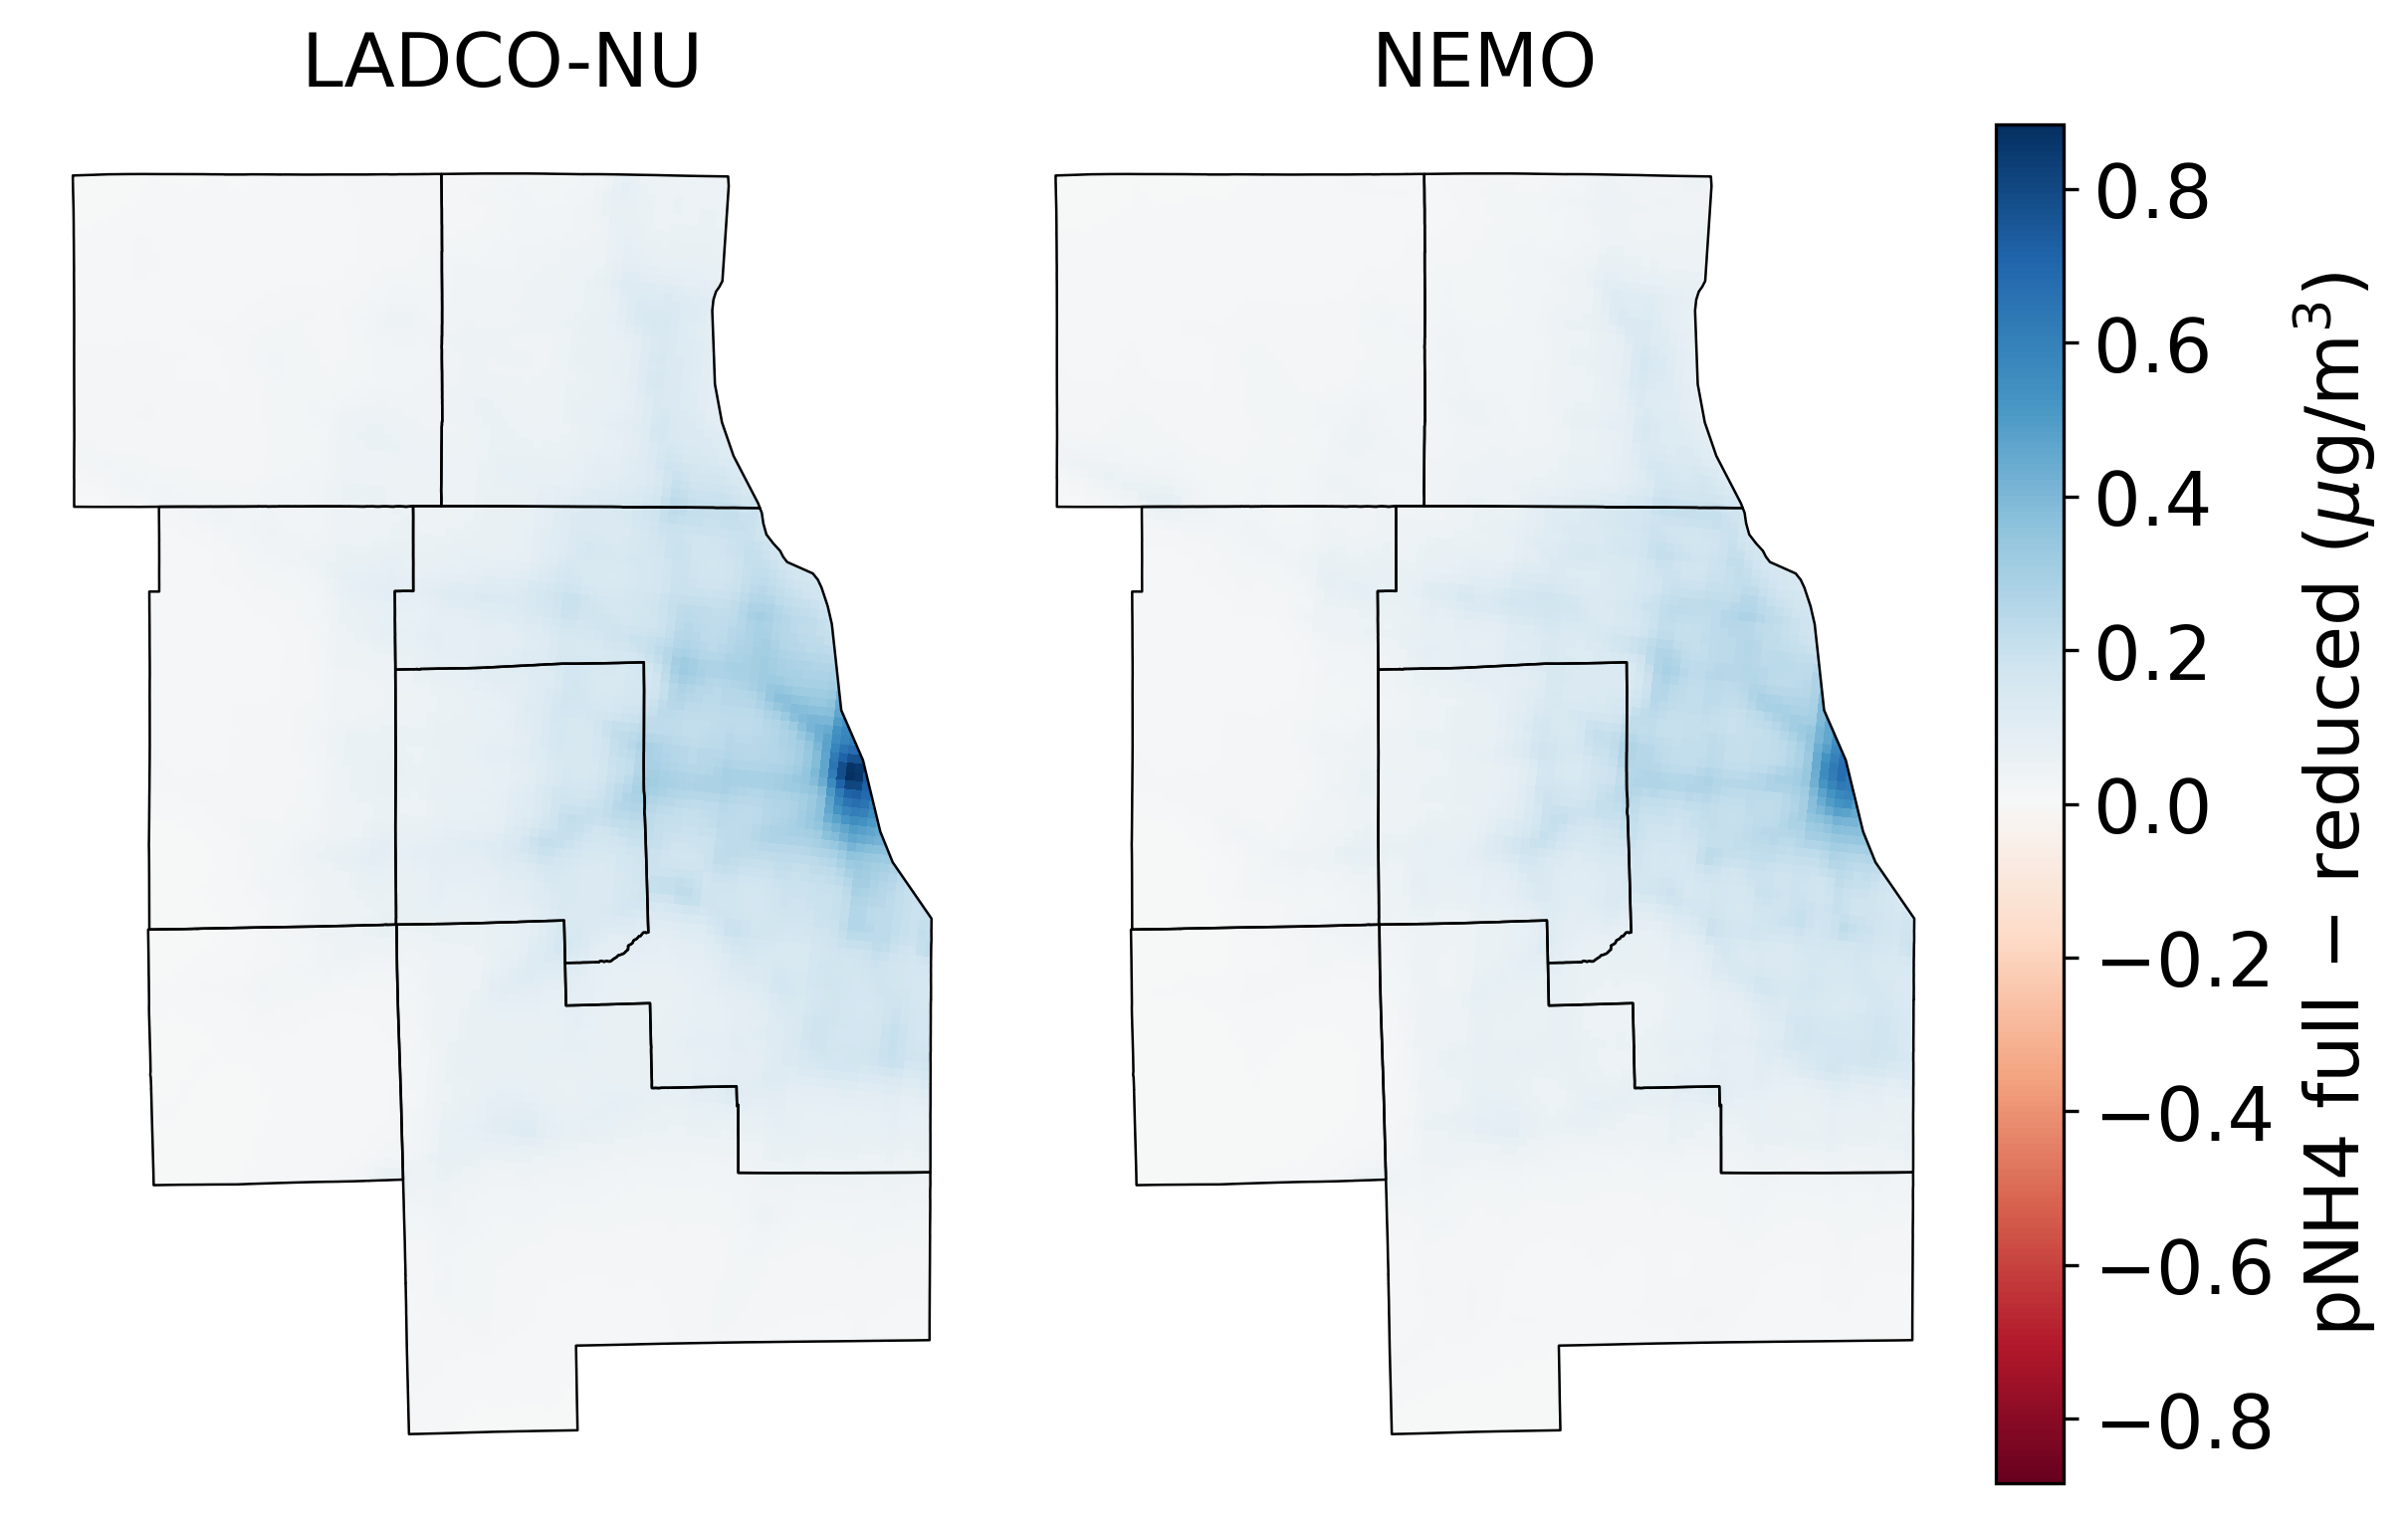

In [12]:
plot_full_vs_secondary_diff_maps([ladco_merged, nemo_merged], chicago_counties_land, res='1 km', column_name="pNH4", emissions_labels=("LADCO-NU", "NEMO"))

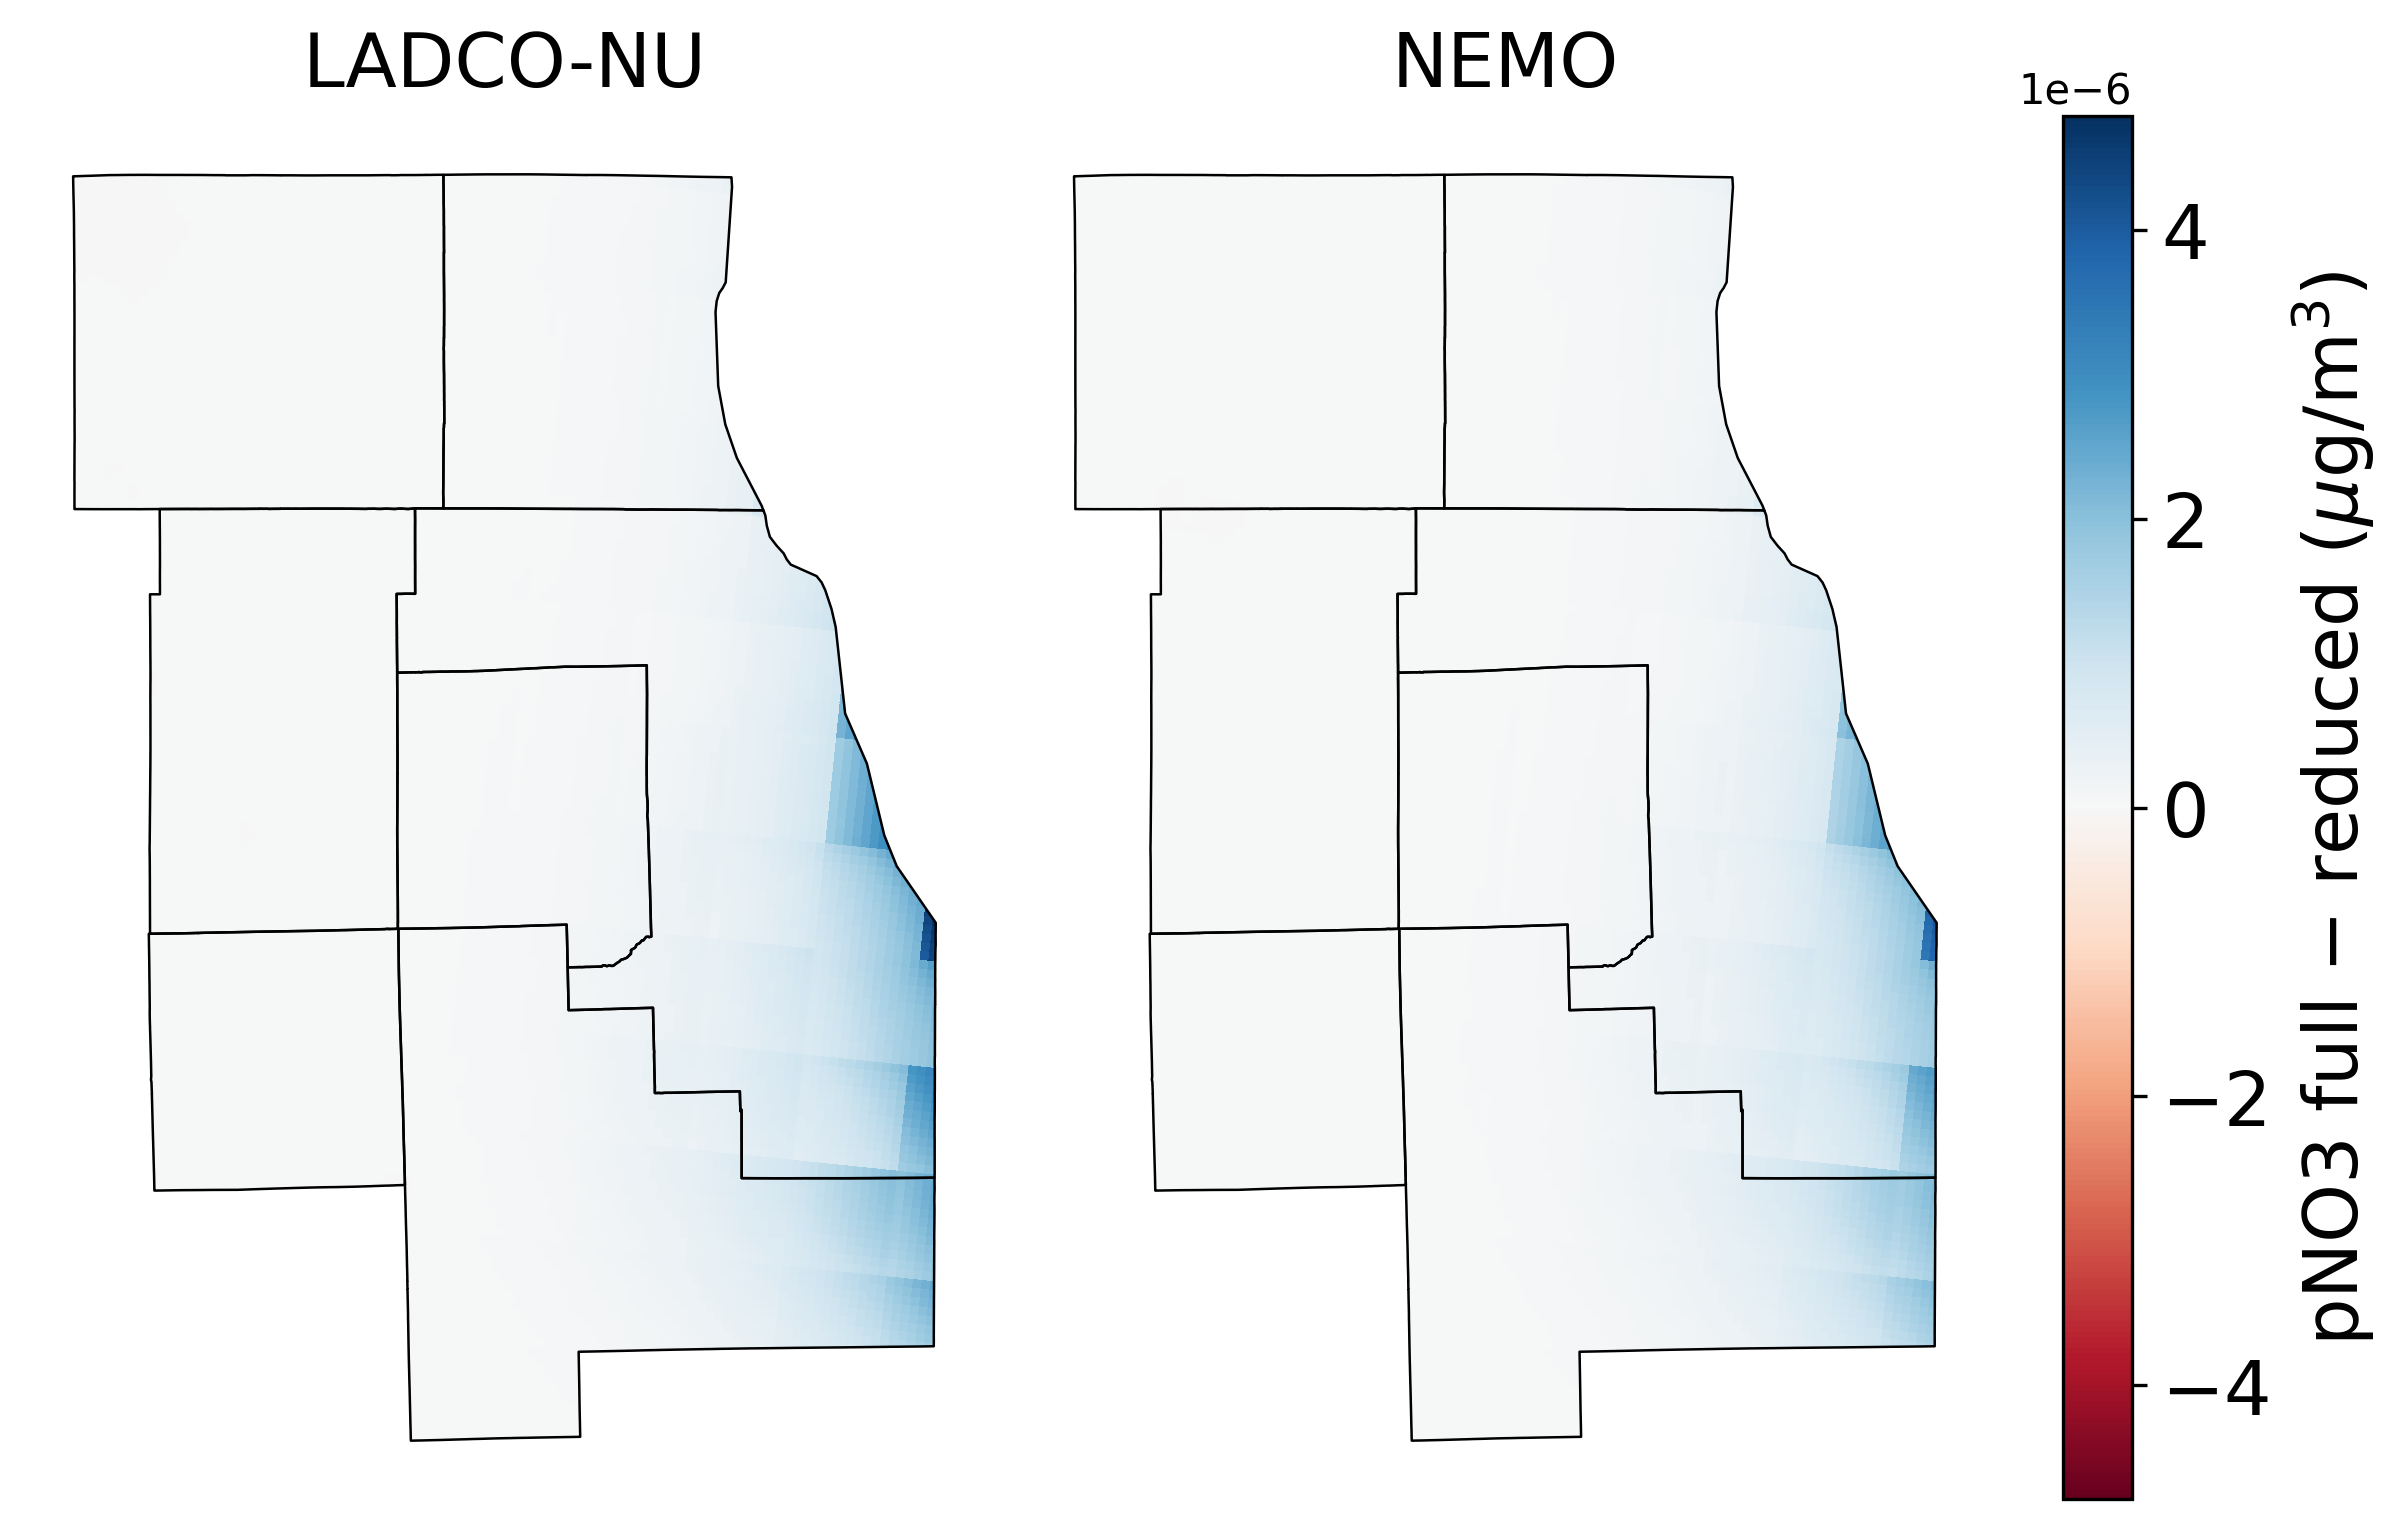

In [13]:
plot_full_vs_secondary_diff_maps([ladco_merged, nemo_merged], chicago_counties_land, res='1 km', column_name="pNO3", emissions_labels=("LADCO-NU", "NEMO"))

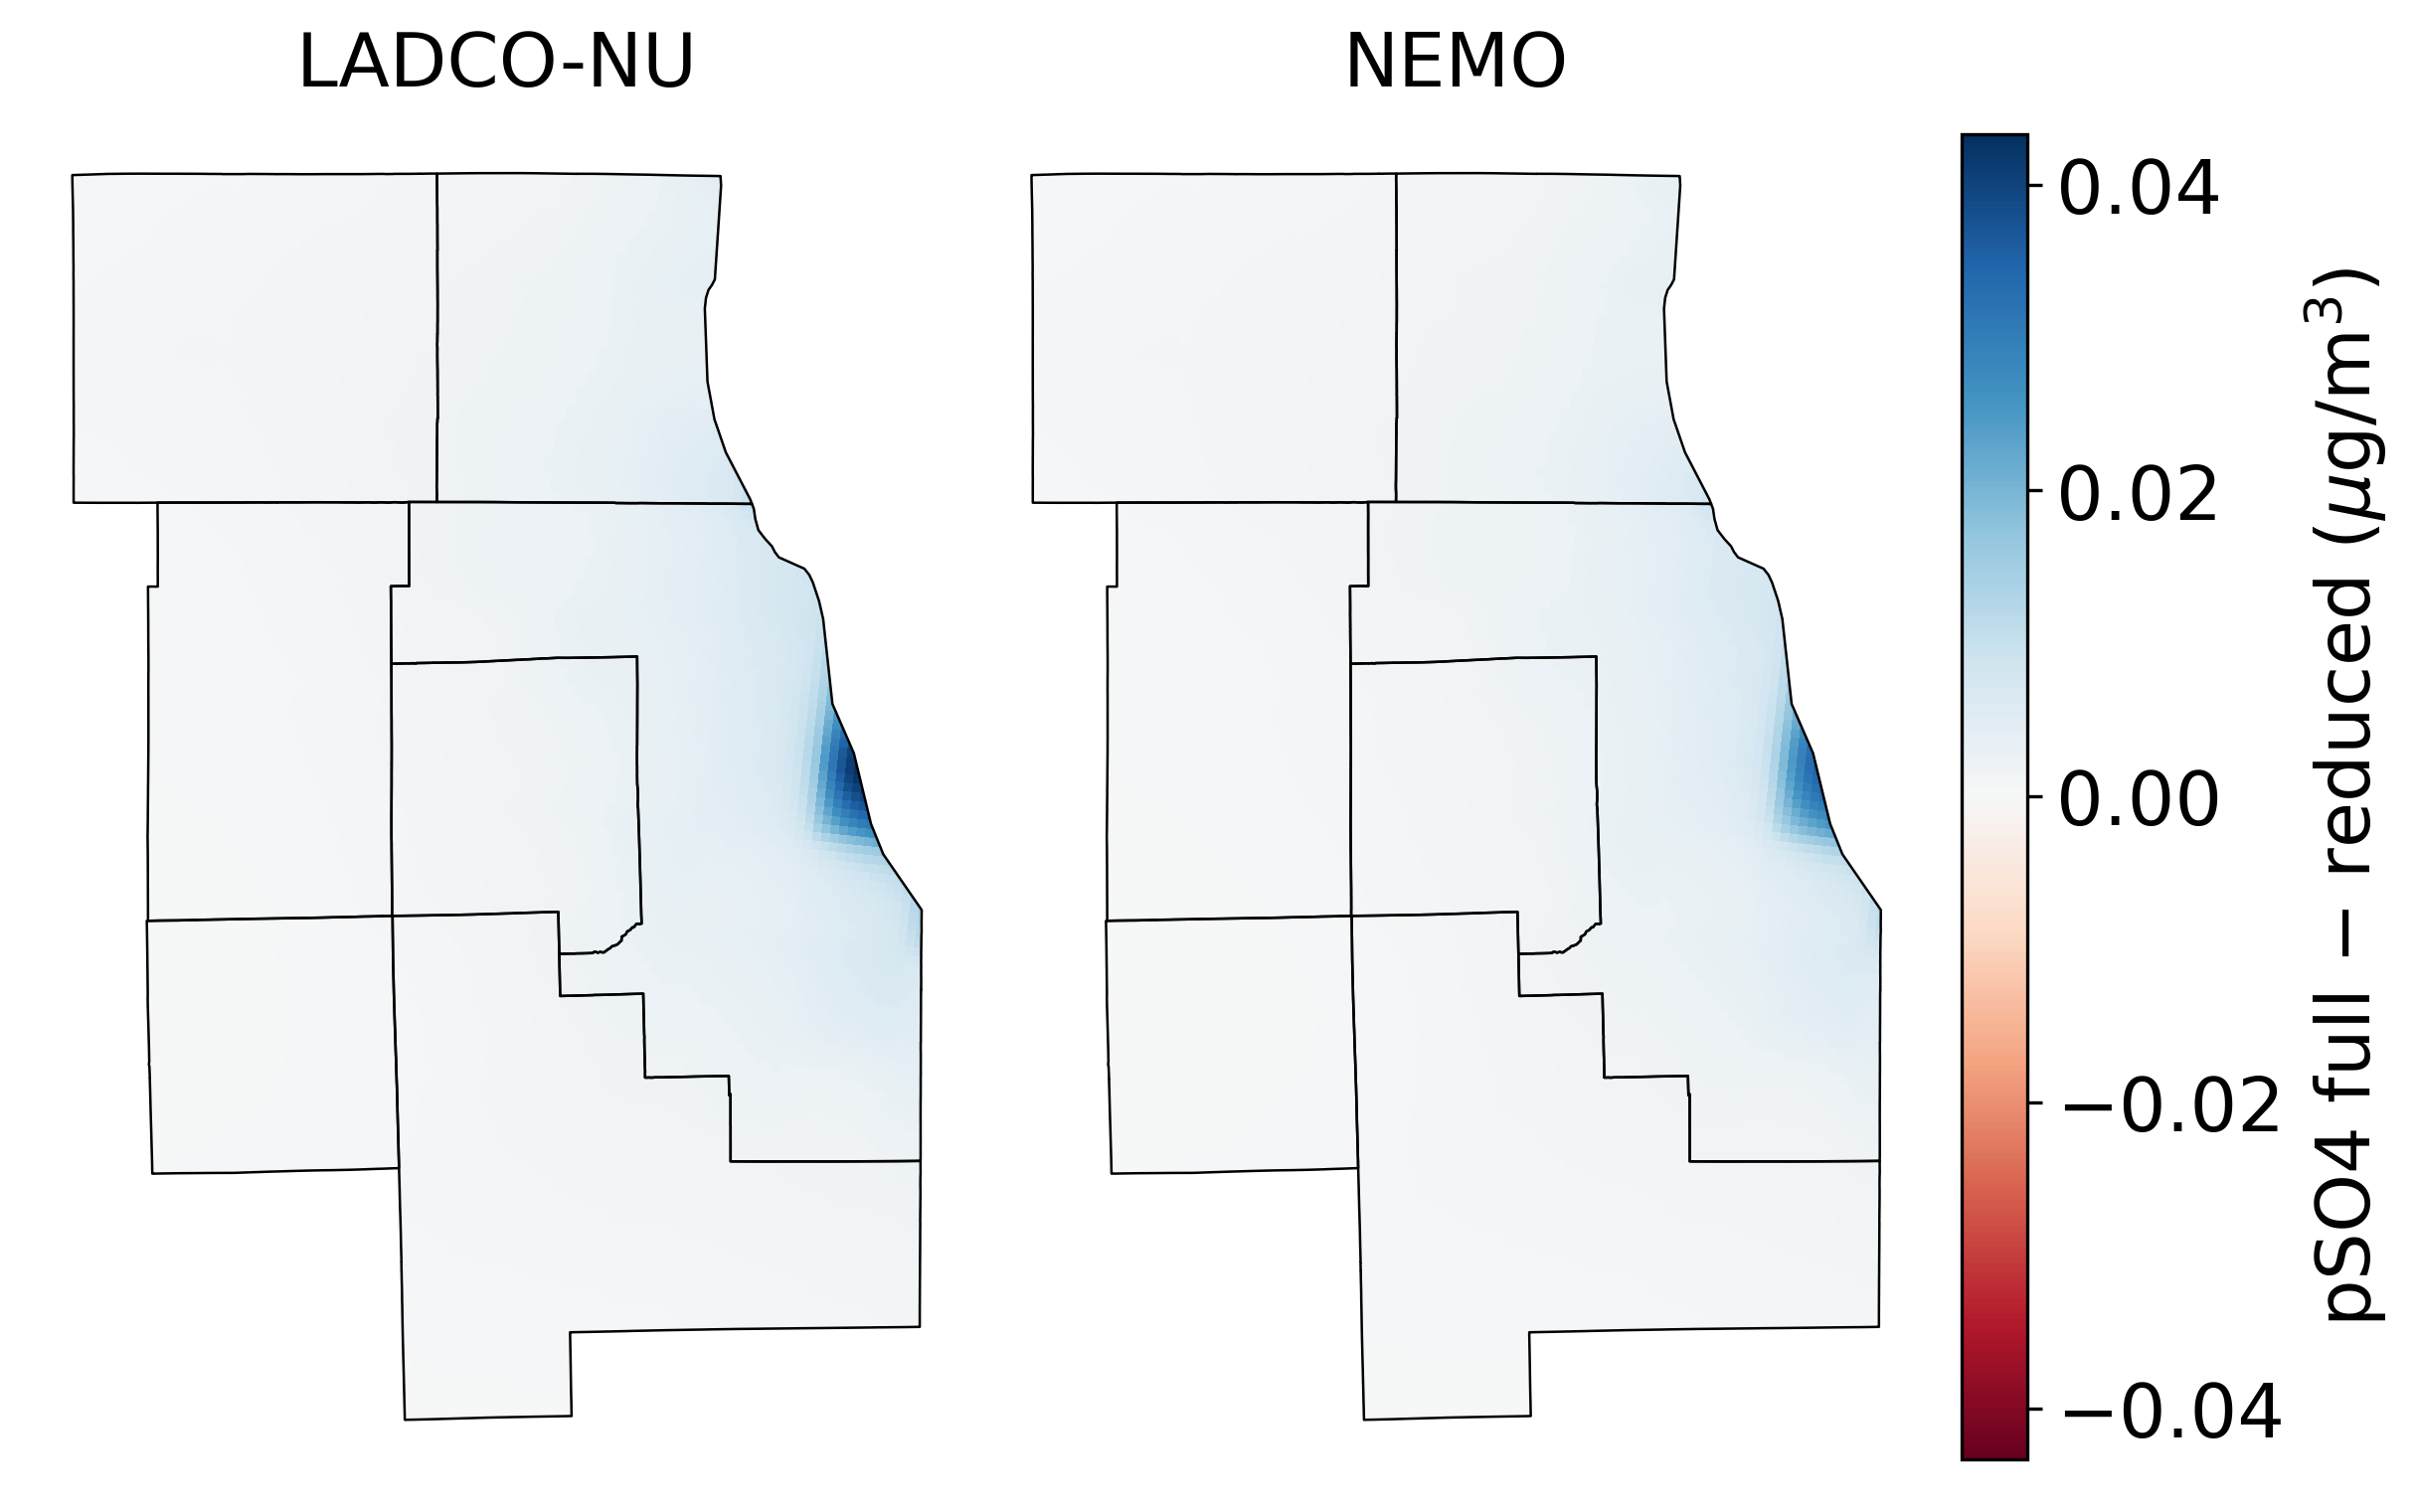

In [14]:
plot_full_vs_secondary_diff_maps([ladco_merged, nemo_merged], chicago_counties_land, res='1 km', column_name="pSO4", emissions_labels=("LADCO-NU", "NEMO"))

In [ ]:
ladco_merged['pNO3']

In [ ]:
plot_full_vs_secondary_diff_maps([ladco_merged, nemo_merged], chicago_counties_land, res='1 km', column_name="TotalPM25", emissions_labels=("LADCO-NU", "NEMO"))

In [ ]:
for gdf in (ladco_merged, nemo_merged):
    ratio = gdf["TotalPM25"] / gdf["TotalPM25_secondary"]
    mean_ratio = gdf["TotalPM25"].sum() / gdf["TotalPM25_secondary"].sum()

    pct_diff = (ratio - mean_ratio) / mean_ratio * 100
    #pct_diff[gdf["TotalPM25"] < 0.1] = 0

    gdf["TotalPM25_pctdiff"] = pct_diff

In [ ]:
def plot_pctdiff_maps(gdfs,
                       chicago_counties_land,
                       res='1 km',
                       column_name="TotalPM25_pctdiff",
                       emissions_labels=("LADCO-NU", "NEMO")):

    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    label = 'PM$_{2.5}$ ratio % diff from mean ratio (%)'

    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    max_abs = max(
        np.abs(gdf[column_name]).max()
        for gdf in gdfs
    )
    vmin, vmax = -max_abs, max_abs

    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(gdfs),
        figsize=(4 * len(gdfs), 5),
        subplot_kw={"projection": target_proj},
        constrained_layout=True,
        dpi=300
    )

    if len(gdfs) == 1:
        axes = [axes]

    for ax, gdf, emis_label in zip(axes, gdfs, emissions_labels):

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap="RdBu",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            antialiased=False,
            rasterized=True,
            legend=False
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.6
        )

        ax.set_title(emis_label.upper(), fontsize=18)
        ax.set_axis_off()

    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.02
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    #fig.suptitle(f"{res} PM$_{{2.5}}$ ratio deviation from mean ratio", fontsize=18)

    plt.show()


plot_pctdiff_maps([ladco_merged, nemo_merged], chicago_counties_land)

In [ ]:
import pandas as pd

def compute_relative_disparities(
    resolution,
    emissions_dict,
    census_race_df,
    emissions_col,
    total_pop_col="Total",
    race_cols=None,
    join_col="GEOID",
    pollutant_name="NOx"
):
    """
    Returns tidy dataframe of relative disparities:
    columns = [resolution, inventory, pollutant, subgroup, relative_disparity]
    """

    if race_cols is None:
        race_cols = {
            "White": "White",
            "Black": "Black",
            "Hispanic": "Hispanic",
            "Asian": "Asian"
        }

    rows = []
    inventories = list(emissions_dict[resolution].keys())

    for inv in inventories:

        emis_gdf = emissions_dict[resolution][inv].copy()

        merged = pd.merge(
            emis_gdf,
            census_race_df[[join_col, total_pop_col] + list(race_cols.values())],
            on=join_col,
            how="inner"
        )

        # domain population-weighted mean
        domain_pw = (
            (merged[emissions_col] * merged[total_pop_col]).sum()
            / merged[total_pop_col].sum()
        )

        for race, col in race_cols.items():

            race_pw = (
                (merged[emissions_col] * merged[col]).sum()
                / merged[col].sum()
            )

            disparity = race_pw / domain_pw

            rows.append({
                "resolution": resolution,
                "inventory": inv.upper(),
                "pollutant": pollutant_name,
                "subgroup": race,
                "relative_disparity": disparity
            })

    return pd.DataFrame(rows)

In [ ]:
relative_disparities_conc_df_pm25 = compute_relative_disparities(
    resolution="1",
    emissions_dict=conc_census_gdfs_dict,
    census_race_df=census_tracts_chicago_race,
    emissions_col="TotalPM25_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)


In [ ]:
with open(f"shapefiles/secondary_pm/tract_concentrations.pkl", "rb") as f:
	tract_secondary = pickle.load(f)
tract_secondary_2 = {'1':{}}
tract_secondary_2['1']['nemo'] = tract_secondary['nemo']
tract_secondary_2['1']['ladco-nu'] = tract_secondary['ladco']

In [ ]:
relative_disparities_conc_df_pm25_sec = compute_relative_disparities(
    resolution="1",
    emissions_dict=tract_secondary_2,
    census_race_df=census_tracts_chicago_race,
    emissions_col="TotalPM25_tract",   # <-- adjust if needed
    pollutant_name="PM2.5"
)


In [ ]:
merge_keys = ["pollutant", "resolution", "inventory", "subgroup"]

relative_disparities_diff_pm25 = relative_disparities_conc_df_pm25.merge(
    relative_disparities_conc_df_pm25_sec,
    on=merge_keys,
    suffixes=("_sec", "_full")
)

In [ ]:
relative_disparities_diff_pm25

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_relative_disparity_diff(
    df,
    pollutant,
    resolution,
    col1,
    col2,
    xlabel = "Relative Disparity Difference (Concentration - Emissions)",
    size=15,
    datatype='Difference',
    figsize=(12, 3)
):

    data = df[
        (df["pollutant"] == pollutant) &
        (df["resolution"].astype(str) == str(resolution))
    ].copy()

    if data.empty:
        raise ValueError("No matching data found for given pollutant/resolution.")

    # ---- Compute difference ----
    data["diff"] = data[col1] - data[col2]

    # Labels
    if pollutant == "PM2.5":
        pollutant_label = "PM$_{2.5}$"
    else:
        pollutant_label = "NO$_x$"

    inventories = ['LADCO-NU', 'NEMO']
    subgroups = sorted(data["subgroup"].unique())

    colors = {
        'White': '#32448A',
        'Black': '#9d94ff',
        'Hispanic': '#ff6961',
        'Asian': '#ffb480',
        'Other': '#77dd77'
    }

    markers = {
        'White': 'o',
        'Black': 's',
        'Hispanic': 'D',
        'Asian': '^',
        'Other': 'X'
    }

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ypos = [0.25, 0.75]
    print(ypos)
    # ---- Plot points ----
    for j, inv in enumerate(inventories):
        inv_data = data[data["inventory"] == inv]

        for _, row in inv_data.iterrows():
            x_val = row["diff"]

            ax.scatter(
                x_val,
                ypos[j],
                s=150,
                marker=markers.get(row["subgroup"], 'o'),
                color=colors.get(row["subgroup"], 'grey'),
                alpha=0.7,
                linewidth=2,
                edgecolor=colors.get(row["subgroup"], 'grey'),
                label=row["subgroup"] if j == 0 else "_nolegend_"
            )

    # ---- Axis scaling (percent difference) ----
    percent_values = data["diff"].values * 100

    min_percent = np.min(percent_values)
    max_percent = np.max(percent_values)

    range_percent = max_percent - min_percent
    step_percent = 2 if range_percent <= 10 else (5 if range_percent <= 30 else 10)

    lower = np.floor(min_percent / step_percent) * step_percent
    upper = np.ceil(max_percent / step_percent) * step_percent

    tick_percents = np.arange(lower, upper + step_percent, step_percent)
    xticks = tick_percents / 100.0

    ax.set_xlim(xticks[0], xticks[-1])
    ax.set_xticks(xticks)

    # Tick labels (centered at 0 now)
    xtick_labels = [
        f"{p/100:.2f}\n({int(p)}%)"
        for p in tick_percents
    ]
    ax.set_xticklabels(xtick_labels, fontsize=size, rotation = 20)
    ax.set_ylim([0, 1])
    # Grid + zero reference line
    ax.grid(axis='x', linestyle='-', alpha=0.25)
    ax.axvline(0, color='k', linestyle='--', linewidth=1)

    # ---- Y axis ----
    ax.set_yticks(ypos)
    ax.set_yticklabels(inventories, fontsize=size)

    ax.set_xlabel(xlabel, fontsize=size)
    ax.set_ylabel("Inventory", fontsize=size)
   # ax.set_title(f"{pollutant_label} {datatype} ({resolution} km)", fontsize=size)

    # ---- Legend ----
    legend_handles = [
        Line2D(
            [0], [0],
            marker=markers[g],
            color='w',
            markerfacecolor=colors[g],
            markersize=15,
            label=g
        )
        for g in subgroups
    ]

    ax.legend(
        handles=legend_handles,
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=size
    )

    plt.tight_layout()
    plt.show()

In [ ]:
relative_disparities_diff_pm25

In [ ]:


plot_relative_disparity_diff(
    relative_disparities_diff_pm25,
    pollutant="PM2.5",
    resolution="1",
    col1="relative_disparity_full",
    col2="relative_disparity_sec",
    xlabel="Relative Disparity Difference (Full $-$ PM+NO$_x$ only)",
    datatype="Full vs. Reduced Precursor Difference"
)

In [ ]:
ladco_old = gpd.read_file('/projects/b1045/inmap/emissions_intercomparison/adjusted_units/ladco_1km_cons_annual_modified.shp')
ladco_new = gpd.read_file('/projects/b1045/inmap/shlipak_runs/emissions/ladco_secondary.shp')

In [ ]:
ladco_old['NOX'].max()/ladco_new['NOX'].max()

In [ ]:
4.566209102209176

In [ ]:
ladco_old['NOX'].mean()/ladco_new['NOX'].mean()

In [ ]:
ladco_old['PM25'].mean()/ladco_new['PM25'].mean()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

def white_magma_r():
    base = plt.cm.magma_r

    n = 256
    colors = base(np.linspace(0, 1, n))

    # create a smooth fade-in from white to first magma color
    white = np.array([1, 1, 1, 1])
    ramp_n = 40  # controls how quickly white fades into magma

    ramp = np.linspace(0, 1, ramp_n)
    for i, t in enumerate(ramp):
        colors[i] = (1 - t) * white + t * colors[ramp_n]

    return LinearSegmentedColormap.from_list(
        "white_magma_r",
        colors
    )

def plot_emissions_inventories(
    dict_gdfs,        # dict like {'nemo': gdf, 'ladco': gdf, 'five': gdf}
    chicago_counties_land,
    column_name="PM2_5",
    vmin=None,
    vmax=None
):
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs

    # ---- labels ----
    if column_name == 'TotalPM25':
        pollutant = 'Total PM$_{2.5}$'
        unit = '($\\mu$g/m$^{3}$)'
    elif column_name == 'NOx':
        pollutant = 'NO$_{x}$'
        unit = '($\\mu$g/s)'
    elif column_name == 'PrimPM2_5':
        pollutant = 'Primary PM$_{2.5}$'
        unit = '(tons/year)'
    else:
        pollutant = column_name
        unit = ''

    label = pollutant + ' ' + unit

    # ---- projection ----
    target_proj = ccrs.LambertConformal(
        central_longitude=-97,
        central_latitude=40,
        standard_parallels=(33, 45)
    )

    # ---- color scale ----
    if vmin is None or vmax is None:
        max_abs = max(gdf[column_name].max() for gdf in dict_gdfs.values())
        vmin = 0
        vmax = max_abs

    inventories = ['nemo','ladco']

    # ---- figure (1x3) ----
    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(13, 6),
        dpi=300,
        subplot_kw={"projection": target_proj},
        constrained_layout=True
    )

    label_starts = ['A', 'B']
    im = None
    for j, (inv, ax) in enumerate(zip(inventories, axes)):
        gdf = dict_gdfs[inv]

        im = gdf.plot(
            column=column_name,
            ax=ax,
            transform=target_proj,
            cmap=white_magma_r(),
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            linewidth=0,
            rasterized=True
        )

        chicago_counties_land.boundary.plot(
            ax=ax,
            transform=target_proj,
            color="black",
            linewidth=0.6
        )

        ax.set_title(f"{label_starts[j]} {inv.upper()}", fontsize=18)
        ax.set_axis_off()

    # ---- shared colorbar ----
    cbar = fig.colorbar(
        im.collections[0],
        ax=axes,
        orientation="vertical",
        fraction=0.02,
        pad=0.02,
        extend='max'
    )
    cbar.set_label(label, fontsize=18)
    cbar.ax.tick_params(labelsize=18)

    plt.show()

In [ ]:
gdfs_dict['1']['nemo']['TotalPM25'].sum()/gdfs_dict['1']['nemo']['PrimPM25'].sum()

In [ ]:
secondary_conc['nemo']['TotalPM25'].sum()/secondary_conc['nemo']['PrimPM25'].sum()

In [ ]:
gdfs_dict['1']['nemo']['PM_ratio'] = gdfs_dict['1']['nemo']['TotalPM25']/gdfs_dict['1']['nemo']['PrimPM25']
gdfs_dict['1']['ladco-nu']['PM_ratio'] = gdfs_dict['1']['ladco-nu']['TotalPM25']/gdfs_dict['1']['ladco-nu']['PrimPM25']

In [ ]:
gdfs_dict['1']['ladco'] = gdfs_dict['1']['ladco-nu']

In [ ]:
secondary_conc['nemo']['PM_ratio'] = secondary_conc['nemo']['TotalPM25']/secondary_conc['nemo']['PrimPM25']
secondary_conc['ladco']['PM_ratio'] = secondary_conc['ladco']['TotalPM25']/secondary_conc['ladco']['PrimPM25']

In [ ]:
plot_emissions_inventories(
    gdfs_dict['1'],        # dict like {'nemo': gdf, 'ladco': gdf, 'five': gdf}
    chicago_counties_land,
    column_name="PM_ratio",
    vmin=0,
    vmax=5
)

In [ ]:
plot_emissions_inventories(
    secondary_conc,        # dict like {'nemo': gdf, 'ladco': gdf, 'five': gdf}
    chicago_counties_land,
    column_name="PM_ratio",
    vmin=0,
    vmax=5
)

In [ ]:
plot_emissions_inventories(
    secondary_conc,        # dict like {'nemo': gdf, 'ladco': gdf, 'five': gdf}
    chicago_counties_land,
    column_name="TotalPM25",
    vmin=0,
    vmax=2
)

In [ ]:
plot_emissions_inventories(
    secondary_conc,        # dict like {'nemo': gdf, 'ladco': gdf, 'five': gdf}
    chicago_counties_land,
    column_name="PrimPM25",
    vmin=0,
    vmax=1
)

In [ ]:
gdfs_dict['1']['nemo'] secondary_conc['nemo']

In [ ]:
secondary_conc['ladco']['PrimPM25'].corr(secondary_conc['ladco']['TotalPM25'])

In [ ]:
secondary_conc['nemo']['PrimPM25'].corr(secondary_conc['nemo']['TotalPM25'])

In [ ]:
nemo_merged = gdfs_dict['1']['nemo'].merge(
    secondary_conc['nemo'],
    on='geometry', suffixes=('_primary', '_secondary')
)

In [ ]:
nemo_merged['PrimPM25_primary'].corr(nemo_merged['PrimPM25_secondary'])

In [ ]:
nemo_merged['TotalPM25_primary'].corr(nemo_merged['TotalPM25_secondary'])

In [ ]:
nemo_merged['TotalPM25_primary'].corr(nemo_merged['PrimPM25_primary'])

In [ ]:
nemo_merged['TotalPM25_secondary'].corr(nemo_merged['PrimPM25_secondary'])

In [ ]:
(nemo_merged['PrimPM25_primary']/nemo_merged['PrimPM25_secondary']).mean()

In [ ]:
ladco_merged = gdfs_dict['1']['ladco-nu'].merge(
    secondary_conc['ladco'],
    on='geometry', suffixes=('_primary', '_secondary')
)

In [ ]:
(ladco_merged['PrimPM25_primary']/ladco_merged['PrimPM25_secondary']).mean()